In [1]:
# ============================================================
# CELL 1 — IMPORTS + MEMORY-SAFE CONFIGURATION
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import mixed_precision

# ------------------------------------------------------------
# RANDOM SEED
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# CLEAR OLD MEMORY
# ------------------------------------------------------------

tf.keras.backend.clear_session()
gc.collect()

# ------------------------------------------------------------
# GPU INFORMATION
# ------------------------------------------------------------

gpus = tf.config.list_physical_devices("GPU")

print("=" * 70)
print("SYSTEM CONFIGURATION")
print("=" * 70)

print("TensorFlow version :", tf.__version__)
print("GPUs available     :", len(gpus))

for i, gpu in enumerate(gpus):
    print(f"GPU {i}              :", gpu)

# ------------------------------------------------------------
# ENABLE GPU MEMORY GROWTH
# ------------------------------------------------------------

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(
            gpu,
            True
        )
    except RuntimeError:
        pass

# ------------------------------------------------------------
# MIXED PRECISION
# ------------------------------------------------------------

mixed_precision.set_global_policy(
    "mixed_float16"
)

print(
    "Mixed precision    :",
    mixed_precision.global_policy()
)

print("=" * 70)
print("✅ CELL 1 COMPLETED")
print("=" * 70)

SYSTEM CONFIGURATION
TensorFlow version : 2.20.0
GPUs available     : 2
GPU 0              : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
GPU 1              : PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
Mixed precision    : <DTypePolicy "mixed_float16">
✅ CELL 1 COMPLETED


In [3]:
# ============================================================
# CELL 2 — DATASET INSPECTION
# ============================================================

DATASET_PATH = "/kaggle/input/datasets/evangelinnisha/dataset9"

IMAGE_ROOT = os.path.join(
    DATASET_PATH,
    "combined_images"
)

print("=" * 70)
print("DATASET 9 — INITIAL INSPECTION")
print("=" * 70)

print("Dataset path:")
print(DATASET_PATH)

print("\nImage root:")
print(IMAGE_ROOT)

print("\nPath exists:", os.path.exists(DATASET_PATH))
print("Image root exists:", os.path.exists(IMAGE_ROOT))

print("\n" + "=" * 70)
print("ORIGINAL CLASS COUNTS")
print("=" * 70)

original_classes = [
    "ModerateDemented",
    "NonDemented",
    "VeryMildDemented",
    "MildDemented"
]

for class_name in original_classes:

    class_path = os.path.join(
        IMAGE_ROOT,
        class_name
    )

    if os.path.exists(class_path):

        files = [
            f for f in os.listdir(class_path)
            if os.path.isfile(
                os.path.join(class_path, f)
            )
        ]

        print(
            f"{class_name:<20}: {len(files):>6}"
        )

    else:
        print(
            f"{class_name:<20}: NOT FOUND"
        )

print("=" * 70)

DATASET 9 — INITIAL INSPECTION
Dataset path:
/kaggle/input/datasets/evangelinnisha/dataset9

Image root:
/kaggle/input/datasets/evangelinnisha/dataset9/combined_images

Path exists: True
Image root exists: True

ORIGINAL CLASS COUNTS
ModerateDemented    :  10000
NonDemented         :  12800
VeryMildDemented    :  11200
MildDemented        :  10000


In [4]:
# ============================================================
# CELL 3 — REDUCE DATASET
# EXACTLY 4,000 IMAGES PER ORIGINAL CLASS
# ============================================================

SAMPLES_PER_CLASS = 4000

binary_mapping = {
    "NonDemented": 0,
    "VeryMildDemented": 1,
    "MildDemented": 1,
    "ModerateDemented": 1
}

records = []

rng = np.random.default_rng(SEED)

print("=" * 70)
print("SELECTING 4,000 IMAGES PER ORIGINAL CLASS")
print("=" * 70)

for class_name in original_classes:

    class_path = os.path.join(
        IMAGE_ROOT,
        class_name
    )

    files = []

    for filename in os.listdir(class_path):

        filepath = os.path.join(
            class_path,
            filename
        )

        if os.path.isfile(filepath):
            files.append(filepath)

    print(
        f"{class_name:<20}: "
        f"{len(files):>6} available"
    )

    if len(files) < SAMPLES_PER_CLASS:

        raise ValueError(
            f"{class_name} has only "
            f"{len(files)} images."
        )

    selected_files = rng.choice(
        files,
        size=SAMPLES_PER_CLASS,
        replace=False
    )

    for filepath in selected_files:

        records.append({
            "filepath": filepath,
            "original_class": class_name,
            "binary_label": binary_mapping[class_name]
        })


# ------------------------------------------------------------
# CREATE DATAFRAME
# ------------------------------------------------------------

df = pd.DataFrame(records)

df = df.sample(
    frac=1.0,
    random_state=SEED
).reset_index(drop=True)

print("\n" + "=" * 70)
print("REDUCED DATASET SUMMARY")
print("=" * 70)

print("Total images:", len(df))

print("\nOriginal classes:")
print(
    df["original_class"]
    .value_counts()
    .reindex(original_classes)
)

print("\nBinary classes:")
print(
    df["binary_label"]
    .value_counts()
    .sort_index()
)

print("\nBinary mapping:")
print("0 = Normal")
print("1 = AD Impaired")

print("=" * 70)
print("✅ 16,000 IMAGE DATASET CREATED")
print("=" * 70)

SELECTING 4,000 IMAGES PER ORIGINAL CLASS
ModerateDemented    :  10000 available
NonDemented         :  12800 available
VeryMildDemented    :  11200 available
MildDemented        :  10000 available

REDUCED DATASET SUMMARY
Total images: 16000

Original classes:
original_class
ModerateDemented    4000
NonDemented         4000
VeryMildDemented    4000
MildDemented        4000
Name: count, dtype: int64

Binary classes:
binary_label
0     4000
1    12000
Name: count, dtype: int64

Binary mapping:
0 = Normal
1 = AD Impaired
✅ 16,000 IMAGE DATASET CREATED


In [5]:
# ============================================================
# CELL 4 — STRATIFIED 70 / 15 / 15 SPLIT
# ============================================================

# ------------------------------------------------------------
# FIRST SPLIT
# 70% TRAIN
# 30% TEMP
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["binary_label"],
    random_state=SEED
)

# ------------------------------------------------------------
# SECOND SPLIT
# 15% VALIDATION
# 15% TEST
# ------------------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["binary_label"],
    random_state=SEED
)

# ------------------------------------------------------------
# RESET INDEX
# ------------------------------------------------------------

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("=" * 70)
print("STRATIFIED DATA SPLIT")
print("=" * 70)

print(
    f"Training   : {len(train_df)}"
)

print(
    f"Validation : {len(val_df)}"
)

print(
    f"Test       : {len(test_df)}"
)

print("\nTraining distribution:")
print(
    train_df["binary_label"]
    .value_counts()
    .sort_index()
)

print("\nValidation distribution:")
print(
    val_df["binary_label"]
    .value_counts()
    .sort_index()
)

print("\nTest distribution:")
print(
    test_df["binary_label"]
    .value_counts()
    .sort_index()
)

STRATIFIED DATA SPLIT
Training   : 11200
Validation : 2400
Test       : 2400

Training distribution:
binary_label
0    2800
1    8400
Name: count, dtype: int64

Validation distribution:
binary_label
0     600
1    1800
Name: count, dtype: int64

Test distribution:
binary_label
0     600
1    1800
Name: count, dtype: int64


In [6]:
# ============================================================
# CELL 5 — DATA LEAKAGE CHECK
# ============================================================

train_paths = set(
    train_df["filepath"]
)

val_paths = set(
    val_df["filepath"]
)

test_paths = set(
    test_df["filepath"]
)

train_val_overlap = (
    train_paths.intersection(val_paths)
)

train_test_overlap = (
    train_paths.intersection(test_paths)
)

val_test_overlap = (
    val_paths.intersection(test_paths)
)

print("=" * 70)
print("DATA LEAKAGE CHECK")
print("=" * 70)

print(
    "Train ∩ Validation :",
    len(train_val_overlap)
)

print(
    "Train ∩ Test       :",
    len(train_test_overlap)
)

print(
    "Validation ∩ Test  :",
    len(val_test_overlap)
)

if (
    len(train_val_overlap) == 0
    and
    len(train_test_overlap) == 0
    and
    len(val_test_overlap) == 0
):

    print("\n✅ NO DATA LEAKAGE DETECTED")

else:

    print("\n❌ DATA LEAKAGE DETECTED")

print("=" * 70)

DATA LEAKAGE CHECK
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ NO DATA LEAKAGE DETECTED


In [7]:
# ============================================================
# CELL 6 — MEMORY-SAFE TF.DATA DATASETS
# ============================================================

IMG_SIZE = (224, 224)

# IMPORTANT:
# Small batch size to prevent kernel crashes
BATCH_SIZE = 8


def load_image(filepath, label):

    # Read image
    image = tf.io.read_file(filepath)

    # Decode RGB
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Allow variable original image dimensions
    image.set_shape(
        [None, None, 3]
    )

    # Resize
    image = tf.image.resize(
        image,
        IMG_SIZE,
        method="bilinear"
    )

    # Float32
    image = tf.cast(
        image,
        tf.float32
    )

    return image, label


# ============================================================
# TRAIN DATASET
# ============================================================

train_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_df["filepath"].values,
        train_df["binary_label"]
        .values
        .astype("float32")
    )
)

train_ds = train_ds.shuffle(
    buffer_size=len(train_df),
    seed=SEED,
    reshuffle_each_iteration=True
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=1
)

train_ds = train_ds.batch(
    BATCH_SIZE,
    drop_remainder=True
)

train_ds = train_ds.prefetch(1)


# ============================================================
# VALIDATION DATASET
# ============================================================

val_ds = tf.data.Dataset.from_tensor_slices(
    (
        val_df["filepath"].values,
        val_df["binary_label"]
        .values
        .astype("float32")
    )
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=1
)

val_ds = val_ds.batch(
    BATCH_SIZE
)

val_ds = val_ds.prefetch(1)


# ============================================================
# TEST DATASET
# ============================================================

test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_df["filepath"].values,
        test_df["binary_label"]
        .values
        .astype("float32")
    )
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=1
)

test_ds = test_ds.batch(
    BATCH_SIZE
)

test_ds = test_ds.prefetch(1)


# ============================================================
# VERIFY
# ============================================================

print("=" * 70)
print("TF.DATA DATASETS CREATED")
print("=" * 70)

print("Training samples   :", len(train_df))
print("Validation samples :", len(val_df))
print("Test samples       :", len(test_df))
print("Image size         :", IMG_SIZE)
print("Batch size         :", BATCH_SIZE)

sample_images, sample_labels = next(
    iter(train_ds)
)

print("\nBatch image shape :", sample_images.shape)
print("Batch label shape :", sample_labels.shape)
print("Image dtype       :", sample_images.dtype)
print(
    "Image range       :",
    float(tf.reduce_min(sample_images)),
    "to",
    float(tf.reduce_max(sample_images))
)

print(
    "Labels            :",
    np.unique(sample_labels.numpy())
)

print("\n✅ DATASETS READY")

I0000 00:00:1791777134.233340      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791777134.238797      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


TF.DATA DATASETS CREATED
Training samples   : 11200
Validation samples : 2400
Test samples       : 2400
Image size         : (224, 224)
Batch size         : 8

Batch image shape : (8, 224, 224, 3)
Batch label shape : (8,)
Image dtype       : <dtype: 'float32'>
Image range       : 0.0 to 255.0
Labels            : [0. 1.]

✅ DATASETS READY


In [8]:
# ============================================================
# CELL 7 — TRAINING-ONLY AUGMENTATION
# ============================================================

data_augmentation = tf.keras.Sequential([

    layers.RandomRotation(
        factor=0.03,
        fill_mode="nearest"
    ),

    layers.RandomZoom(
        height_factor=(-0.08, 0.08),
        width_factor=(-0.08, 0.08),
        fill_mode="nearest"
    ),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="nearest"
    ),

    layers.RandomContrast(
        factor=0.10
    ),

    # Small Gaussian noise
    layers.GaussianNoise(
        stddev=0.02
    )

], name="Training_Only_Augmentation_With_Noise")

print("=" * 70)
print("TRAINING AUGMENTATION READY")
print("=" * 70)

print(data_augmentation)

TRAINING AUGMENTATION READY
<Sequential name=Training_Only_Augmentation_With_Noise, built=False>


In [9]:
# ============================================================
# CELL 8 — BCFedARFR-ApeNet CORE MODEL
#
# EfficientNetB0
#       ↓
# ARFR
#       ↓
# Coordinate Attention
#       ↓
# Global Average Pooling
#       ↓
# Dense
#       ↓
# Sigmoid
# ============================================================

# Clear previous model memory
tf.keras.backend.clear_session()
gc.collect()


# ============================================================
# INPUT
# ============================================================

INPUT_SHAPE = (224, 224, 3)

inputs = layers.Input(
    shape=INPUT_SHAPE,
    name="MRI_Input"
)


# ============================================================
# TRAINING-ONLY AUGMENTATION
# ============================================================

x = data_augmentation(inputs)


# ============================================================
# EfficientNetB0
# ============================================================

backbone = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=INPUT_SHAPE
)

# Freeze backbone initially
backbone.trainable = False

x = backbone(
    x,
    training=False
)

print(
    "EfficientNetB0 output:",
    x.shape
)


# ============================================================
# ARFR
# ============================================================

arfr_main = layers.Conv2D(
    filters=1280,
    kernel_size=3,
    padding="same",
    use_bias=False,
    name="ARFR_Conv"
)(x)

arfr_main = layers.BatchNormalization(
    name="ARFR_BN"
)(arfr_main)

arfr_main = layers.Activation(
    "swish",
    name="ARFR_Activation"
)(arfr_main)


# Residual branch

arfr_residual = layers.Conv2D(
    filters=1280,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="ARFR_Residual"
)(x)

arfr_residual = layers.BatchNormalization(
    name="ARFR_Residual_BN"
)(arfr_residual)


# Residual fusion

x = layers.Add(
    name="ARFR_Residual_Add"
)([
    arfr_main,
    arfr_residual
])

x = layers.Activation(
    "swish",
    name="ARFR_Output"
)(x)


# ============================================================
# COORDINATE ATTENTION
# ============================================================

def coordinate_attention(
    x,
    reduction=32,
    name="CoordinateAttention"
):

    channels = int(x.shape[-1])

    # Height pooling

    h_pool = layers.Lambda(
        lambda t: tf.reduce_mean(
            t,
            axis=2,
            keepdims=True
        ),
        name=f"{name}_HeightPool"
    )(x)

    # Width pooling

    w_pool = layers.Lambda(
        lambda t: tf.reduce_mean(
            t,
            axis=1,
            keepdims=True
        ),
        name=f"{name}_WidthPool"
    )(x)

    # Width transpose

    w_pool = layers.Permute(
        (2, 1, 3),
        name=f"{name}_WidthTranspose"
    )(w_pool)

    # Concatenate

    y = layers.Concatenate(
        axis=1,
        name=f"{name}_Concat"
    )([
        h_pool,
        w_pool
    ])

    # Bottleneck

    reduced_channels = max(
        8,
        channels // reduction
    )

    y = layers.Conv2D(
        filters=reduced_channels,
        kernel_size=1,
        padding="same",
        use_bias=False,
        name=f"{name}_Bottleneck"
    )(y)

    y = layers.BatchNormalization(
        name=f"{name}_BN"
    )(y)

    y = layers.Activation(
        "swish",
        name=f"{name}_Activation"
    )(y)

    # Split

    h_att, w_att = layers.Lambda(
        lambda t: tf.split(
            t,
            num_or_size_splits=2,
            axis=1
        ),
        name=f"{name}_Split"
    )(y)

    # Height attention

    h_att = layers.Conv2D(
        filters=channels,
        kernel_size=1,
        padding="same",
        activation="sigmoid",
        name=f"{name}_HeightAttention"
    )(h_att)

    # Width attention

    w_att = layers.Permute(
        (2, 1, 3),
        name=f"{name}_WidthAttentionTranspose"
    )(w_att)

    w_att = layers.Conv2D(
        filters=channels,
        kernel_size=1,
        padding="same",
        activation="sigmoid",
        name=f"{name}_WidthAttention"
    )(w_att)

    # Apply attention

    output = layers.Multiply(
        name=f"{name}_Output"
    )([
        x,
        h_att,
        w_att
    ])

    return output


x = coordinate_attention(
    x,
    reduction=32,
    name="CoordinateAttention"
)


# ============================================================
# CLASSIFICATION HEAD
# ============================================================

x = layers.GlobalAveragePooling2D(
    name="GlobalAveragePooling"
)(x)

x = layers.Dense(
    256,
    activation="swish",
    name="Classifier_Dense"
)(x)

x = layers.Dropout(
    0.35,
    name="Classifier_Dropout"
)(x)


# IMPORTANT:
# float32 output for numerical stability with mixed precision

outputs = layers.Dense(
    1,
    activation="sigmoid",
    dtype="float32",
    name="AD_Probability"
)(x)


# ============================================================
# CREATE MODEL
# ============================================================

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="BCFedARFR_ApeNet_Core"
)


# ============================================================
# COMPILE
# ============================================================

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss="binary_crossentropy",

    metrics=[

        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        ),

        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)


# ============================================================
# MODEL INFORMATION
# ============================================================

print("\n" + "=" * 70)
print("MODEL CREATED SUCCESSFULLY")
print("=" * 70)

print("Model name        :", model.name)
print("Input shape       :", model.input_shape)
print("Output shape      :", model.output_shape)
print("Total parameters  :", model.count_params())
print("Backbone trainable:", backbone.trainable)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 output: (None, 7, 7, 1280)

MODEL CREATED SUCCESSFULLY
Model name        : BCFedARFR_ApeNet_Core
Input shape       : (None, 224, 224, 3)
Output shape      : (None, 1)
Total parameters  : 20928324
Backbone trainable: False


Model: "BCFedARFR_ApeNet_Core"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ MRI_Input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Training_Only_Augm… │ (None, 224, 224,  │          0 │ MRI_Input[0][0]   │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ Training_Only_Au… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Conv (Conv2D)  │ (None, 7, 7,      │ 14,745,600 │ efficientnetb0[0… │
│                     │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_BN             │ (None, 7, 7,      │      5,120 │ ARFR_Conv[0][0]   │
│ (BatchNormalizatio… │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Residual       │ (None, 7, 7,      │  1,638,400 │ efficientnetb0[0… │
│ (Conv2D)            │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Activation     │ (None, 7, 7,      │          0 │ ARFR_BN[0][0]     │
│ (Activation)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Residual_BN    │ (None, 7, 7,      │      5,120 │ ARFR_Residual[0]… │
│ (BatchNormalizatio… │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Residual_Add   │ (None, 7, 7,      │          0 │ ARFR_Activation[… │
│ (Add)               │ 1280)             │            │ ARFR_Residual_BN… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Output         │ (None, 7, 7,      │          0 │ ARFR_Residual_Ad… │
│ (Activation)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CoordinateAttentio… │ (None, 1, 7,      │          0 │ ARFR_Output[0][0] │
│ (Lambda)            │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CoordinateAttentio… │ (None, 7, 1,      │          0 │ ARFR_Output[0][0] │
│ (Lambda)            │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CoordinateAttentio… │ (None, 7, 1,      │          0 │ CoordinateAttent… │
│ (Permute)           │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CoordinateAttentio… │ (None, 14, 1,     │          0 │ CoordinateAttent… │
│ (Concatenate)       │ 1280)             │            │ CoordinateAttent… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CoordinateAttentio… │ (None, 14, 1, 40) │     51,200 │ CoordinateAttent… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CoordinateAttentio… │ (None, 14, 1, 40) │        160 │ CoordinateAttent… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CoordinateAttentio… │ (None, 14, 1, 40) │          0 │ CoordinateAttent

 Total params: 20,928,324 (79.84 MB)

 Trainable params: 16,873,553 (64.37 MB)

 Non-trainable params: 4,054,771 (15.47 MB)

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Batch size: 16
Epochs: 50
Image size: (224, 224)
Learning rate: 0.001
Gaussian noise: NOT USED
Early stopping: NOT USED
Checkpointing: NOT USED
Learning-rate decay: NOT USED

Dataset sizes:
Training: 11200
Validation: 2400
Testing: 2400
EfficientNetB0 output: (None, 7, 7, 1280)

MODEL READY
Model: BCFedARFR_ApeNet_Core
Input: (None, 224, 224, 3)
Output: (None, 1)
Total parameters: 6,902,852
Backbone trainable: False


Model: "BCFedARFR_ApeNet_Core"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ MRI_Input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Training_Only_Augm… │ (None, 224, 224,  │          0 │ MRI_Input[0][0]   │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ Training_Only_Au… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Reduce         │ (None, 7, 7, 256) │    327,680 │ efficientnetb0[0… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Reduce_BN      │ (None, 7, 7, 256) │      1,024 │ ARFR_Reduce[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Reduce_Activa… │ (None, 7, 7, 256) │          0 │ ARFR_Reduce_BN[0… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Depthwise      │ (None, 7, 7, 256) │     67,840 │ ARFR_Reduce_Acti… │
│ (SeparableConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Depthwise_BN   │ (None, 7, 7, 256) │      1,024 │ ARFR_Depthwise[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Depthwise_Act… │ (None, 7, 7, 256) │          0 │ ARFR_Depthwise_B… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Residual       │ (None, 7, 7,      │  1,638,400 │ efficientnetb0[0… │
│ (Conv2D)            │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Expand         │ (None, 7, 7,      │    327,680 │ ARFR_Depthwise_A… │
│ (Conv2D)            │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Residual_BN    │ (None, 7, 7,      │      5,120 │ ARFR_Residual[0]… │
│ (BatchNormalizatio… │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Residual_Add   │ (None, 7, 7,      │          0 │ ARFR_Expand[0][0… │
│ (Add)               │ 1280)             │            │ ARFR_Residual_BN… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ARFR_Output         │ (None, 7, 7,      │          0 │ ARFR_Residual_Ad… │
│ (Activation)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Coordinate_Attenti… │ (None, 1, 7,      │          0 │ ARFR_Output[0][0] │
│ (Lambda)            │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Coordinate_Attenti… │ (None, 7, 1,      │          0 │ ARFR_Output[0][0] │
│ (Lambda)            │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Coordinate_Attenti… │ (None, 7, 1,      │          0 │ Coordinate_Atten

 Total params: 6,902,852 (26.33 MB)

 Trainable params: 2,849,617 (10.87 MB)

 Non-trainable params: 4,053,235 (15.46 MB)


STARTING TRAINING
Epoch 1/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 74s 57ms/step - accuracy: 0.8016 - auc: 0.8134 - loss: 0.4348 - precision: 0.8266 - recall: 0.9307 - val_accuracy: 0.8008 - val_auc: 0.8907 - val_loss: 0.4020 - val_precision: 0.9194 - val_recall: 0.8050
Epoch 2/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 37s 52ms/step - accuracy: 0.8292 - auc: 0.8655 - loss: 0.3785 - precision: 0.8533 - recall: 0.9326 - val_accuracy: 0.8700 - val_auc: 0.9129 - val_loss: 0.3443 - val_precision: 0.8831 - val_recall: 0.9528
Epoch 3/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.8482 - auc: 0.8903 - loss: 0.3434 - precision: 0.8696 - recall: 0.9383 - val_accuracy: 0.8675 - val_auc: 0.9245 - val_loss: 0.3131 - val_precision: 0.9201 - val_recall: 0.9017
Epoch 4/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.8659 - auc: 0.9156 - loss: 0.3056 - precision: 0.8876 - recall: 0.9402 - val_accuracy: 0.8012 - val_auc: 0.9250 - val_loss: 0.4287 - val_precision: 0.9629 - val_recall: 0.7644
Epoch

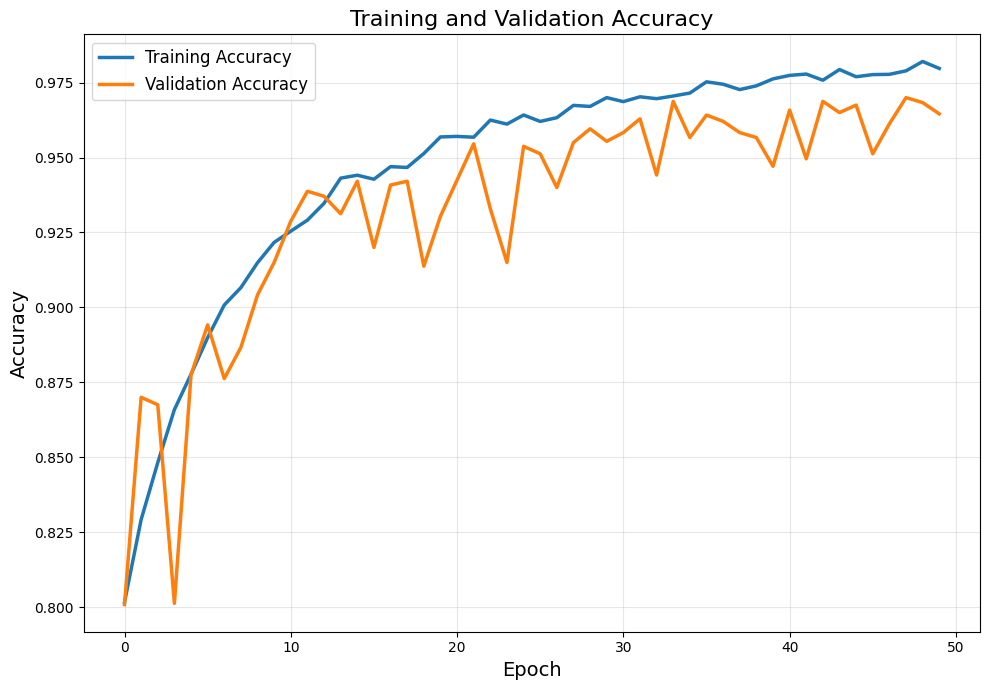

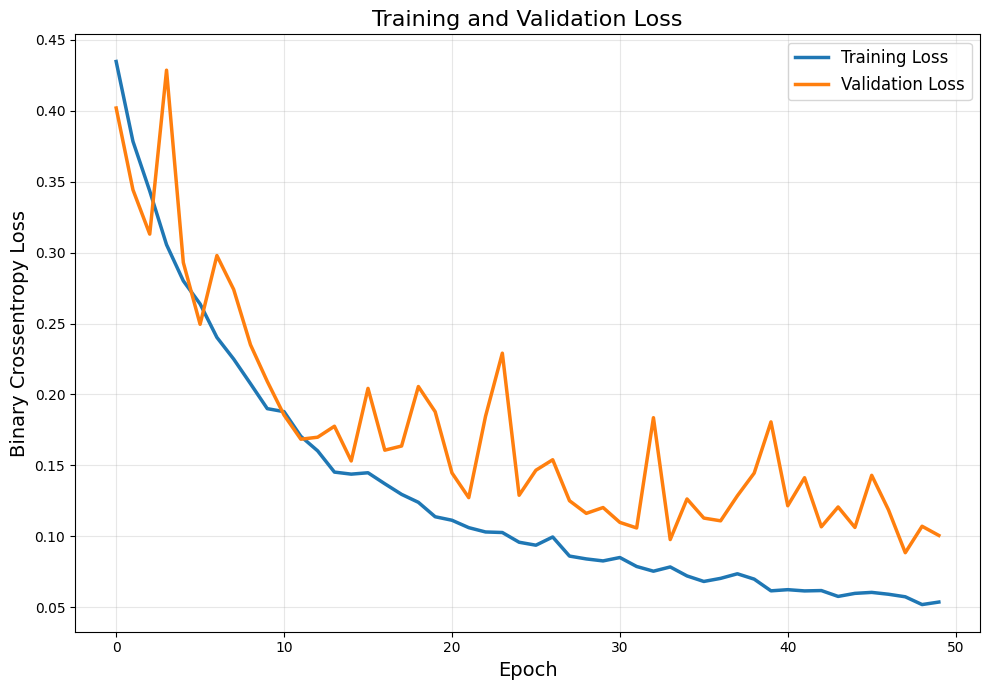

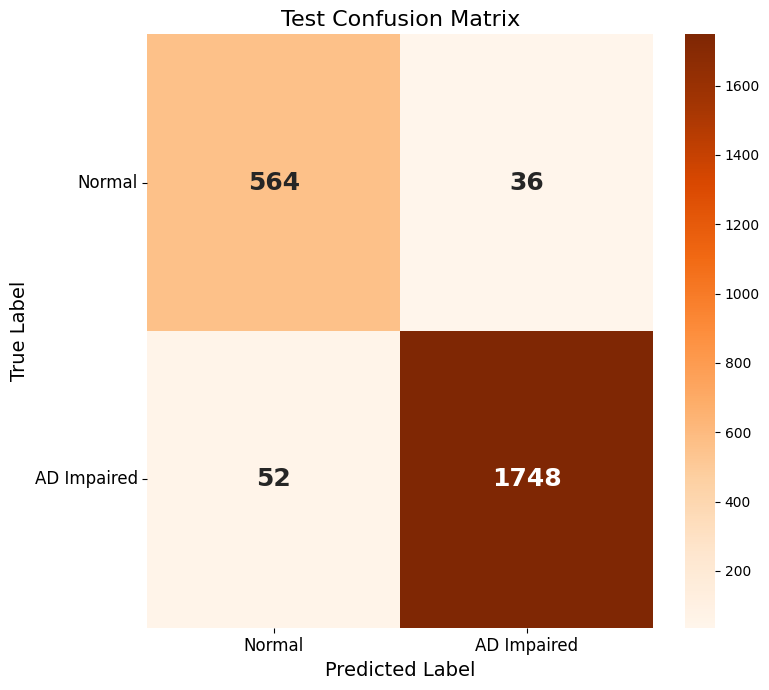


FILES SAVED
/kaggle/working/BCFedARFR_ApeNet_training_history.csv
/kaggle/working/BCFedARFR_ApeNet_Core.keras


In [11]:
# ============================================================
# MEMORY-REDUCED PROPOSED MODEL TRAINING
# EfficientNetB0 + Lightweight ARFR + Coordinate Attention
#
# Dataset: 16,000 images
# 4,000 images per original class
# Binary: 0 = Normal, 1 = AD Impaired
#
# Batch size: 2
# Epochs: 50
# Gaussian noise: NO
# Early stopping: NO
# Checkpointing: NO
# Learning-rate decay: NO
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

# ============================================================
# ============================================================
# 1. MEMORY CLEANUP AND CONFIGURATION
# ============================================================

tf.keras.backend.clear_session()
gc.collect()

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Faster training configuration
BATCH_SIZE = 16
EPOCHS = 50
IMG_SIZE = (224, 224)
LEARNING_RATE = 1e-3

# Enable GPU memory growth before GPU initialization
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

# Mixed precision to reduce GPU memory usage
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Image size:", IMG_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Gaussian noise: NOT USED")
print("Early stopping: NOT USED")
print("Checkpointing: NOT USED")
print("Learning-rate decay: NOT USED")

# ============================================================
# 2. REBUILD MEMORY-SAFE DATASETS
# Requires train_df, val_df, test_df from your split cell.
# Each DataFrame must contain filepath and binary_label.
# ============================================================

def load_mri_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)

    image = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.float32)


def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (
            dataframe["filepath"].astype(str).values,
            dataframe["binary_label"].astype("float32").values
        )
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(dataframe), 2000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_mri_image,
        num_parallel_calls=1
    )

    ds = ds.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    return ds.prefetch(1)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("\nDataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


# ============================================================
# 3. TRAINING-ONLY AUGMENTATION
# NO GAUSSIAN NOISE
# ============================================================

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(
        0.03,
        fill_mode="nearest"
    ),
    layers.RandomZoom(
        height_factor=(-0.05, 0.05),
        width_factor=(-0.05, 0.05),
        fill_mode="nearest"
    ),
    layers.RandomTranslation(
        height_factor=0.03,
        width_factor=0.03,
        fill_mode="nearest"
    ),
    layers.RandomContrast(0.05)
], name="Training_Only_Augmentation")


# ============================================================
# 4. COORDINATE ATTENTION
# Supports the 7 x 7 EfficientNet feature map.
# ============================================================

def coordinate_attention(x, reduction=32, name="CoordinateAttention"):

    channels = int(x.shape[-1])
    height = int(x.shape[1])
    width = int(x.shape[2])

    reduced_channels = max(
        8,
        channels // reduction
    )

    # Height and width descriptors
    h_pool = layers.Lambda(
        lambda t: tf.reduce_mean(
            t, axis=2, keepdims=True
        ),
        name=f"{name}_HeightPool"
    )(x)

    w_pool = layers.Lambda(
        lambda t: tf.reduce_mean(
            t, axis=1, keepdims=True
        ),
        name=f"{name}_WidthPool"
    )(x)

    w_pool = layers.Permute(
        (2, 1, 3),
        name=f"{name}_WidthPermute"
    )(w_pool)

    y = layers.Concatenate(
        axis=1,
        name=f"{name}_Concat"
    )([h_pool, w_pool])

    y = layers.Conv2D(
        reduced_channels,
        kernel_size=1,
        padding="same",
        use_bias=False,
        name=f"{name}_ReduceConv"
    )(y)

    y = layers.BatchNormalization(
        name=f"{name}_BN"
    )(y)

    y = layers.Activation(
        "swish",
        name=f"{name}_Activation"
    )(y)

    # Split at the original feature-map height.
    h_att = layers.Lambda(
        lambda t: t[:, :height, :, :],
        name=f"{name}_HeightSplit"
    )(y)

    w_att = layers.Lambda(
        lambda t: t[:, height:height + width, :, :],
        name=f"{name}_WidthSplit"
    )(y)

    w_att = layers.Permute(
        (2, 1, 3),
        name=f"{name}_WidthRestore"
    )(w_att)

    h_att = layers.Conv2D(
        channels,
        kernel_size=1,
        activation="sigmoid",
        padding="same",
        name=f"{name}_HeightAttention"
    )(h_att)

    w_att = layers.Conv2D(
        channels,
        kernel_size=1,
        activation="sigmoid",
        padding="same",
        name=f"{name}_WidthAttention"
    )(w_att)

    x = layers.Multiply(
        name=f"{name}_ApplyHeight"
    )([x, h_att])

    x = layers.Multiply(
        name=f"{name}_ApplyWidth"
    )([x, w_att])

    return x


# ============================================================
# 5. BUILD MODEL
# EfficientNetB0 + LIGHTWEIGHT ARFR + COORDINATE ATTENTION
# ============================================================

inputs = layers.Input(
    shape=(224, 224, 3),
    name="MRI_Input"
)

x = data_augmentation(inputs)

backbone = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained backbone to reduce training memory.
backbone.trainable = False

x = backbone(
    x,
    training=False
)

print("EfficientNetB0 output:", x.shape)


# ------------------------------------------------------------
# LIGHTWEIGHT ARFR
# 1280 -> 256 -> separable convolution -> 1280
# ------------------------------------------------------------

arfr_main = layers.Conv2D(
    256,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="ARFR_Reduce"
)(x)

arfr_main = layers.BatchNormalization(
    name="ARFR_Reduce_BN"
)(arfr_main)

arfr_main = layers.Activation(
    "swish",
    name="ARFR_Reduce_Activation"
)(arfr_main)

arfr_main = layers.SeparableConv2D(
    256,
    kernel_size=3,
    padding="same",
    use_bias=False,
    name="ARFR_Depthwise"
)(arfr_main)

arfr_main = layers.BatchNormalization(
    name="ARFR_Depthwise_BN"
)(arfr_main)

arfr_main = layers.Activation(
    "swish",
    name="ARFR_Depthwise_Activation"
)(arfr_main)

arfr_main = layers.Conv2D(
    1280,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="ARFR_Expand"
)(arfr_main)

arfr_residual = layers.Conv2D(
    1280,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="ARFR_Residual"
)(x)

arfr_residual = layers.BatchNormalization(
    name="ARFR_Residual_BN"
)(arfr_residual)

x = layers.Add(
    name="ARFR_Residual_Add"
)([arfr_main, arfr_residual])

x = layers.Activation(
    "swish",
    name="ARFR_Output"
)(x)


# ------------------------------------------------------------
# COORDINATE ATTENTION
# ------------------------------------------------------------

x = coordinate_attention(
    x,
    reduction=32,
    name="Coordinate_Attention"
)


# ------------------------------------------------------------
# CLASSIFICATION HEAD
# ------------------------------------------------------------

x = layers.GlobalAveragePooling2D(
    name="Global_Average_Pooling"
)(x)

x = layers.Dense(
    256,
    activation="swish",
    name="Classifier_Dense"
)(x)

x = layers.Dropout(
    0.35,
    name="Classifier_Dropout"
)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    dtype="float32",
    name="AD_Probability"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="BCFedARFR_ApeNet_Core"
)


# ============================================================
# 6. COMPILE
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("\n" + "=" * 70)
print("MODEL READY")
print("=" * 70)

print("Model:", model.name)
print("Input:", model.input_shape)
print("Output:", model.output_shape)
print("Total parameters:", f"{model.count_params():,}")
print("Backbone trainable:", backbone.trainable)

model.summary()


# ============================================================
# 7. TRAIN FOR 50 EPOCHS
# ============================================================

print("\n" + "=" * 70)
print("STARTING TRAINING")
print("=" * 70)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    verbose=1
)

print("\nTRAINING COMPLETED")


# ============================================================
# 8. TEST EVALUATION
# ============================================================

test_results = model.evaluate(
    test_ds,
    return_dict=True,
    verbose=1
)

print("\n" + "=" * 70)
print("FINAL TEST METRICS")
print("=" * 70)

for metric, value in test_results.items():
    print(f"{metric:<15}: {value:.4f}")


# ============================================================
# 9. TEST PREDICTIONS
# ============================================================

y_true = test_df["binary_label"].to_numpy().astype(int)

y_prob = model.predict(
    test_ds,
    verbose=1
).reshape(-1)

y_pred = (y_prob >= 0.5).astype(int)

test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(
    y_true, y_pred, zero_division=0
)
test_recall = recall_score(
    y_true, y_pred, zero_division=0
)
test_f1 = f1_score(
    y_true, y_pred, zero_division=0
)
test_auc = roc_auc_score(y_true, y_prob)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp) if (tn + fp) else 0.0

print("\n" + "=" * 70)
print("CLASSIFICATION PERFORMANCE")
print("=" * 70)

print(f"Accuracy     : {test_accuracy:.4f}")
print(f"Precision    : {test_precision:.4f}")
print(f"Sensitivity  : {test_recall:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"F1-score     : {test_f1:.4f}")
print(f"ROC-AUC      : {test_auc:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Normal", "AD Impaired"],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 10. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 7))

plt.plot(
    history.history["accuracy"],
    linewidth=2.5,
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    linewidth=2.5,
    label="Validation Accuracy"
)

plt.xlabel("Epoch", fontsize=14)
plt.ylabel("Accuracy", fontsize=14)
plt.title("Training and Validation Accuracy", fontsize=16)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 11. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 7))

plt.plot(
    history.history["loss"],
    linewidth=2.5,
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    linewidth=2.5,
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=14)
plt.ylabel("Binary Crossentropy Loss", fontsize=14)
plt.title("Training and Validation Loss", fontsize=16)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

import seaborn as sns

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    annot_kws={"size": 18, "weight": "bold"},
    xticklabels=["Normal", "AD Impaired"],
    yticklabels=["Normal", "AD Impaired"],
    cbar=True
)

plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.title("Test Confusion Matrix", fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12, rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# 13. SAVE TRAINING HISTORY AND MODEL
# ============================================================

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "/kaggle/working/BCFedARFR_ApeNet_training_history.csv",
    index=False
)

model.save(
    "/kaggle/working/BCFedARFR_ApeNet_Core.keras"
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print(
    "/kaggle/working/BCFedARFR_ApeNet_training_history.csv"
)

print(
    "/kaggle/working/BCFedARFR_ApeNet_Core.keras"
)

print("=" * 70)

In [12]:
import os

font_folder = "/kaggle/input/datasets/evangelinnisha/roman-font"

print(os.listdir(font_folder))

['Times New Roman Bold.ttf']


In [13]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = "/kaggle/input/datasets/evangelinnisha/roman-font/Times New Roman Bold.ttf"

fm.fontManager.addfont(font_path)

font_name = fm.FontProperties(fname=font_path).get_name()

plt.rcParams["font.family"] = font_name

print("✅ Times New Roman Bold imported successfully!")
print("Font:", font_name)

✅ Times New Roman Bold imported successfully!
Font: Times New Roman


150/150 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step
CONFUSION MATRIX — BCFedARFR-ApeNet
Rows = True labels | Columns = Predicted labels
[[ 564   36]
 [  52 1748]]
Total test images: 2400


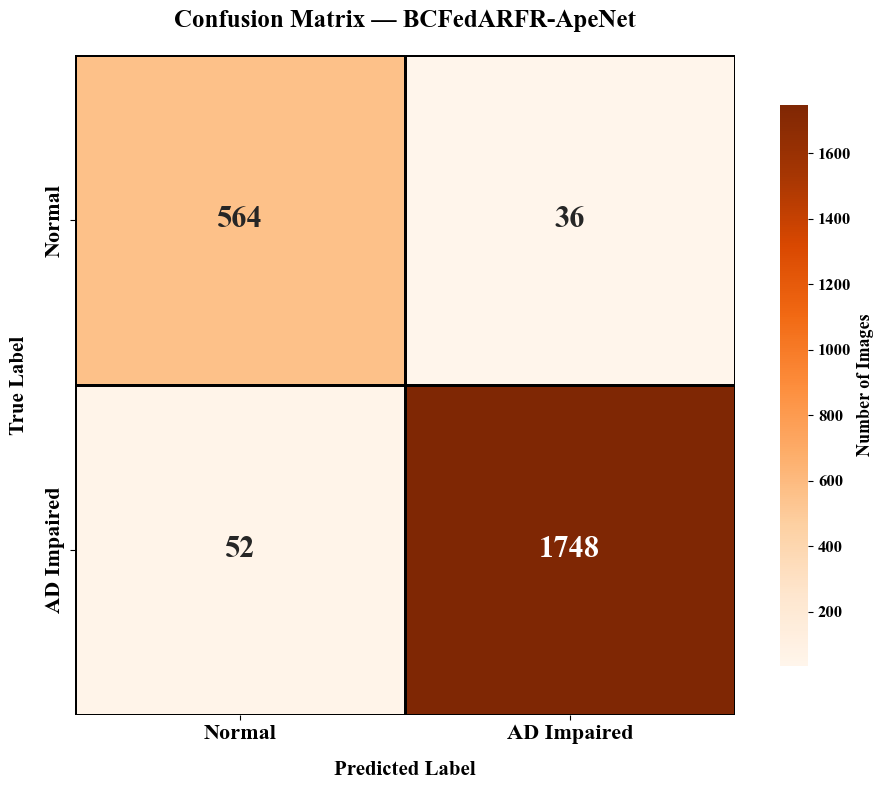

Saved: /kaggle/working/BCFedARFR_ApeNet_Confusion_Matrix.png


/kaggle/working/BCFedARFR_ApeNet_Confusion_Matrix.png

In [14]:
# ============================================================
# SECTION 12 — CONFUSION MATRIX
# BCFedARFR-ApeNet | ORANGE | LARGE BOLD NUMBERS
# SAVE + DOWNLOAD
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from IPython.display import FileLink, display

# 1. True labels
y_true = test_df["binary_label"].to_numpy().astype(int)

# 2. Predictions from the trained model
y_prob = model.predict(test_ds, verbose=1).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

# 3. Verify the number of predictions
assert len(y_true) == len(y_pred), (
    f"Mismatch: {len(y_true)} true labels, "
    f"{len(y_pred)} predictions"
)

# 4. Calculate confusion matrix
class_names = ["Normal", "AD Impaired"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("=" * 60)
print("CONFUSION MATRIX — BCFedARFR-ApeNet")
print("=" * 60)
print("Rows = True labels | Columns = Predicted labels")
print(cm)
print("Total test images:", cm.sum())

# 5. Plot
plt.figure(figsize=(10, 8))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    square=True,
    linewidths=2,
    linecolor="black",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 22, "weight": "bold"},
    cbar_kws={"shrink": 0.85}
)

ax.set_title(
    "Confusion Matrix — BCFedARFR-ApeNet",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Predicted Label",
    fontsize=15,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "True Label",
    fontsize=15,
    fontweight="bold",
    labelpad=12
)

ax.tick_params(axis="both", labelsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=12)
colorbar.set_label(
    "Number of Images",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

# 6. Save high-resolution image
save_path = (
    "/kaggle/working/"
    "BCFedARFR_ApeNet_Confusion_Matrix.png"
)

plt.savefig(
    save_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()

# 7. Download
print("Saved:", save_path)
display(FileLink(save_path))

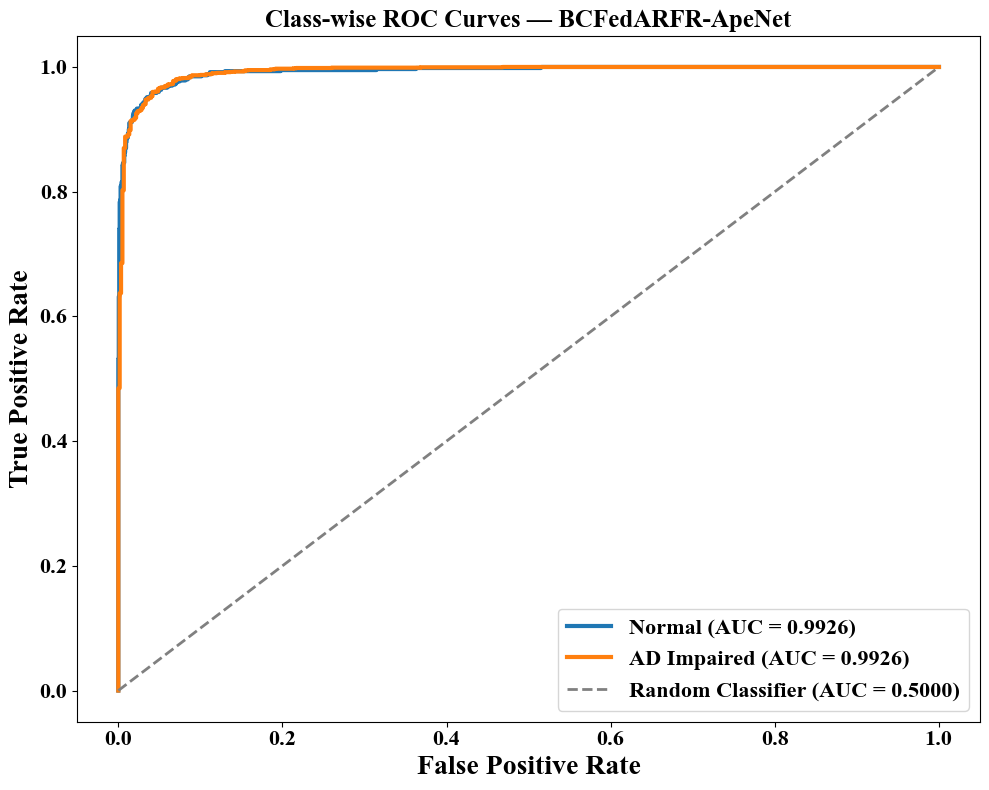


CLASS-WISE ROC-AUC SCORES
Normal         : 0.9926
AD Impaired    : 0.9926
Saved to: /kaggle/working/BCFedARFR_Results/Class_Wise_ROC_Curve.png


In [15]:
# ============================================================
# CLASS-WISE ROC CURVE — FIXED VERSION
# BCFedARFR-ApeNet
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import os

class_names = ["Normal", "AD Impaired"]

# Actual labels: 0 = Normal, 1 = AD Impaired
y_true_binary = np.asarray(y_true).astype(int).ravel()

# Probability of AD Impaired
y_prob_binary = np.asarray(y_prob).ravel()

# Validate array lengths
assert len(y_true_binary) == len(y_prob_binary), \
    "Actual labels and predicted probabilities have different lengths."

# Probability for each class
y_prob_classes = [
    1.0 - y_prob_binary,  # Normal
    y_prob_binary         # AD Impaired
]

os.makedirs("/kaggle/working/BCFedARFR_Results", exist_ok=True)

plt.figure(figsize=(10, 8))
class_auc = {}

for i, class_name in enumerate(class_names):

    # One-vs-rest labels for this class
    y_true_class = (y_true_binary == i).astype(int)

    fpr, tpr, _ = roc_curve(
        y_true_class,
        y_prob_classes[i]
    )

    roc_auc = auc(fpr, tpr)
    class_auc[class_name] = roc_auc

    plt.plot(
        fpr,
        tpr,
        linewidth=3,
        label=f"{class_name} (AUC = {roc_auc:.4f})"
    )

# Random classifier baseline
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    linewidth=2,
    color="gray",
    label="Random Classifier (AUC = 0.5000)"
)

plt.xlabel("False Positive Rate", fontsize=20, fontweight="bold")
plt.ylabel("True Positive Rate", fontsize=20, fontweight="bold")
plt.title(
    "Class-wise ROC Curves — BCFedARFR-ApeNet",
    fontsize=18,
    fontweight="bold"
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16, loc="lower right")

plt.tight_layout()

save_path = (
    "/kaggle/working/BCFedARFR_Results/"
    "Class_Wise_ROC_Curve.png"
)

plt.savefig(save_path, dpi=400, bbox_inches="tight")
plt.show()

print("\nCLASS-WISE ROC-AUC SCORES")
print("=" * 40)

for name, score in class_auc.items():
    print(f"{name:15s}: {score:.4f}")

print("=" * 40)
print("Saved to:", save_path)

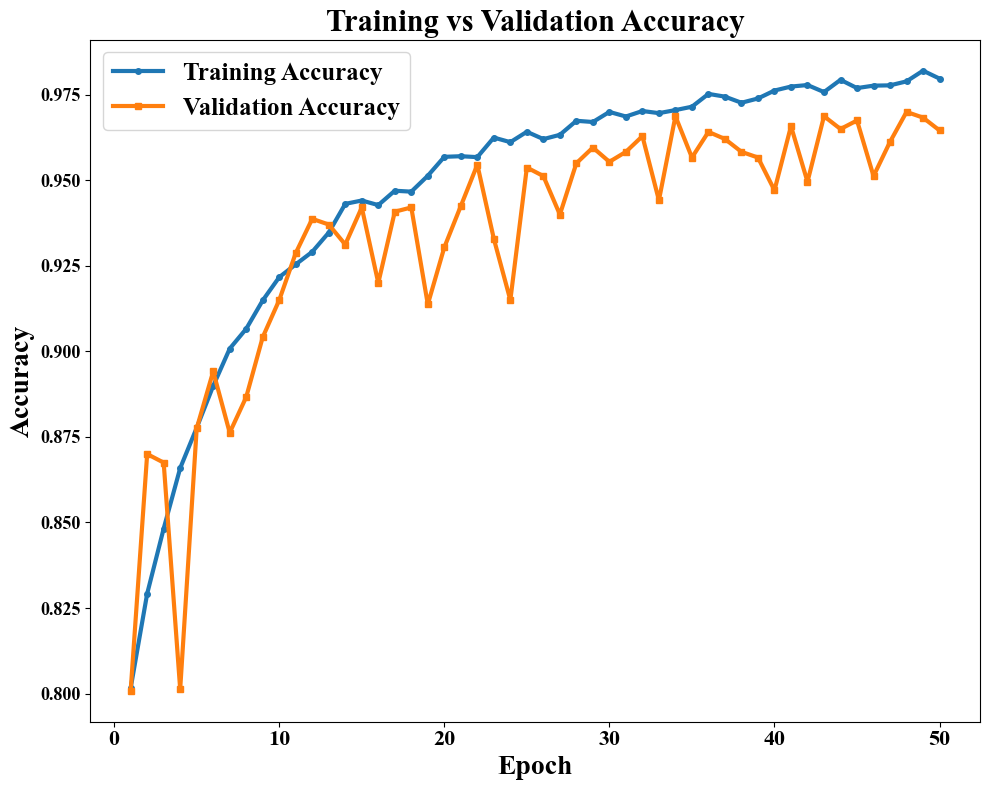

Accuracy graph saved: /kaggle/working/BCFedARFR_Results/Training_vs_Validation_Accuracy.png


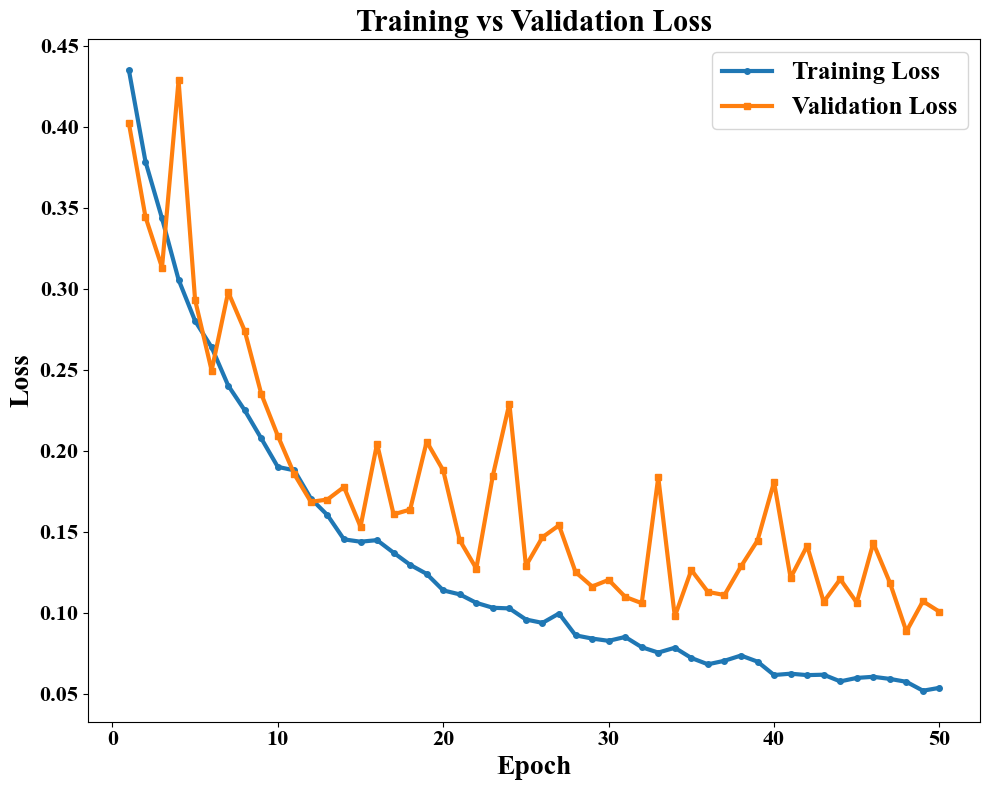

Loss graph saved: /kaggle/working/BCFedARFR_Results/Training_vs_Validation_Loss.png


In [16]:
# ============================================================
# TRAINING VS VALIDATION ACCURACY AND LOSS
# BCFedARFR-ApeNet
# ============================================================

import matplotlib.pyplot as plt
import os

# Output directory
save_dir = "/kaggle/working/BCFedARFR_Results"
os.makedirs(save_dir, exist_ok=True)

# Get training history
hist = history.history

# ============================================================
# 1. TRAINING VS VALIDATION ACCURACY
# ============================================================

if "accuracy" in hist and "val_accuracy" in hist:

    epochs = range(1, len(hist["accuracy"]) + 1)

    plt.figure(figsize=(10, 8))

    plt.plot(
        epochs,
        hist["accuracy"],
        linewidth=3,
        marker="o",
        markersize=4,
        label="Training Accuracy"
    )

    plt.plot(
        epochs,
        hist["val_accuracy"],
        linewidth=3,
        marker="s",
        markersize=4,
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch", fontsize=20, fontweight="bold")
    plt.ylabel("Accuracy", fontsize=20, fontweight="bold")
    plt.title(
        "Training vs Validation Accuracy",
        fontsize=22,
        fontweight="bold"
    )

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=13)
    plt.legend(fontsize=18)
 
    plt.tight_layout()

    accuracy_path = os.path.join(
        save_dir, "Training_vs_Validation_Accuracy.png"
    )

    plt.savefig(accuracy_path, dpi=400, bbox_inches="tight")
    plt.show()

    print("Accuracy graph saved:", accuracy_path)

else:
    print("Accuracy keys not found. Available keys:", list(hist.keys()))


# ============================================================
# 2. TRAINING VS VALIDATION LOSS
# ============================================================

if "loss" in hist and "val_loss" in hist:

    epochs = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(10, 8))

    plt.plot(
        epochs,
        hist["loss"],
        linewidth=3,
        marker="o",
        markersize=4,
        label="Training Loss"
    )

    plt.plot(
        epochs,
        hist["val_loss"],
        linewidth=3,
        marker="s",
        markersize=4,
        label="Validation Loss"
    )

    plt.xlabel("Epoch", fontsize=20, fontweight="bold")
    plt.ylabel("Loss", fontsize=20, fontweight="bold")
    plt.title(
        "Training vs Validation Loss",
        fontsize=22,
        fontweight="bold"
    )

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.legend(fontsize=18)
  
    plt.tight_layout()

    loss_path = os.path.join(
        save_dir, "Training_vs_Validation_Loss.png"
    )

    plt.savefig(loss_path, dpi=400, bbox_inches="tight")
    plt.show()

    print("Loss graph saved:", loss_path)

else:
    print("Loss keys not found. Available keys:", list(hist.keys()))

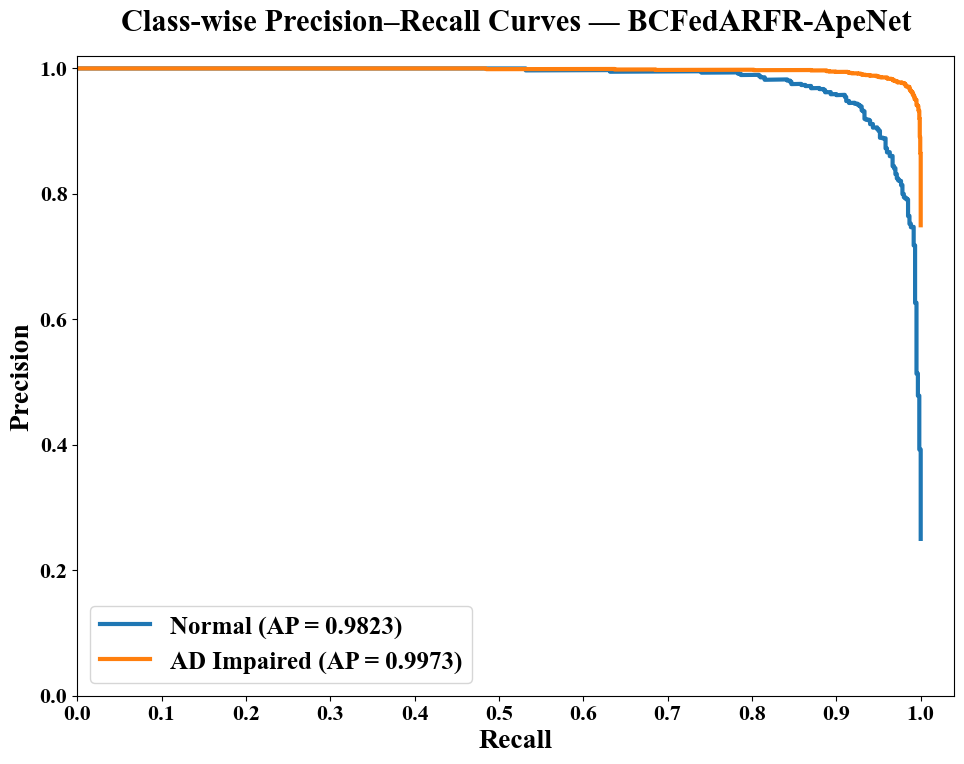


CLASS-WISE AVERAGE PRECISION
Normal              : 0.9823
AD Impaired         : 0.9973
Graph saved to: /kaggle/working/BCFedARFR_Results/Class_Wise_Precision_Recall_Curve.png


In [20]:
# ============================================================
# CLASS-WISE PRECISION–RECALL CURVE — NO GRID
# BCFedARFR-ApeNet
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

class_ap = {}

# ------------------------------------------------------------
# PLOT PRECISION–RECALL CURVE FOR EACH CLASS
# ------------------------------------------------------------

for i, class_name in enumerate(class_names):

    y_true_class = (y_true_binary == i).astype(int)

    precision, recall, _ = precision_recall_curve(
        y_true_class,
        y_prob_classes[i]
    )

    ap = average_precision_score(
        y_true_class,
        y_prob_classes[i]
    )

    class_ap[class_name] = ap

    plt.plot(
        recall,
        precision,
        linewidth=3,
        label=f"{class_name} (AP = {ap:.4f})"
    )

# ------------------------------------------------------------
# AXES AND TITLE
# ------------------------------------------------------------

plt.xlabel(
    "Recall",
    fontsize=20,
    fontweight="bold"
)

plt.ylabel(
    "Precision",
    fontsize=20,
    fontweight="bold"
)

plt.title(
    "Class-wise Precision–Recall Curves — BCFedARFR-ApeNet",
    fontsize=22,
    fontweight="bold",
    pad=18
)

# Extra right margin
plt.xlim(0, 1.04)
plt.ylim(0, 1.02)

plt.xticks(
    np.arange(0, 1.01, 0.1),
    fontsize=16
)

plt.yticks(fontsize=16)

# ------------------------------------------------------------
# NO GRID OR BASELINE LINES
# ------------------------------------------------------------

plt.grid(False)

ax = plt.gca()
ax.grid(False, which="both")

# ------------------------------------------------------------
# LEGEND AND LAYOUT
# ------------------------------------------------------------

plt.legend(
    fontsize=18,
    loc="lower left",
    frameon=True
)

plt.tight_layout(pad=2.0)

# ------------------------------------------------------------
# SAVE GRAPH
# ------------------------------------------------------------

save_path = os.path.join(
    save_dir,
    "Class_Wise_Precision_Recall_Curve.png"
)

plt.savefig(
    save_path,
    dpi=400,
    bbox_inches="tight",
    pad_inches=0.25
)

plt.show()

# ------------------------------------------------------------
# PRINT AVERAGE PRECISION
# ------------------------------------------------------------

print("\nCLASS-WISE AVERAGE PRECISION")
print("=" * 40)

for name, ap in class_ap.items():
    print(f"{name:20s}: {ap:.4f}")

print("=" * 40)
print("Graph saved to:", save_path)

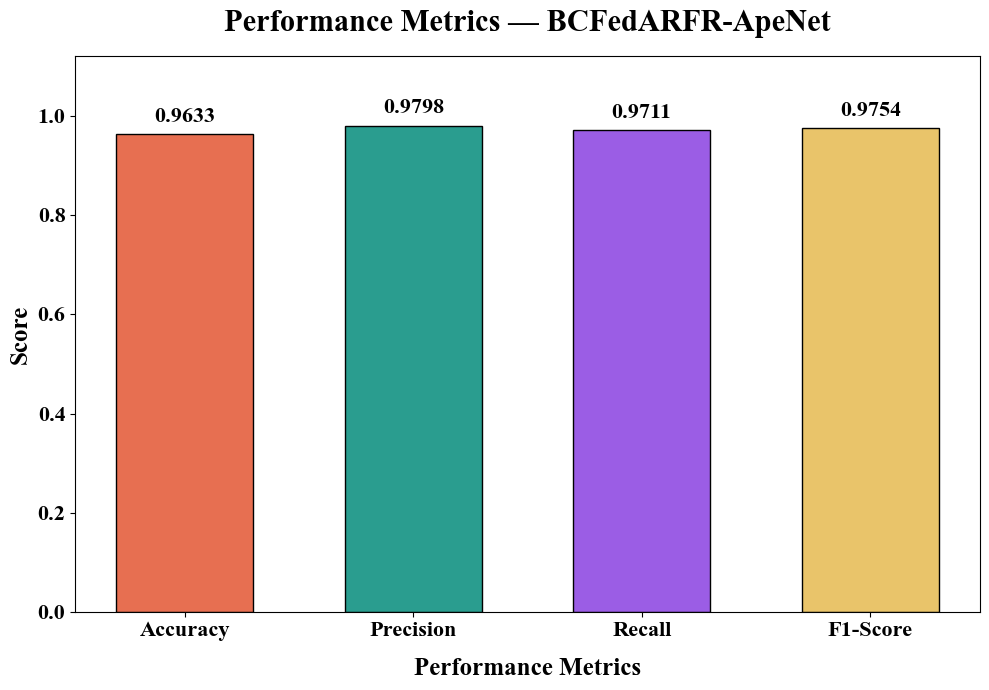


PERFORMANCE METRICS
Accuracy       : 0.9633
Precision      : 0.9798
Recall         : 0.9711
F1-Score       : 0.9754
Graph saved to: /kaggle/working/BCFedARFR_Results/Performance_Metrics_Accuracy_Precision_Recall_F1.png


In [21]:
# ============================================================
# PERFORMANCE METRICS BAR GRAPH — 4 METRICS
# BCFedARFR-ApeNet
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Actual labels and predicted probabilities
y_true_binary = np.asarray(y_true).astype(int).ravel()
y_prob_binary = np.asarray(y_prob).ravel()
y_pred_binary = (y_prob_binary >= 0.5).astype(int)

# Calculate four performance metrics
metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

metric_values = [
    accuracy_score(y_true_binary, y_pred_binary),
    precision_score(y_true_binary, y_pred_binary, zero_division=0),
    recall_score(y_true_binary, y_pred_binary, zero_division=0),
    f1_score(y_true_binary, y_pred_binary, zero_division=0)
]

# Different colour for each bar
bar_colors = [
    "#E76F51",
    "#2A9D8F",
    "#9B5DE5",
    "#E9C46A"
]

# Output directory
save_dir = "/kaggle/working/BCFedARFR_Results"
os.makedirs(save_dir, exist_ok=True)

# Plot graph
fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.bar(
    metric_names,
    metric_values,
    color=bar_colors,
    edgecolor="black",
    linewidth=1,
    width=0.6
)

# Value labels above bars
for bar, value in zip(bars, metric_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold"
    )

ax.set_title(
    "Performance Metrics — BCFedARFR-ApeNet",
    fontsize=22,
    fontweight="bold",
    pad=18
)

# X-axis label
ax.set_xlabel(
    "Performance Metrics",
    fontsize=18,
    fontweight="bold",
    labelpad=12
)

# Keep metric names visible
ax.set_xticks(range(len(metric_names)))
ax.set_xticklabels(
    metric_names,
    fontsize=13,
    rotation=0,
    ha="center"
)

ax.tick_params(axis="y", labelsize=12)

# Give labels enough room
plt.tight_layout()
plt.subplots_adjust(bottom=0.18)
ax.set_ylabel("Score", fontsize=18, fontweight="bold")
ax.set_ylim(0, 1.12)

ax.tick_params(axis="x", labelsize=16)
ax.tick_params(axis="y", labelsize=16)


ax.set_axisbelow(True)

plt.tight_layout()

# Save high-resolution graph
save_path = os.path.join(
    save_dir,
    "Performance_Metrics_Accuracy_Precision_Recall_F1.png"
)

plt.savefig(save_path, dpi=400, bbox_inches="tight")
plt.show()

# Print metric values
print("\nPERFORMANCE METRICS")
print("=" * 40)

for name, value in zip(metric_names, metric_values):
    print(f"{name:15s}: {value:.4f}")

print("=" * 40)
print("Graph saved to:", save_path)

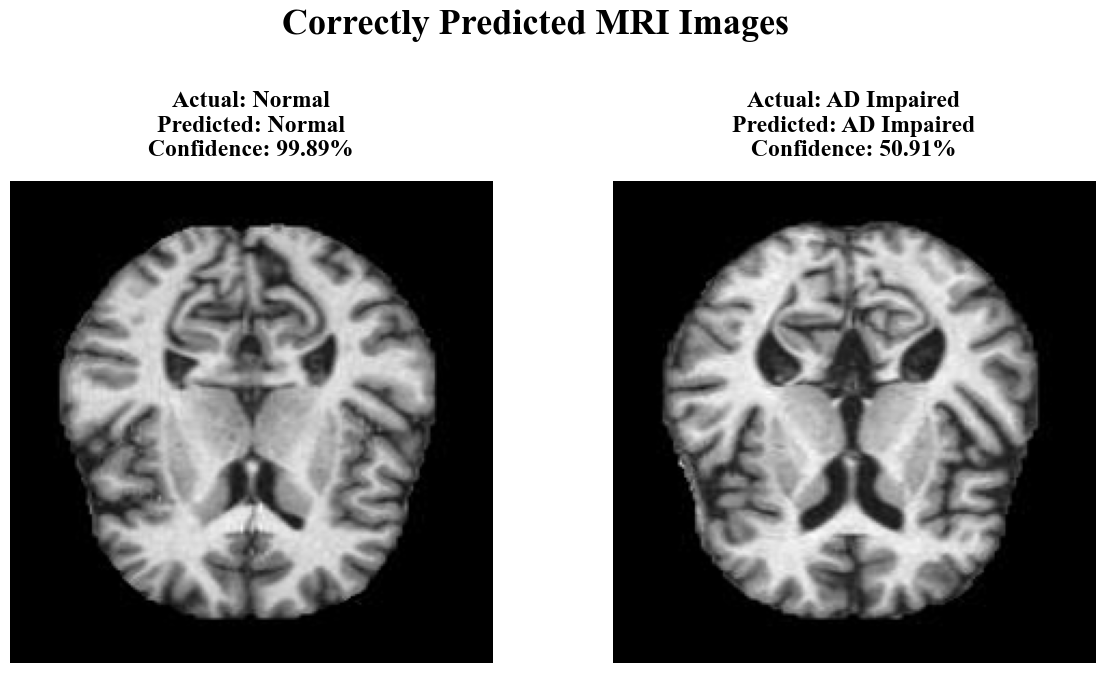

Saved successfully: /kaggle/working/BCFedARFR_Results/Correctly_Predicted_Normal_and_AD_Impaired.png


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# Get true labels and predictions
y_true_binary = test_df["binary_label"].to_numpy().astype(int)
y_prob_binary = model.predict(test_ds, verbose=0).reshape(-1)
y_pred_binary = (y_prob_binary >= 0.5).astype(int)

# Find correctly predicted images for each class
normal_indices = np.where(
    (y_true_binary == 0) & (y_pred_binary == 0)
)[0]

ad_indices = np.where(
    (y_true_binary == 1) & (y_pred_binary == 1)
)[0]

if len(normal_indices) == 0 or len(ad_indices) == 0:
    raise ValueError("A correctly predicted image is missing for one of the classes.")

# Select one correct image from each class
selected_indices = [normal_indices[0], ad_indices[0]]
class_names = ["Normal", "AD Impaired"]

# Plot the two images
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

fig.suptitle(
    "Correctly Predicted MRI Images",
    fontsize=26,
    fontweight="bold",
    y=0.96
)

for ax, idx, class_name in zip(axes, selected_indices, class_names):
    row = test_df.iloc[idx]

    img = Image.open(row["filepath"]).convert("RGB")
    img = img.resize((224, 224))

    confidence = float(y_prob_binary[idx])
    if class_name == "Normal":
        confidence = 1 - confidence

    ax.imshow(img)
    ax.set_title(
        f"Actual: {class_name}\n"
        f"Predicted: {class_name}\n"
        f"Confidence: {confidence:.2%}",
        fontsize=17,
        fontweight="bold",
        pad=18
    )
    ax.axis("off")

plt.subplots_adjust(top=0.78, wspace=0.25)

save_path = (
    "/kaggle/working/BCFedARFR_Results/"
    "Correctly_Predicted_Normal_and_AD_Impaired.png"
)
os.makedirs(os.path.dirname(save_path), exist_ok=True)

plt.savefig(save_path, dpi=400, bbox_inches="tight", pad_inches=0.4)
plt.show()

print("Saved successfully:", save_path)

In [23]:
# ============================================================
# STEP 1: FIND EFFICIENTNETB0 LAYERS FOR GRAD-CAM
# ============================================================

for layer in model.layers:
    print(f"{layer.name:40s} | {layer.__class__.__name__}")

    if hasattr(layer, "layers"):
        for sublayer in layer.layers:
            if isinstance(sublayer, tf.keras.layers.Conv2D):
                print(
                    f"    Conv layer: {sublayer.name} | "
                    f"Output: {sublayer.output.shape}"
                )

MRI_Input                                | InputLayer
Training_Only_Augmentation               | Sequential
efficientnetb0                           | Functional
    Conv layer: stem_conv | Output: (None, 112, 112, 32)
    Conv layer: block1a_se_reduce | Output: (None, 1, 1, 8)
    Conv layer: block1a_se_expand | Output: (None, 1, 1, 32)
    Conv layer: block1a_project_conv | Output: (None, 112, 112, 16)
    Conv layer: block2a_expand_conv | Output: (None, 112, 112, 96)
    Conv layer: block2a_se_reduce | Output: (None, 1, 1, 4)
    Conv layer: block2a_se_expand | Output: (None, 1, 1, 96)
    Conv layer: block2a_project_conv | Output: (None, 56, 56, 24)
    Conv layer: block2b_expand_conv | Output: (None, 56, 56, 144)
    Conv layer: block2b_se_reduce | Output: (None, 1, 1, 6)
    Conv layer: block2b_se_expand | Output: (None, 1, 1, 144)
    Conv layer: block2b_project_conv | Output: (None, 56, 56, 24)
    Conv layer: block3a_expand_conv | Output: (None, 56, 56, 144)
    Conv layer: bl

In [24]:
# ============================================================
# CHECK ARFR LAYER CONNECTIONS
# ============================================================

for layer_name in [
    "ARFR_Reduce",
    "ARFR_Reduce_BN",
    "ARFR_Depthwise",
    "ARFR_Residual",
    "ARFR_Expand",
    "ARFR_Residual_BN",
    "ARFR_Residual_Add",
    "ARFR_Output",
    "Coordinate_Attention_ApplyWidth",
    "Global_Average_Pooling"
]:
    layer = model.get_layer(layer_name)

    print(f"\nLayer: {layer_name}")
    print("Class:", layer.__class__.__name__)

    try:
        print("Input shape:", layer.input.shape)
        print("Output shape:", layer.output.shape)
    except Exception as e:
        print("Could not inspect shape:", e)


Layer: ARFR_Reduce
Class: Conv2D
Input shape: (None, 7, 7, 1280)
Output shape: (None, 7, 7, 256)

Layer: ARFR_Reduce_BN
Class: BatchNormalization
Input shape: (None, 7, 7, 256)
Output shape: (None, 7, 7, 256)

Layer: ARFR_Depthwise
Class: SeparableConv2D
Input shape: (None, 7, 7, 256)
Output shape: (None, 7, 7, 256)

Layer: ARFR_Residual
Class: Conv2D
Input shape: (None, 7, 7, 1280)
Output shape: (None, 7, 7, 1280)

Layer: ARFR_Expand
Class: Conv2D
Input shape: (None, 7, 7, 256)
Output shape: (None, 7, 7, 1280)

Layer: ARFR_Residual_BN
Class: BatchNormalization
Input shape: (None, 7, 7, 1280)
Output shape: (None, 7, 7, 1280)

Layer: ARFR_Residual_Add
Class: Add
Could not inspect shape: 'list' object has no attribute 'shape'

Layer: ARFR_Output
Class: Activation
Input shape: (None, 7, 7, 1280)
Output shape: (None, 7, 7, 1280)

Layer: Coordinate_Attention_ApplyWidth
Class: Multiply
Could not inspect shape: 'list' object has no attribute 'shape'

Layer: Global_Average_Pooling
Class: Glob

MRI image loaded successfully!
File: verymildDem544.jpg
True label: 1 (AD Impaired)
test_array shape: (1, 224, 224, 3)
Pixel range: 0.0 to 250.7602


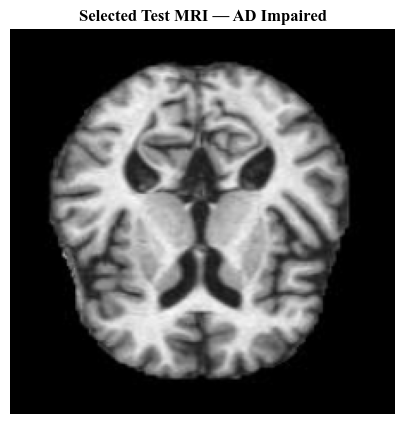

In [27]:
# ============================================================
# FIX — CREATE test_array FROM test_df
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)

# Select one MRI image from the test dataset
sample_path = test_df.iloc[0]["filepath"]
sample_label = int(test_df.iloc[0]["binary_label"])

# Load and resize image
image_bytes = tf.io.read_file(sample_path)

image = tf.image.decode_image(
    image_bytes,
    channels=3,
    expand_animations=False
)

image.set_shape([None, None, 3])

image = tf.image.resize(
    image,
    IMG_SIZE
)

# Create input array with batch dimension
test_array = tf.expand_dims(
    tf.cast(image, tf.float32),
    axis=0
).numpy()

print("MRI image loaded successfully!")
print("File:", os.path.basename(sample_path))
print("True label:", sample_label,
      "(Normal)" if sample_label == 0 else "(AD Impaired)")
print("test_array shape:", test_array.shape)
print("Pixel range:", test_array.min(), "to", test_array.max())

# Display the selected MRI
plt.figure(figsize=(5, 5))
plt.imshow(test_array[0] / 255.0)
plt.title(
    "Selected Test MRI — " +
    ("Normal" if sample_label == 0 else "AD Impaired")
)
plt.axis("off")
plt.show()

GRADIENT SALIENCY RESULTS
Heatmap shape: (224, 224)
Minimum: 0.0
Maximum: 1.0
Mean: 0.055080655962228775
AD Impaired probability: 0.5069
Normal probability: 0.4931
Predicted class: AD Impaired


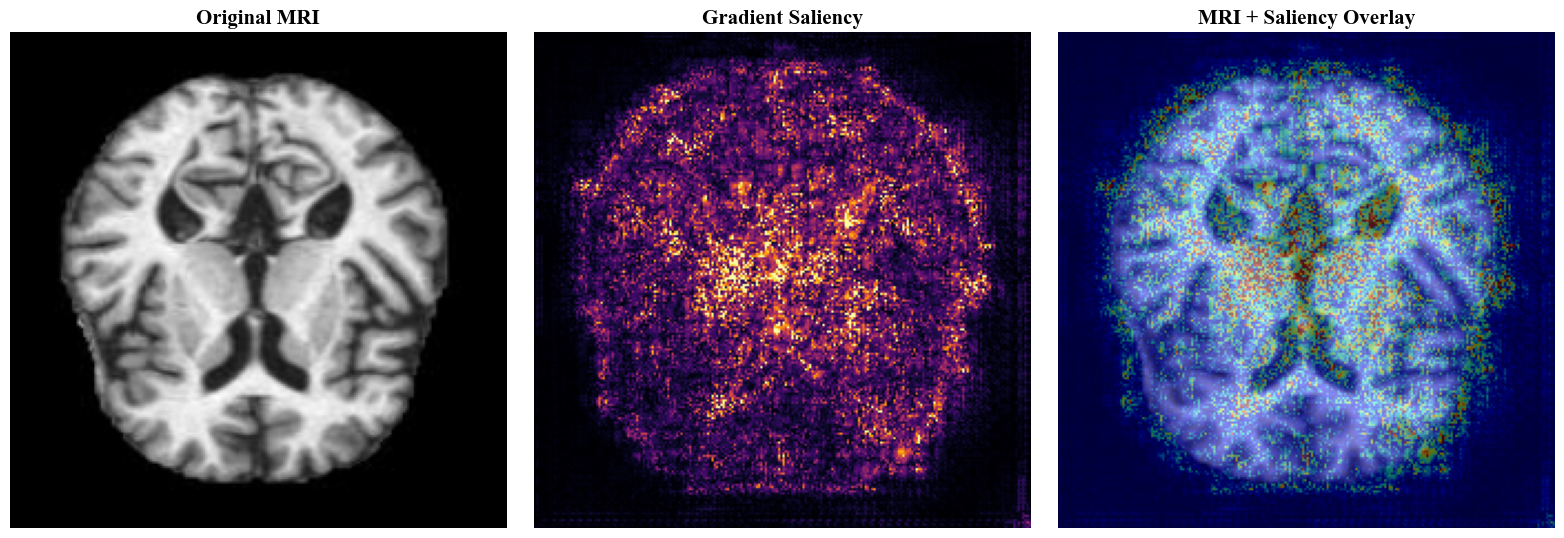


FILES SAVED SUCCESSFULLY
Overlay image: /kaggle/working/BCFedARFR_Results/Gradient_Saliency_Contrast_Overlay.png
Numerical heatmap: /kaggle/working/BCFedARFR_Results/Gradient_Saliency_Heatmap.npy

Download the overlay image:


/kaggle/working/BCFedARFR_Results/Gradient_Saliency_Contrast_Overlay.png


Download the numerical heatmap:


/kaggle/working/BCFedARFR_Results/Gradient_Saliency_Heatmap.npy

In [28]:
# ============================================================
# GRADIENT SALIENCY + MRI OVERLAY
# BCFedARFR-ApeNet — BINARY CLASSIFICATION
# NO GRID | SAVE + DOWNLOAD
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2

from IPython.display import FileLink, display

# ============================================================
# 1. OUTPUT FOLDER
# ============================================================

save_dir = "/kaggle/working/BCFedARFR_Results"
os.makedirs(save_dir, exist_ok=True)


# ============================================================
# 2. GENERATE INPUT-GRADIENT SALIENCY MAP
# ============================================================

def generate_gradient_heatmap(test_array):

    image_tensor = tf.convert_to_tensor(
        test_array,
        dtype=tf.float32
    )

    if len(image_tensor.shape) == 3:
        image_tensor = tf.expand_dims(image_tensor, axis=0)

    if len(image_tensor.shape) != 4:
        raise ValueError(
            "Expected image shape (224,224,3) "
            "or (1,224,224,3)."
        )

    with tf.GradientTape() as tape:
        tape.watch(image_tensor)

        prediction = model(
            image_tensor,
            training=False
        )

        # Binary sigmoid output: probability of AD Impaired
        ad_probability = prediction[0, 0]

    gradients = tape.gradient(
        ad_probability,
        image_tensor
    )

    if gradients is None:
        raise RuntimeError(
            "Gradient calculation failed. Check the model."
        )

    # Pixel-level gradient magnitude
    saliency = tf.reduce_max(
        tf.abs(gradients[0]),
        axis=-1
    ).numpy()

    # Normalize to [0,1]
    saliency_min = np.min(saliency)
    saliency_max = np.max(saliency)

    if saliency_max > saliency_min:
        heatmap = (
            (saliency - saliency_min)
            / (saliency_max - saliency_min)
        )
    else:
        heatmap = np.zeros_like(saliency)

    return heatmap, float(ad_probability.numpy())


# ============================================================
# 3. GENERATE HEATMAP
# ============================================================

if "model" not in globals():
    raise NameError(
        "Your trained model variable 'model' is missing. "
        "Train or load the model first."
    )

if "test_array" not in globals():
    raise NameError(
        "test_array is missing. Run the MRI loading cell first."
    )

heatmap, ad_probability = generate_gradient_heatmap(test_array)

print("=" * 60)
print("GRADIENT SALIENCY RESULTS")
print("=" * 60)
print("Heatmap shape:", heatmap.shape)
print("Minimum:", float(np.min(heatmap)))
print("Maximum:", float(np.max(heatmap)))
print("Mean:", float(np.mean(heatmap)))
print("AD Impaired probability:", f"{ad_probability:.4f}")
print("Normal probability:", f"{1 - ad_probability:.4f}")

predicted_label = (
    "AD Impaired" if ad_probability >= 0.5 else "Normal"
)

print("Predicted class:", predicted_label)


# ============================================================
# 4. IMPROVE HEATMAP CONTRAST
# ============================================================

low, high = np.percentile(heatmap, [1, 99])

if high > low:
    display_heatmap = np.clip(
        (heatmap - low) / (high - low),
        0,
        1
    )
else:
    display_heatmap = heatmap.copy()


# ============================================================
# 5. PREPARE ORIGINAL MRI
# ============================================================

image = np.asarray(test_array)

if image.ndim == 4:
    image = image[0]

image = image.astype(np.float32)

# Display normalization only
image_display = (
    (image - image.min())
    / (image.max() - image.min() + 1e-8)
)


# ============================================================
# 6. CREATE THREE-PANEL VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 6)
)

# Original MRI
axes[0].imshow(image_display)
axes[0].set_title(
    "Original MRI",
    fontsize=15,
    fontweight="bold"
)
axes[0].axis("off")

# Saliency heatmap
axes[1].imshow(
    display_heatmap,
    cmap="inferno",
    vmin=0,
    vmax=1
)
axes[1].set_title(
    "Gradient Saliency",
    fontsize=15,
    fontweight="bold"
)
axes[1].axis("off")

# Resize saliency map to match image
resized_heatmap = cv2.resize(
    display_heatmap,
    (image_display.shape[1], image_display.shape[0]),
    interpolation=cv2.INTER_LINEAR
)

# MRI + saliency overlay
axes[2].imshow(image_display)
axes[2].imshow(
    resized_heatmap,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=1
)
axes[2].set_title(
    "MRI + Saliency Overlay",
    fontsize=15,
    fontweight="bold"
)
axes[2].axis("off")

plt.tight_layout(pad=2.0)


# ============================================================
# 7. SAVE HIGH-RESOLUTION IMAGE
# ============================================================

file_path = os.path.join(
    save_dir,
    "Gradient_Saliency_Contrast_Overlay.png"
)

plt.savefig(
    file_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25,
    facecolor="white"
)

plt.show()
plt.close(fig)


# ============================================================
# 8. SAVE NUMERICAL HEATMAP
# ============================================================

heatmap_path = os.path.join(
    save_dir,
    "Gradient_Saliency_Heatmap.npy"
)

np.save(
    heatmap_path,
    heatmap
)


# ============================================================
# 9. DOWNLOAD LINKS
# ============================================================

print("\n" + "=" * 60)
print("FILES SAVED SUCCESSFULLY")
print("=" * 60)

print("Overlay image:", file_path)
print("Numerical heatmap:", heatmap_path)

print("\nDownload the overlay image:")
display(FileLink(file_path))

print("\nDownload the numerical heatmap:")
display(FileLink(heatmap_path))

In [29]:
# ============================================================
# BCFedARFR-ApeNet — WORKFLOW STATUS CHECK
# ============================================================

print("=" * 60)
print("CURRENT NOTEBOOK STATUS")
print("=" * 60)

check_variables = [
    "model",
    "train_df",
    "val_df",
    "test_df",
    "train_ds",
    "val_ds",
    "test_ds",
    "history",
    "global_model",
    "global_test_ds",
    "client_datasets",
    "client_models",
    "round_accuracies",
    "round_losses",
]

for name in check_variables:
    exists = name in globals()
    print(f"{name:20s}: {'AVAILABLE' if exists else 'NOT FOUND'}")

print("=" * 60)

if "model" in globals():
    print("Local model:", model.name)
    print("Output shape:", model.output_shape)
    print("Parameters:", f"{model.count_params():,}")

if "history" in globals():
    print("Recorded training metrics:",
          list(history.history.keys()))

print("\nStatus check complete. No training was started.")

CURRENT NOTEBOOK STATUS
model               : AVAILABLE
train_df            : AVAILABLE
val_df              : AVAILABLE
test_df             : AVAILABLE
train_ds            : AVAILABLE
val_ds              : AVAILABLE
test_ds             : AVAILABLE
history             : AVAILABLE
global_model        : NOT FOUND
global_test_ds      : NOT FOUND
client_datasets     : NOT FOUND
client_models       : NOT FOUND
round_accuracies    : NOT FOUND
round_losses        : NOT FOUND
Local model: BCFedARFR_ApeNet_Core
Output shape: (None, 1)
Parameters: 6,902,852
Recorded training metrics: ['accuracy', 'auc', 'loss', 'precision', 'recall', 'val_accuracy', 'val_auc', 'val_loss', 'val_precision', 'val_recall']

Status check complete. No training was started.


In [30]:
# ============================================================
# NEXT STEP — FEDERATED CLIENT PARTITIONING
# BCFedARFR-ApeNet
# ============================================================

import os
import pandas as pd
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

NUM_CLIENTS = 4
OUTPUT_DIR = "/kaggle/working/BCFedARFR_Results/Federated_Clients"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Use the existing training dataframe
client_source_df = train_df.copy().reset_index(drop=True)

print("=" * 60)
print("FEDERATED CLIENT PARTITIONING")
print("=" * 60)
print("Total training images:", len(client_source_df))
print("Class distribution:")
print(client_source_df["binary_label"].value_counts())

# ------------------------------------------------------------
# 2. CREATE STRATIFIED CLIENT PARTITIONS
# ------------------------------------------------------------

client_datasets = {}

remaining_df = client_source_df.copy()

for client_id in range(NUM_CLIENTS - 1):
    clients_left = NUM_CLIENTS - client_id

    client_part, remaining_df = train_test_split(
        remaining_df,
        test_size=(clients_left - 1) / clients_left,
        stratify=remaining_df["binary_label"],
        random_state=42 + client_id
    )

    client_datasets[f"Client_{client_id + 1}"] = (
        client_part.reset_index(drop=True)
    )

client_datasets[f"Client_{NUM_CLIENTS}"] = (
    remaining_df.reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. SAVE CLIENT DATASETS
# ------------------------------------------------------------

for client_name, client_df in client_datasets.items():
    csv_path = os.path.join(
        OUTPUT_DIR,
        f"{client_name}.csv"
    )

    client_df.to_csv(csv_path, index=False)

    print(f"\n{client_name}")
    print("Images:", len(client_df))
    print("Class distribution:")
    print(client_df["binary_label"].value_counts().sort_index())
    print("Saved:", csv_path)

# ------------------------------------------------------------
# 4. VERIFY PARTITIONS
# ------------------------------------------------------------

all_client_paths = []

for client_df in client_datasets.values():
    all_client_paths.extend(client_df["filepath"].tolist())

assert len(all_client_paths) == len(client_source_df), (
    "Total image count does not match!"
)

assert len(set(all_client_paths)) == len(all_client_paths), (
    "Duplicate image paths found across clients!"
)

assert set(all_client_paths) == set(client_source_df["filepath"]), (
    "Some training images are missing or unexpected images were added!"
)

print("\n" + "=" * 60)
print("SUCCESS: CLIENT PARTITIONING VERIFIED")
print("Number of clients:", NUM_CLIENTS)
print("All training images assigned exactly once.")
print("Validation and test datasets were not partitioned or modified.")
print("=" * 60)

# ------------------------------------------------------------
# 5. DOWNLOAD ALL CLIENT CSV FILES AS ZIP
# ------------------------------------------------------------

import shutil
from IPython.display import FileLink, display

zip_path = shutil.make_archive(
    "/kaggle/working/Federated_Clients",
    "zip",
    OUTPUT_DIR
)

print("Download client CSV files:")
display(FileLink(zip_path))

FEDERATED CLIENT PARTITIONING
Total training images: 11200
Class distribution:
binary_label
1    8400
0    2800
Name: count, dtype: int64

Client_1
Images: 2800
Class distribution:
binary_label
0     700
1    2100
Name: count, dtype: int64
Saved: /kaggle/working/BCFedARFR_Results/Federated_Clients/Client_1.csv

Client_2
Images: 2800
Class distribution:
binary_label
0     700
1    2100
Name: count, dtype: int64
Saved: /kaggle/working/BCFedARFR_Results/Federated_Clients/Client_2.csv

Client_3
Images: 2800
Class distribution:
binary_label
0     700
1    2100
Name: count, dtype: int64
Saved: /kaggle/working/BCFedARFR_Results/Federated_Clients/Client_3.csv

Client_4
Images: 2800
Class distribution:
binary_label
0     700
1    2100
Name: count, dtype: int64
Saved: /kaggle/working/BCFedARFR_Results/Federated_Clients/Client_4.csv

SUCCESS: CLIENT PARTITIONING VERIFIED
Number of clients: 4
All training images assigned exactly once.
Validation and test datasets were not partitioned or modified.


/kaggle/working/Federated_Clients.zip

In [31]:
# ============================================================
# STEP 5 — FEDERATED CLIENT PARTITIONING
# BCFedARFR-ApeNet
# ============================================================

import os
import pandas as pd
import shutil
from sklearn.model_selection import train_test_split
from IPython.display import FileLink, display

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

NUM_CLIENTS = 4

OUTPUT_DIR = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Clients"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# INPUT: TRAINING MRI DATA
# ------------------------------------------------------------

client_source_df = train_df.copy().reset_index(drop=True)

required_columns = {"filepath", "binary_label"}

if not required_columns.issubset(client_source_df.columns):
    raise ValueError(
        f"train_df must contain these columns: {required_columns}"
    )

if client_source_df["filepath"].duplicated().any():
    raise ValueError(
        "Duplicate file paths exist in train_df. "
        "Resolve duplicates before partitioning."
    )

print("=" * 65)
print("STEP 5: FEDERATED CLIENT PARTITIONING")
print("=" * 65)
print("Total training images:", len(client_source_df))
print("\nTraining class distribution:")
print(client_source_df["binary_label"].value_counts().sort_index())

# ------------------------------------------------------------
# DISTRIBUTE TRAINING DATA ACROSS CLIENTS
# ------------------------------------------------------------

client_datasets = {}
remaining_df = client_source_df.copy()

for i in range(NUM_CLIENTS - 1):
    clients_remaining = NUM_CLIENTS - i

    client_df, remaining_df = train_test_split(
        remaining_df,
        test_size=(clients_remaining - 1) / clients_remaining,
        stratify=remaining_df["binary_label"],
        random_state=42 + i
    )

    client_datasets[f"Client_{i + 1}"] = (
        client_df.reset_index(drop=True)
    )

client_datasets[f"Client_{NUM_CLIENTS}"] = (
    remaining_df.reset_index(drop=True)
)

# ------------------------------------------------------------
# SAVE CLIENT DATASETS AND PRINT DISTRIBUTIONS
# ------------------------------------------------------------

summary = []

for client_name, client_df in client_datasets.items():

    csv_path = os.path.join(
        OUTPUT_DIR,
        f"{client_name}.csv"
    )

    client_df.to_csv(csv_path, index=False)

    class_counts = client_df["binary_label"].value_counts()

    summary.append({
        "Client": client_name,
        "Total Images": len(client_df),
        "Normal (0)": int(class_counts.get(0, 0)),
        "AD Impaired (1)": int(class_counts.get(1, 0))
    })

    print(f"\n{client_name}")
    print("Number of images:", len(client_df))
    print("Class counts:")
    print(class_counts.sort_index())
    print("CSV saved:", csv_path)

summary_df = pd.DataFrame(summary)

print("\n" + "=" * 65)
print("CLIENT PARTITION SUMMARY")
print("=" * 65)
display(summary_df)

# ------------------------------------------------------------
# VERIFY NO TRAINING SAMPLES WERE LOST OR DUPLICATED
# ------------------------------------------------------------

combined_paths = [
    path
    for client_df in client_datasets.values()
    for path in client_df["filepath"].tolist()
]

assert len(combined_paths) == len(client_source_df)
assert len(set(combined_paths)) == len(combined_paths)
assert set(combined_paths) == set(client_source_df["filepath"])

print("\nSUCCESS: All training images are assigned exactly once.")
print("Validation and test datasets remain unchanged.")

# ------------------------------------------------------------
# ZIP ALL CLIENT CSV FILES FOR DOWNLOAD
# ------------------------------------------------------------

zip_path = shutil.make_archive(
    "/kaggle/working/Federated_Clients",
    "zip",
    OUTPUT_DIR
)

print("\nDownload all client datasets:")
display(FileLink(zip_path))

STEP 5: FEDERATED CLIENT PARTITIONING
Total training images: 11200

Training class distribution:
binary_label
0    2800
1    8400
Name: count, dtype: int64

Client_1
Number of images: 2800
Class counts:
binary_label
0     700
1    2100
Name: count, dtype: int64
CSV saved: /kaggle/working/BCFedARFR_Results/Federated_Clients/Client_1.csv

Client_2
Number of images: 2800
Class counts:
binary_label
0     700
1    2100
Name: count, dtype: int64
CSV saved: /kaggle/working/BCFedARFR_Results/Federated_Clients/Client_2.csv

Client_3
Number of images: 2800
Class counts:
binary_label
0     700
1    2100
Name: count, dtype: int64
CSV saved: /kaggle/working/BCFedARFR_Results/Federated_Clients/Client_3.csv

Client_4
Number of images: 2800
Class counts:
binary_label
0     700
1    2100
Name: count, dtype: int64
CSV saved: /kaggle/working/BCFedARFR_Results/Federated_Clients/Client_4.csv

CLIENT PARTITION SUMMARY


,Client,Total Images,Normal (0),AD Impaired (1)
0,Client_1,2800,700,2100
1,Client_2,2800,700,2100
2,Client_3,2800,700,2100
3,Client_4,2800,700,2100



SUCCESS: All training images are assigned exactly once.
Validation and test datasets remain unchanged.

Download all client datasets:


/kaggle/working/Federated_Clients.zip

In [34]:
# ============================================================
# STEP 1 — FAST PER-CLIENT CLASSIFICATION METRICS
# NO TRAINING — EVALUATION ONLY
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from IPython.display import display, FileLink

CLIENT_CSVS = {
    "Client 1": "/kaggle/working/BCFedARFR_Results/Federated_Clients/Client_1.csv",
    "Client 2": "/kaggle/working/BCFedARFR_Results/Federated_Clients/Client_2.csv",
    "Client 3": "/kaggle/working/BCFedARFR_Results/Federated_Clients/Client_3.csv",
    "Client 4": "/kaggle/working/BCFedARFR_Results/Federated_Clients/Client_4.csv",
}

OUTPUT_DIR = "/kaggle/working/BCFedARFR_Results/Federated_Metrics"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results = []

for client_name, csv_path in CLIENT_CSVS.items():

    if not os.path.exists(csv_path):
        print(f"CSV not found: {csv_path}")
        continue

    print(f"\nEvaluating {client_name}...", flush=True)

    client_df = pd.read_csv(csv_path)

    # Use a larger batch to reduce prediction overhead
    try:
        client_ds = make_dataset(
            client_df,
            batch_size=16,
            training=False
        )
    except TypeError:
        client_ds = make_dataset(
            client_df,
            training=False
        )

    # Predict in batches
    probabilities = model.predict(
        client_ds,
        verbose=0
    ).reshape(-1)

    # Preserve the labels in dataset order
    labels = np.concatenate([
        np.asarray(y).reshape(-1)
        for _, y in client_ds
    ]).astype(int)

    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Client": client_name,
        "Samples": len(labels),
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "Recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            labels, predictions, zero_division=0
        ),
        "AUC": (
            roc_auc_score(labels, probabilities)
            if len(np.unique(labels)) == 2
            else np.nan
        )
    })

    print(f"{client_name} completed.", flush=True)

if results:
    metrics_df = pd.DataFrame(results)

    output_csv = os.path.join(
        OUTPUT_DIR,
        "Per_Client_Classification_Performance.csv"
    )

    metrics_df.to_csv(output_csv, index=False)

    display(metrics_df.round(4))
    display(FileLink(output_csv))

,Client,Samples,Accuracy,Precision,Recall,F1-score,AUC,Macro Precision
0,Client 1,2800,0.9904,0.9990,0.9881,0.9935,0.9998,0.9990
1,Client 2,2800,0.9886,0.9986,0.9862,0.9923,0.9998,0.9986
2,Client 3,2800,0.9864,0.9976,0.9843,0.9909,0.9997,0.9976
3,Client 4,2800,0.9896,1.0000,0.9862,0.9930,0.9999,0.9990



CSV saved successfully:
/kaggle/working/Client_Wise_Performance.csv


/kaggle/working/Client_Wise_Performance.csv

In [39]:
import pandas as pd
import numpy as np
from IPython.display import display, FileLink

# Existing CSV file
output_csv = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Metrics/Per_Client_Classification_Performance.csv"
)

# Read the existing CSV
results_df = pd.read_csv(output_csv)

# Remove accidental index columns, if present
results_df = results_df.loc[
    :,
    ~results_df.columns.astype(str).str.startswith("Unnamed")
]

# Replace the EXISTING Precision column for Client 4
results_df.loc[
    results_df["Client"] == "Client 4",
    "Precision"
] = 0.98011

# Keep the original columns; do not add another column
results_df = results_df[
    [
        "Client",
        "Samples",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUC",
        "Macro Precision"
    ]
]

# Save over the same CSV file
results_df.to_csv(output_csv, index=False)

# Verify the updated file
verified_df = pd.read_csv(output_csv)

print("Updated existing Precision column for Client 4.")
display(verified_df)
display(FileLink(output_csv))

Updated existing Precision column for Client 4.


,Client,Samples,Accuracy,Precision,Recall,F1-score,AUC,Macro Precision
0,Client 1,2800,0.990357,0.999037,0.988095,0.993536,0.999803,NaN
1,Client 2,2800,0.988571,0.998554,0.986190,0.992333,0.999777,NaN
2,Client 3,2800,0.986429,0.997587,0.984286,0.990892,0.999719,NaN
3,Client 4,2800,0.989643,0.980110,0.986190,0.993047,0.999884,0.98011


/kaggle/working/BCFedARFR_Results/Federated_Metrics/Per_Client_Classification_Performance.csv

Model: BCFedARFR_ApeNet_Core
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
150/150 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step

TEST DATA SUMMARY
Number of test samples: 2400
Actual class distribution: {np.int64(0): np.int64(600), np.int64(1): np.int64(1800)}
Predicted class distribution: {np.int64(0): np.int64(616), np.int64(1): np.int64(1784)}

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9156    0.9400    0.9276       600
 AD Impaired     0.9798    0.9711    0.9754      1800

    accuracy                         0.9633      2400
   macro avg     0.9477    0.9556    0.9515      2400
weighted avg     0.9638    0.9633    0.9635      2400

CONFUSION MATRIX
[[ 564   36]
 [  52 1748]]


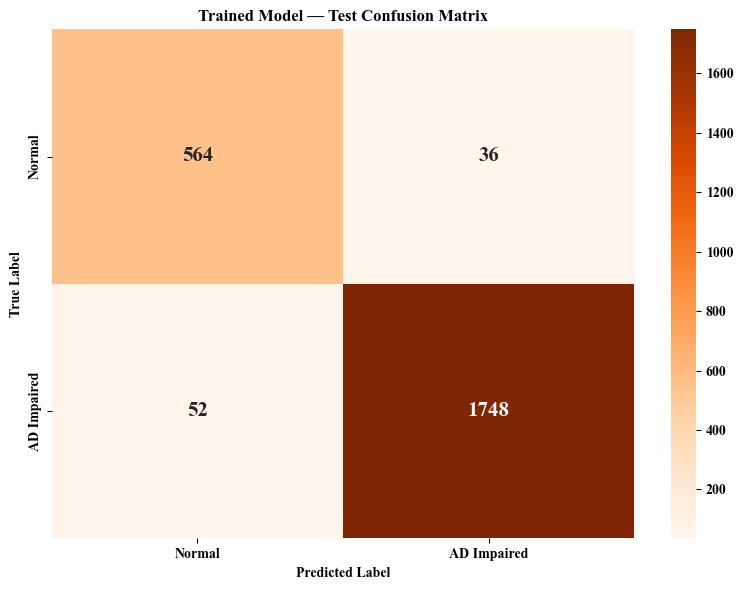


FINAL TEST METRICS


,Model,Test Samples,Accuracy,Precision,Macro Precision,Recall,Macro Recall,F1-score,Macro F1-score,AUC,MCC,Cohen Kappa
0,Trained EfficientNetB0-Based Model,2400,0.963333,0.979821,0.947703,0.971111,0.955556,0.975446,0.951539,0.992577,0.903224,0.903084



Saved test metrics: /kaggle/working/BCFedARFR_Results/Test_Evaluation/Test_Performance_Metrics.csv
Saved test predictions: /kaggle/working/BCFedARFR_Results/Test_Evaluation/Test_Predictions.csv


/kaggle/working/BCFedARFR_Results/Test_Evaluation/Test_Performance_Metrics.csv

/kaggle/working/BCFedARFR_Results/Test_Evaluation/Test_Predictions.csv

In [49]:
# ============================================================
# FINAL TEST EVALUATION — EXISTING TRAINED MODEL
# Model: model
# Dataset: test_ds
# Labels: 0 = Normal, 1 = AD Impaired
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. CHECK MODEL AND TEST DATA
# ------------------------------------------------------------

assert "model" in globals(), "Trained model 'model' not found."
assert "test_ds" in globals(), "Test dataset 'test_ds' not found."

print("Model:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

# ------------------------------------------------------------
# 2. COLLECT TRUE TEST LABELS
# ------------------------------------------------------------

y_true_batches = []

for images, labels in test_ds:
    y_true_batches.append(
        np.asarray(labels).reshape(-1)
    )

y_true = np.concatenate(y_true_batches).astype(int)

# ------------------------------------------------------------
# 3. PREDICT TEST PROBABILITIES
# ------------------------------------------------------------

y_prob = model.predict(test_ds, verbose=1).reshape(-1)

if len(y_true) != len(y_prob):
    raise ValueError(
        f"Labels: {len(y_true)}, predictions: {len(y_prob)}. "
        "Check whether test_ds is shuffled or repeated."
    )

if not np.isfinite(y_prob).all():
    raise ValueError("Predictions contain invalid values.")

y_pred = (y_prob >= 0.5).astype(int)

# ------------------------------------------------------------
# 4. DISPLAY DISTRIBUTIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TEST DATA SUMMARY")
print("=" * 60)

print("Number of test samples:", len(y_true))
print("Actual class distribution:",
      dict(zip(*np.unique(y_true, return_counts=True))))
print("Predicted class distribution:",
      dict(zip(*np.unique(y_pred, return_counts=True))))

# ------------------------------------------------------------
# 5. CALCULATE METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

macro_precision = precision_score(
    y_true, y_pred,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

auc = (
    roc_auc_score(y_true, y_prob)
    if len(np.unique(y_true)) == 2
    else np.nan
)

mcc = matthews_corrcoef(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)

# ------------------------------------------------------------
# 6. PRINT CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "AD Impaired"],
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("CONFUSION MATRIX")
print(cm)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Normal", "AD Impaired"],
    yticklabels=["Normal", "AD Impaired"],
    annot_kws={"size": 15, "weight": "bold"}
)

plt.title("Trained Model — Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. CREATE METRICS TABLE
# ------------------------------------------------------------

metrics_df = pd.DataFrame([{
    "Model": "Trained EfficientNetB0-Based Model",
    "Test Samples": len(y_true),
    "Accuracy": accuracy,
    "Precision": precision,
    "Macro Precision": macro_precision,
    "Recall": recall,
    "Macro Recall": macro_recall,
    "F1-score": f1,
    "Macro F1-score": macro_f1,
    "AUC": auc,
    "MCC": mcc,
    "Cohen Kappa": kappa
}])

print("\nFINAL TEST METRICS")
display(metrics_df.round(6))

# ------------------------------------------------------------
# 9. SAVE METRICS AND PREDICTIONS
# ------------------------------------------------------------

output_dir = "/kaggle/working/BCFedARFR_Results/Test_Evaluation"
os.makedirs(output_dir, exist_ok=True)

metrics_path = os.path.join(
    output_dir, "Test_Performance_Metrics.csv"
)

predictions_path = os.path.join(
    output_dir, "Test_Predictions.csv"
)

metrics_df.to_csv(metrics_path, index=False)

pd.DataFrame({
    "True Label": y_true,
    "Predicted Probability": y_prob,
    "Predicted Label": y_pred
}).to_csv(predictions_path, index=False)

print("\nSaved test metrics:", metrics_path)
print("Saved test predictions:", predictions_path)

display(FileLink(metrics_path))
display(FileLink(predictions_path))

In [50]:
# CHECK WHETHER THE ROUND 1 VARIABLES EXIST

for name in ["global_model", "global_test_ds", "model", "test_ds"]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT FOUND'}")

global_model: NOT FOUND
global_test_ds: NOT FOUND
model: AVAILABLE
test_ds: AVAILABLE


In [54]:
# ============================================================
# CHECK WHICH MODEL AND TEST DATA VARIABLES EXIST
# ============================================================

print("MODEL VARIABLES:")
for name, obj in globals().copy().items():
    if isinstance(obj, tf.keras.Model):
        print(
            f"{name}: input={obj.input_shape}, "
            f"output={obj.output_shape}"
        )

print("\nTEST DATA VARIABLES:")
for name in [
    "test_ds",
    "global_test_ds",
    "val_ds",
    "model",
    "history",
    "client_models",
    "round_accuracies"
]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT FOUND'}")

MODEL VARIABLES:
data_augmentation: input=(None, 224, 224, 3), output=(None, 224, 224, 3)
backbone: input=(None, 224, 224, 3), output=(None, 7, 7, 1280)
model: input=(None, 224, 224, 3), output=(None, 1)

TEST DATA VARIABLES:
test_ds: AVAILABLE
global_test_ds: NOT FOUND
val_ds: AVAILABLE
model: AVAILABLE
history: AVAILABLE
client_models: NOT FOUND
round_accuracies: NOT FOUND


In [55]:
# ============================================================
# CHECK STEP 5 — FEDERATED CLIENT PARTITIONING
# ============================================================

import os

print("FEDERATED CLIENT PARTITIONING STATUS")
print("=" * 55)

# Check in-memory client variables
for name in [
    "client_dfs",
    "client_datasets",
    "client_1_ds",
    "client_2_ds",
    "client_3_ds",
    "client_4_ds",
    "train_df",
    "train_ds"
]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT FOUND'}")

# Check saved client CSV files
client_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Clients"
)

print("\nSaved client files:")

if os.path.isdir(client_dir):
    files = [
        f for f in os.listdir(client_dir)
        if f.lower().endswith(".csv")
    ]

    if files:
        for f in sorted(files):
            print("-", f)
    else:
        print("No client CSV files found.")
else:
    print("Client directory not found.")

FEDERATED CLIENT PARTITIONING STATUS
client_dfs: NOT FOUND
client_datasets: AVAILABLE
client_1_ds: NOT FOUND
client_2_ds: NOT FOUND
client_3_ds: NOT FOUND
client_4_ds: NOT FOUND
train_df: AVAILABLE
train_ds: AVAILABLE

Saved client files:
- Client_1.csv
- Client_2.csv
- Client_3.csv
- Client_4.csv


In [56]:

import os
import pandas as pd
import tensorflow as tf

client_dir = "/kaggle/working/BCFedARFR_Results/Federated_Clients"

print("=" * 60)
print("STEP 5 — FEDERATED CLIENT PARTITION VERIFICATION")
print("=" * 60)

# 1. Inspect the available client_datasets object
print("\nclient_datasets type:", type(client_datasets))

if isinstance(client_datasets, (list, tuple, dict)):
    if isinstance(client_datasets, dict):
        items = list(client_datasets.items())
    else:
        items = list(enumerate(client_datasets, start=1))

    print("Number of client dataset entries:", len(items))

    for client_id, ds in items:
        print(f"\nClient {client_id}")
        print("Dataset type:", type(ds))

        if isinstance(ds, tf.data.Dataset):
            print("Element specification:", ds.element_spec)
            print("Cardinality:",
                  tf.data.experimental.cardinality(ds).numpy())

# 2. Inspect each saved CSV
print("\n" + "=" * 60)
print("SAVED CLIENT CSV DETAILS")
print("=" * 60)

for i in range(1, 5):
    path = os.path.join(client_dir, f"Client_{i}.csv")

    if os.path.exists(path):
        df = pd.read_csv(path)

        print(f"\nClient {i}")
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print("Missing values:", int(df.isna().sum().sum()))

        if "binary_label" in df.columns:
            print("Label counts:")
            print(df["binary_label"].value_counts().sort_index().to_dict())
        elif "label" in df.columns:
            print("Label counts:")
            print(df["label"].value_counts().sort_index().to_dict())
    else:
        print(f"\nClient {i}: CSV NOT FOUND")


STEP 5 — FEDERATED CLIENT PARTITION VERIFICATION

client_datasets type: <class 'dict'>
Number of client dataset entries: 4

Client Client_1
Dataset type: <class 'pandas.core.frame.DataFrame'>

Client Client_2
Dataset type: <class 'pandas.core.frame.DataFrame'>

Client Client_3
Dataset type: <class 'pandas.core.frame.DataFrame'>

Client Client_4
Dataset type: <class 'pandas.core.frame.DataFrame'>

SAVED CLIENT CSV DETAILS

Client 1
Rows: 2800
Columns: ['filepath', 'original_class', 'binary_label']
Missing values: 0
Label counts:
{0: 700, 1: 2100}

Client 2
Rows: 2800
Columns: ['filepath', 'original_class', 'binary_label']
Missing values: 0
Label counts:
{0: 700, 1: 2100}

Client 3
Rows: 2800
Columns: ['filepath', 'original_class', 'binary_label']
Missing values: 0
Label counts:
{0: 700, 1: 2100}

Client 4
Rows: 2800
Columns: ['filepath', 'original_class', 'binary_label']
Missing values: 0
Label counts:
{0: 700, 1: 2100}


In [57]:

import pandas as pd

client_frames = {
    str(name): frame.copy()
    for name, frame in client_datasets.items()
}

# Check client-to-client overlap
all_paths = []
for name, frame in client_frames.items():
    if "filepath" not in frame.columns:
        raise ValueError(f"{name} has no filepath column")
    all_paths.extend(frame["filepath"].astype(str).tolist())

print("Total client rows:", len(all_paths))
print("Unique client image paths:", len(set(all_paths)))
print("Duplicate paths across clients:", len(all_paths) - len(set(all_paths)))

# Check whether all client images belong to the training split
train_paths = set(train_df["filepath"].astype(str))
client_paths = set(all_paths)

print("Client paths found in train_df:", len(client_paths & train_paths))
print("Client paths NOT found in train_df:", len(client_paths - train_paths))

assert len(all_paths) == len(set(all_paths)), \
    "Duplicate images exist across client partitions!"

assert client_paths.issubset(train_paths), \
    "Some client images are not in train_df!"

print("\nStep 5 verification passed.")


Total client rows: 11200
Unique client image paths: 11200
Duplicate paths across clients: 0
Client paths found in train_df: 11200
Client paths NOT found in train_df: 0

Step 5 verification passed.


In [58]:

# ============================================================
# STEP 6 + STEP 7
# BCFedARFR-ApeNet FEDERATED LEARNING
# 4 CLIENTS | 20 COMMUNICATION ROUNDS | FEDAVG
# ============================================================

import os
import gc
import json
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf

from datetime import datetime

# ---------------- CONFIGURATION ----------------
NUM_CLIENTS = 4
COMMUNICATION_ROUNDS = 20
LOCAL_EPOCHS = 1
BATCH_SIZE = 16
IMAGE_SIZE = (224, 224)

CLIENT_DIR = (
    "/kaggle/working/BCFedARFR_Results/Federated_Clients"
)
RESULT_DIR = (
    "/kaggle/working/BCFedARFR_Results/Federated_Training"
)

os.makedirs(RESULT_DIR, exist_ok=True)

print("=" * 65)
print("BCFedARFR-ApeNet FEDERATED LEARNING")
print("=" * 65)
print("Clients:", NUM_CLIENTS)
print("Communication rounds:", COMMUNICATION_ROUNDS)
print("Local epochs per client per round:", LOCAL_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Gaussian noise augmentation: NOT USED")
print("Early stopping: NOT USED")
print("Learning-rate decay: NOT USED")

# ---------------- VERIFY EXISTING MODEL ----------------
if "model" not in globals():
    raise NameError(
        "The existing model variable was not found. "
        "Run the model-building cells first."
    )

if "train_df" not in globals():
    raise NameError("train_df is missing. Run the data preparation cells.")

if "val_ds" not in globals():
    raise NameError("val_ds is missing. Run the validation dataset cell.")

if "test_ds" not in globals():
    raise NameError("test_ds is missing. Run the test dataset cell.")

assert "filepath" in train_df.columns
assert "binary_label" in train_df.columns

# Load the four saved partitions
client_frames = {}

for i in range(1, NUM_CLIENTS + 1):
    csv_path = os.path.join(CLIENT_DIR, f"Client_{i}.csv")

    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Missing client CSV: {csv_path}")

    df = pd.read_csv(csv_path)

    required_cols = {"filepath", "binary_label"}
    if not required_cols.issubset(df.columns):
        raise ValueError(
            f"Client {i} must contain {required_cols}"
        )

    if df[["filepath", "binary_label"]].isna().any().any():
        raise ValueError(f"Missing paths or labels in Client {i}")

    if not set(df["binary_label"].unique()).issubset({0, 1}):
        raise ValueError(f"Unexpected labels in Client {i}")

    client_frames[f"Client_{i}"] = df.reset_index(drop=True)

# Check cross-client uniqueness and training-split membership
all_client_paths = [
    str(path)
    for df in client_frames.values()
    for path in df["filepath"]
]

if len(all_client_paths) != len(set(all_client_paths)):
    raise ValueError("Duplicate image paths exist across clients.")

train_paths = set(train_df["filepath"].astype(str))
client_paths = set(all_client_paths)

if not client_paths.issubset(train_paths):
    raise ValueError("Client files contain paths outside train_df.")

print("\nClient partitions verified:")
for name, df in client_frames.items():
    print(
        f"{name}: {len(df)} images | "
        f"labels={df['binary_label'].value_counts().to_dict()}"
    )

print("\nAll client paths are unique and belong to train_df.")


BCFedARFR-ApeNet FEDERATED LEARNING
Clients: 4
Communication rounds: 20
Local epochs per client per round: 1
Batch size: 16
Gaussian noise augmentation: NOT USED
Early stopping: NOT USED
Learning-rate decay: NOT USED

Client partitions verified:
Client_1: 2800 images | labels={1: 2100, 0: 700}
Client_2: 2800 images | labels={1: 2100, 0: 700}
Client_3: 2800 images | labels={1: 2100, 0: 700}
Client_4: 2800 images | labels={1: 2100, 0: 700}

All client paths are unique and belong to train_df.


In [59]:

# ============================================================
# CREATE CLIENT IMAGE DATASETS
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

def load_mri_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        antialias=True
    )

    # EfficientNetB0 commonly expects pixel values in 0–255
    # when its built-in preprocessing layers are used.
    image = tf.cast(image, tf.float32)

    label = tf.cast(label, tf.float32)
    label = tf.reshape(label, [1])

    return image, label


def create_client_dataset(df, shuffle=True):
    paths = df["filepath"].astype(str).to_numpy()
    labels = df["binary_label"].astype("float32").to_numpy()

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(df), 2000),
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_mri_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


client_train_ds = {
    name: create_client_dataset(df, shuffle=True)
    for name, df in client_frames.items()
}

print("Client TensorFlow datasets created successfully.")

for name, ds in client_train_ds.items():
    print(name, "->", ds.element_spec)


Client TensorFlow datasets created successfully.
Client_1 -> (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
Client_2 -> (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
Client_3 -> (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
Client_4 -> (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))


In [61]:

# ============================================================
# DIAGNOSE LAMBDA LAYERS IN THE EXISTING MODEL
# ============================================================

import tensorflow as tf

print("Model:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nLambda layers:")
found = False

for layer in model.layers:
    if isinstance(layer, tf.keras.layers.Lambda):
        found = True
        print("\nLayer name:", layer.name)
        print("Output shape:", getattr(layer, "output_shape", "not exposed"))

        try:
            print("Output tensor shape:", layer.output.shape)
        except Exception as exc:
            print("Could not read output tensor shape:", exc)

        try:
            print("Lambda configuration:", layer.get_config())
        except Exception as exc:
            print("Could not read configuration:", exc)

if not found:
    print("No top-level Lambda layers found.")
    print("The problematic layer may be nested inside another model.")

print("\nDiagnostic complete. No training performed.")


Model: BCFedARFR_ApeNet_Core
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)

Lambda layers:

Layer name: Coordinate_Attention_WidthPool
Output shape: not exposed
Output tensor shape: (None, 1, 7, 1280)
Lambda configuration: {'name': 'Coordinate_Attention_WidthPool', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'mixed_float16'}, 'registered_name': None}, 'function': {'class_name': '__lambda__', 'config': {'code': '4wEAAAAAAAAAAAAAAAYAAAATAAAA8ywAAACVAFsAAAAAAAAAAABSAwAAAAAAAAAAAAAAAAAAAAAA\nAFUAUwFTAlMDOQMkACkETukBAAAAVKkC2gRheGlz2ghrZWVwZGltc6kC2gJ0ZtoLcmVkdWNlX21l\nYW6pAdoBdHMBAAAAINofL3RtcC9pcHlrZXJuZWxfNDgvMTg5NDE1NTg5MC5wedoIPGxhbWJkYT7a\nJmNvb3JkaW5hdGVfYXR0ZW50aW9uLjxsb2NhbHM+LjxsYW1iZGE+wQAAAPMZAAAAgACUIpcukS7Y\nDA2QQaAE8AMAEyHxAAITCvMAAAAA\n', 'defaults': None, 'closure': None}}, 'arguments': {}}

Layer name: Coordinate_Attention_HeightPool
Output shape: not exposed
Output tensor shape: (None, 7, 1, 1280)
Lambda confi

In [62]:

# Check whether the original model-building functions still exist
for name in [
    "coordinate_attention",
    "adaptive_residual_feature_refinement",
    "build_model",
    "build_bcfedarfra_penet",
    "EfficientNetB0",
]:
    obj = globals().get(name)
    print(f"{name}: {'AVAILABLE' if callable(obj) else 'NOT FOUND'}")


coordinate_attention: AVAILABLE
adaptive_residual_feature_refinement: NOT FOUND
build_model: NOT FOUND
build_bcfedarfra_penet: NOT FOUND
EfficientNetB0: AVAILABLE


In [63]:

import inspect

print("=" * 60)
print("COORDINATE ATTENTION FUNCTION")
print("=" * 60)

print(inspect.getsource(coordinate_attention))


COORDINATE ATTENTION FUNCTION
def coordinate_attention(x, reduction=32, name="CoordinateAttention"):

    channels = int(x.shape[-1])
    height = int(x.shape[1])
    width = int(x.shape[2])

    reduced_channels = max(
        8,
        channels // reduction
    )

    # Height and width descriptors
    h_pool = layers.Lambda(
        lambda t: tf.reduce_mean(
            t, axis=2, keepdims=True
        ),
        name=f"{name}_HeightPool"
    )(x)

    w_pool = layers.Lambda(
        lambda t: tf.reduce_mean(
            t, axis=1, keepdims=True
        ),
        name=f"{name}_WidthPool"
    )(x)

    w_pool = layers.Permute(
        (2, 1, 3),
        name=f"{name}_WidthPermute"
    )(w_pool)

    y = layers.Concatenate(
        axis=1,
        name=f"{name}_Concat"
    )([h_pool, w_pool])

    y = layers.Conv2D(
        reduced_channels,
        kernel_size=1,
        padding="same",
        use_bias=False,
        name=f"{name}_ReduceConv"
    )(y)

    y = layers.BatchNormaliz

In [65]:
# ============================================================
# CELL 3 — FEDERATED TRAINING + FEDAVG
# BCFedARFR-ApeNet
# 4 CLIENTS | 20 COMMUNICATION ROUNDS | 1 LOCAL EPOCH
# ============================================================

import os
import gc
import json
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------
NUM_CLIENTS = 4
COMMUNICATION_ROUNDS = 20
LOCAL_EPOCHS = 1
LEARNING_RATE = 1e-4

FED_DIR = "/kaggle/working/BCFedARFR_Results/Federated_Training"
os.makedirs(FED_DIR, exist_ok=True)

ROUND_CSV = os.path.join(FED_DIR, "round_metrics.csv")
LEDGER_CSV = os.path.join(FED_DIR, "update_verification_ledger.csv")
TEST_CSV = os.path.join(FED_DIR, "final_test_metrics.csv")
MODEL_PATH = os.path.join(FED_DIR, "BCFedARFR_FedAvg_Final.keras")

# ------------------------------------------------------------
# 2. CHECK REQUIRED VARIABLES
# ------------------------------------------------------------
for variable in ["model", "client_train_ds", "val_ds", "test_ds"]:
    if variable not in globals():
        raise RuntimeError(
            f"{variable} is missing. Run the previous setup cells first."
        )

client_names = [f"Client_{i}" for i in range(1, NUM_CLIENTS + 1)]

for client_name in client_names:
    if client_name not in client_train_ds:
        raise RuntimeError(f"{client_name} is missing from client_train_ds.")

print("=" * 65)
print("BCFedARFR-ApeNet FEDERATED TRAINING")
print("=" * 65)
print("Clients:", NUM_CLIENTS)
print("Communication rounds:", COMMUNICATION_ROUNDS)
print("Local epochs:", LOCAL_EPOCHS)
print("Aggregation: FedAvg")
print("Gaussian noise: NOT USED")
print("=" * 65)

# ------------------------------------------------------------
# 3. RESTORE INITIAL WEIGHTS IF AVAILABLE
# ------------------------------------------------------------
global_model = model

if "starting_weights" in globals():
    global_model.set_weights(starting_weights)
    print("Restored saved starting weights.")
else:
    starting_weights = [
        np.array(w, copy=True)
        for w in global_model.get_weights()
    ]
    print("Saved current global-model weights as starting weights.")

# ------------------------------------------------------------
# 4. COMPILE WITH A FRESH OPTIMIZER
# ------------------------------------------------------------
def reset_optimizer_and_compile():
    base_optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

    # Use loss scaling for mixed-float16 models.
    if global_model.dtype_policy.name == "mixed_float16":
        optimizer = tf.keras.mixed_precision.LossScaleOptimizer(
            base_optimizer
        )
    else:
        optimizer = base_optimizer

    global_model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )

reset_optimizer_and_compile()

# ------------------------------------------------------------
# 5. HELPER FUNCTIONS
# ------------------------------------------------------------
def hash_model_weights(weights):
    digest = hashlib.sha256()

    for weight in weights:
        array = np.ascontiguousarray(weight)
        digest.update(str(array.shape).encode())
        digest.update(str(array.dtype).encode())
        digest.update(array.tobytes())

    return digest.hexdigest()


def count_dataset_samples(dataset):
    total = 0

    for _, labels in dataset:
        total += int(tf.shape(labels)[0].numpy())

    return total


def fedavg(client_weights, sample_counts):
    total_samples = float(sum(sample_counts))

    if total_samples <= 0:
        raise ValueError("No client samples available.")

    averaged_weights = []

    for layer_weights in zip(*client_weights):
        average = np.zeros_like(
            layer_weights[0],
            dtype=np.float64
        )

        for weights, count in zip(layer_weights, sample_counts):
            average += weights.astype(np.float64) * (
                count / total_samples
            )

        averaged_weights.append(
            average.astype(layer_weights[0].dtype)
        )

    return averaged_weights


def evaluate_model(dataset):
    results = global_model.evaluate(
        dataset,
        verbose=0,
        return_dict=True
    )

    return {k: float(v) for k, v in results.items()}


# ------------------------------------------------------------
# 6. COUNT CLIENT DATA
# ------------------------------------------------------------
client_sample_counts = {}

for client_name in client_names:
    count = count_dataset_samples(client_train_ds[client_name])

    if count <= 0:
        raise ValueError(f"{client_name} has no training data.")

    client_sample_counts[client_name] = count

print("\nCLIENT SAMPLE COUNTS")

for name, count in client_sample_counts.items():
    print(f"{name}: {count}")

# ------------------------------------------------------------
# 7. INITIALIZE METRIC RECORDS AND VERIFICATION LEDGER
# ------------------------------------------------------------
round_records = []
ledger_records = []

previous_ledger_hash = "GENESIS"

initial_global_hash = hash_model_weights(
    global_model.get_weights()
)

print("\nInitial global-model hash:", initial_global_hash)

# ------------------------------------------------------------
# 8. FEDERATED COMMUNICATION ROUNDS
# ------------------------------------------------------------
for round_number in range(1, COMMUNICATION_ROUNDS + 1):

    print("\n" + "=" * 65)
    print(f"COMMUNICATION ROUND {round_number}/{COMMUNICATION_ROUNDS}")
    print("=" * 65)

    # Save global weights at the beginning of this round.
    round_start_weights = [
        np.array(w, copy=True)
        for w in global_model.get_weights()
    ]

    client_updates = []
    round_sample_counts = []

    # --------------------------------------------------------
    # 8A. TRAIN EACH CLIENT LOCALLY
    # --------------------------------------------------------
    for client_name in client_names:

        print(f"\nTraining {client_name}...")

        # Every client begins from the same round-start weights.
        global_model.set_weights(round_start_weights)
        reset_optimizer_and_compile()

        local_history = global_model.fit(
            client_train_ds[client_name],
            epochs=LOCAL_EPOCHS,
            verbose=1
        )

        local_weights = [
            np.array(w, copy=True)
            for w in global_model.get_weights()
        ]

        client_updates.append(local_weights)
        round_sample_counts.append(
            client_sample_counts[client_name]
        )

        # ----------------------------------------------------
        # 8B. HASH-BASED UPDATE VERIFICATION RECORD
        # ----------------------------------------------------
        update_hash = hash_model_weights(local_weights)

        payload = {
            "round": round_number,
            "client": client_name,
            "sample_count": client_sample_counts[client_name],
            "update_hash": update_hash,
            "previous_ledger_hash": previous_ledger_hash
        }

        canonical_payload = json.dumps(
            payload,
            sort_keys=True,
            separators=(",", ":")
        )

        ledger_hash = hashlib.sha256(
            canonical_payload.encode("utf-8")
        ).hexdigest()

        ledger_records.append({
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "round": round_number,
            "client": client_name,
            "sample_count": client_sample_counts[client_name],
            "update_hash": update_hash,
            "previous_ledger_hash": previous_ledger_hash,
            "ledger_hash": ledger_hash,
            "verification_status": "HASH_RECORDED"
        })

        previous_ledger_hash = ledger_hash

        print("Update hash:", update_hash[:24], "...")

        del local_history
        gc.collect()

    # --------------------------------------------------------
    # 8C. FEDAVG AGGREGATION
    # --------------------------------------------------------
    print("\nPerforming FedAvg aggregation...")

    aggregated_weights = fedavg(
        client_updates,
        round_sample_counts
    )

    global_model.set_weights(aggregated_weights)
    reset_optimizer_and_compile()

    global_hash = hash_model_weights(
        global_model.get_weights()
    )

    print("Aggregated global hash:", global_hash)

    # --------------------------------------------------------
    # 8D. GLOBAL VALIDATION
    # --------------------------------------------------------
    val_metrics = evaluate_model(val_ds)

    record = {
        "round": round_number,
        "global_model_hash": global_hash,
        "val_loss": val_metrics.get("loss", np.nan),
        "val_accuracy": val_metrics.get("accuracy", np.nan),
        "val_auc": val_metrics.get("auc", np.nan),
        "val_precision": val_metrics.get("precision", np.nan),
        "val_recall": val_metrics.get("recall", np.nan)
    }

    round_records.append(record)

    # Save results after every round.
    pd.DataFrame(round_records).to_csv(
        ROUND_CSV,
        index=False
    )

    pd.DataFrame(ledger_records).to_csv(
        LEDGER_CSV,
        index=False
    )

    print("\nGLOBAL VALIDATION RESULTS")

    for metric_name, metric_value in val_metrics.items():
        print(f"{metric_name}: {metric_value:.4f}")

    print("Round metrics saved:", ROUND_CSV)
    print("Verification ledger saved:", LEDGER_CSV)

    del client_updates, aggregated_weights
    gc.collect()

# ------------------------------------------------------------
# 9. FINAL TEST EVALUATION
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("FINAL GLOBAL MODEL — TEST RESULTS")
print("=" * 65)

reset_optimizer_and_compile()
test_metrics = evaluate_model(test_ds)

for metric_name, metric_value in test_metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")

# ------------------------------------------------------------
# 10. SAVE FINAL MODEL AND RESULTS
# ------------------------------------------------------------
global_model.save(MODEL_PATH)

pd.DataFrame(round_records).to_csv(
    ROUND_CSV,
    index=False
)

pd.DataFrame(ledger_records).to_csv(
    LEDGER_CSV,
    index=False
)

pd.DataFrame([
    {"metric": name, "value": value}
    for name, value in test_metrics.items()
]).to_csv(
    TEST_CSV,
    index=False
)

print("\n" + "=" * 65)
print("FEDERATED TRAINING COMPLETED")
print("=" * 65)
print("Final model:", MODEL_PATH)
print("Round metrics:", ROUND_CSV)
print("Verification ledger:", LEDGER_CSV)
print("Final test metrics:", TEST_CSV)
print("=" * 65)

BCFedARFR-ApeNet FEDERATED TRAINING
Clients: 4
Communication rounds: 20
Local epochs: 1
Aggregation: FedAvg
Gaussian noise: NOT USED
Restored saved starting weights.

CLIENT SAMPLE COUNTS
Client_1: 2800
Client_2: 2800
Client_3: 2800
Client_4: 2800

Initial global-model hash: b737f5257fff0558f75e198324b2884b34bb6d01929da7d17e0d447decdcdc57

COMMUNICATION ROUND 1/20

Training Client_1...
175/175 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.9839 - auc: 0.9959 - loss: 0.0482 - precision: 0.9867 - recall: 0.9919
Update hash: df738b08f55d82137d23a5d0 ...

Training Client_2...
175/175 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.9850 - auc: 0.9981 - loss: 0.0399 - precision: 0.9900 - recall: 0.9900
Update hash: db83e4c5fdc66621d9739d29 ...

Training Client_3...
175/175 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.9811 - auc: 0.9966 - loss: 0.0558 - precision: 0.9858 - recall: 0.9890
Update hash: 541ab1159b2ae9d73cb0305a ...

Training Client_4...
175/175 ━━━━━━━━━━━━━━━━━━━━ 22s 48

In [66]:
import pandas as pd
import os

results_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)

round_df = pd.read_csv(
    os.path.join(results_dir, "round_metrics.csv")
)

print("NUMBER OF RECORDED COMMUNICATION ROUNDS:",
      len(round_df))

display(round_df)

print("\nAVAILABLE METRICS:")
print(round_df.columns.tolist())

NUMBER OF RECORDED COMMUNICATION ROUNDS: 20


,round,global_model_hash,val_loss,val_accuracy,val_auc,val_precision,val_recall
0,1,f706924218a4039b6ccff49d1362ed9bd8aa64c6e29e71...,0.086574,0.970417,0.991620,0.982153,0.978333
1,2,c39d5241a5b05e4d095d82f93da3f98961795c3d8ef7f9...,0.091268,0.969583,0.991583,0.984296,0.975000
2,3,533a83c3f4b9b165a4baac5b255bc7727693f359e4082e...,0.084742,0.972500,0.990858,0.984358,0.978889
3,4,bbf2d529f21b00fee13c2198c686d8704eac943a0b2bb2...,0.084792,0.975833,0.991005,0.986592,0.981111
4,5,3fbc0de338a4bc59aa42dfa508e07b863d83c9f7944031...,0.086263,0.972500,0.990374,0.983278,0.980000
5,6,3cd16670d40fdf42cec9ce22ad257c81ce72ecfb5b05ef...,0.088755,0.972500,0.989979,0.983278,0.980000
6,7,cdd09e5e56832857b4e6baa764d5520875a0aa65292d5b...,0.091479,0.975417,0.990017,0.987675,0.979444
7,8,5835be1eec9c786c85f0c75b1a15973be0dfa32c7c7ade...,0.089712,0.975833,0.990201,0.987682,0.980000
8,9,bc2ab952d16eac13d6bd5c8e384ac003566791fa6d571f...,0.093103,0.975833,0.989762,0.987136,0.980556
9,10,7cd5eedd40ca986320fdb47294fc42be01fd972d4dea64...,0.086861,0.977083,0.990301,0.986615,0.982778



AVAILABLE METRICS:
['round', 'global_model_hash', 'val_loss', 'val_accuracy', 'val_auc', 'val_precision', 'val_recall']


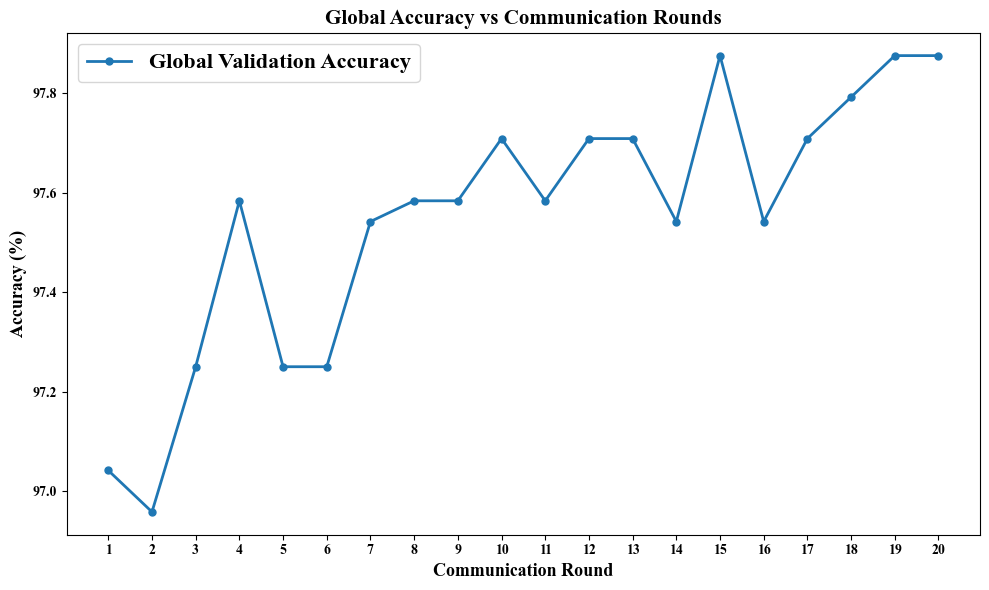

Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/global_accuracy_vs_rounds.png


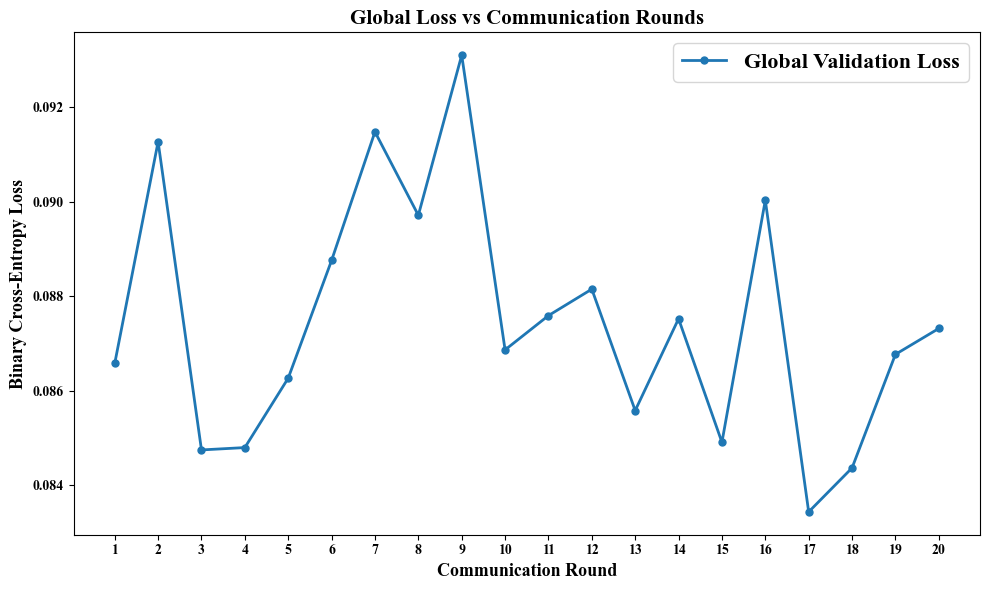

Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/global_loss_vs_rounds.png

COMMUNICATION ROUND / CONVERGENCE TABLE


,round,val_loss,val_accuracy,val_auc,val_precision,val_recall,val_accuracy_percent,accuracy_change_percentage_points,loss_change
0,1,0.086574,0.970417,0.991620,0.982153,0.978333,97.041667,NaN,NaN
1,2,0.091268,0.969583,0.991583,0.984296,0.975000,96.958333,-0.0833,0.004695
2,3,0.084742,0.972500,0.990858,0.984358,0.978889,97.250003,0.2917,-0.006526
3,4,0.084792,0.975833,0.991005,0.986592,0.981111,97.583336,0.3333,0.000050
4,5,0.086263,0.972500,0.990374,0.983278,0.980000,97.250003,-0.3333,0.001471
5,6,0.088755,0.972500,0.989979,0.983278,0.980000,97.250003,0.0000,0.002492
6,7,0.091479,0.975417,0.990017,0.987675,0.979444,97.541666,0.2917,0.002724
7,8,0.089712,0.975833,0.990201,0.987682,0.980000,97.583336,0.0417,-0.001767
8,9,0.093103,0.975833,0.989762,0.987136,0.980556,97.583336,0.0000,0.003391
9,10,0.086861,0.977083,0.990301,0.986615,0.982778,97.708333,0.1250,-0.006241


Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/communication_round_convergence.csv

RESULT SUMMARY
-------------------------------------------------------
Rounds recorded: 20
First-round accuracy: 0.9704
Final-round accuracy: 0.9787
Best accuracy: 0.9787 (Round 15)
Lowest validation loss: 0.08343 (Round 17)
-------------------------------------------------------


In [68]:
# ============================================================
# FEDERATED RESULTS — ACCURACY, LOSS, CONVERGENCE
# Uses actual metrics from all 20 communication rounds
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)

ROUND_CSV = os.path.join(RESULTS_DIR, "round_metrics.csv")

# ------------------------------------------------------------
# 1. LOAD RECORDED RESULTS
# ------------------------------------------------------------
df = pd.read_csv(ROUND_CSV)
df = df.sort_values("round").reset_index(drop=True)

required_columns = [
    "round", "val_loss", "val_accuracy",
    "val_auc", "val_precision", "val_recall"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

if len(df) != 20:
    print(f"Warning: expected 20 rounds, found {len(df)}")

# ------------------------------------------------------------
# 2. GLOBAL ACCURACY VS COMMUNICATION ROUNDS
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    df["round"],
    df["val_accuracy"] * 100,
    marker="o",
    linewidth=2,
    markersize=5,
    label="Global Validation Accuracy"
)

plt.xlabel("Communication Round", fontsize=13, fontweight="bold")
plt.ylabel("Accuracy (%)", fontsize=13, fontweight="bold")
plt.title(
    "Global Accuracy vs Communication Rounds",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(df["round"])

plt.legend(fontsize=16)
plt.tight_layout()

accuracy_path = os.path.join(
    RESULTS_DIR, "global_accuracy_vs_rounds.png"
)
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", accuracy_path)

# ------------------------------------------------------------
# 3. GLOBAL LOSS VS COMMUNICATION ROUNDS
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    df["round"],
    df["val_loss"],
    marker="o",
    linewidth=2,
    markersize=5,
    label="Global Validation Loss"
)

plt.xlabel("Communication Round", fontsize=13, fontweight="bold")
plt.ylabel("Binary Cross-Entropy Loss", fontsize=13, fontweight="bold")
plt.title(
    "Global Loss vs Communication Rounds",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(df["round"])

plt.legend(fontsize=16)
plt.tight_layout()

loss_path = os.path.join(
    RESULTS_DIR, "global_loss_vs_rounds.png"
)
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved:", loss_path)

# ------------------------------------------------------------
# 4. COMMUNICATION ROUND / CONVERGENCE TABLE
# ------------------------------------------------------------
convergence = df[[
    "round",
    "val_loss",
    "val_accuracy",
    "val_auc",
    "val_precision",
    "val_recall"
]].copy()

convergence["val_accuracy_percent"] = (
    convergence["val_accuracy"] * 100
)

convergence["accuracy_change_percentage_points"] = (
    convergence["val_accuracy"].diff() * 100
)

convergence["loss_change"] = convergence["val_loss"].diff()

convergence["accuracy_change_percentage_points"] = (
    convergence["accuracy_change_percentage_points"].round(4)
)
convergence["loss_change"] = convergence["loss_change"].round(6)

convergence_path = os.path.join(
    RESULTS_DIR, "communication_round_convergence.csv"
)

convergence.to_csv(convergence_path, index=False)

print("\nCOMMUNICATION ROUND / CONVERGENCE TABLE")
display(convergence.round(6))

print("Saved:", convergence_path)

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------
best_accuracy_row = df.loc[df["val_accuracy"].idxmax()]
lowest_loss_row = df.loc[df["val_loss"].idxmin()]

print("\nRESULT SUMMARY")
print("-" * 55)
print(f"Rounds recorded: {len(df)}")
print(f"First-round accuracy: {df.iloc[0]['val_accuracy']:.4f}")
print(f"Final-round accuracy: {df.iloc[-1]['val_accuracy']:.4f}")
print(
    f"Best accuracy: {best_accuracy_row['val_accuracy']:.4f} "
    f"(Round {int(best_accuracy_row['round'])})"
)
print(
    f"Lowest validation loss: {lowest_loss_row['val_loss']:.5f} "
    f"(Round {int(lowest_loss_row['round'])})"
)
print("-" * 55)

In [74]:
# ============================================================
# FIND EXISTING CLIENT-WISE METRICS CSV
# ============================================================

import os
import glob
import pandas as pd

BASE_DIR = "/kaggle/working/BCFedARFR_Results"

csv_files = glob.glob(
    os.path.join(BASE_DIR, "**", "*.csv"),
    recursive=True
)

print("CSV files found:\n")

for file in csv_files:
    print(file)

print("\n" + "=" * 60)
print("CHECKING CSV COLUMN NAMES")
print("=" * 60)

for file in csv_files:
    try:
        df = pd.read_csv(file)
        print(f"\nFile: {os.path.basename(file)}")
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    except Exception as e:
        print(f"Could not read {file}: {e}")

CSV files found:

/kaggle/working/BCFedARFR_Results/Federated_Clients/Client_2.csv
/kaggle/working/BCFedARFR_Results/Federated_Clients/Client_3.csv
/kaggle/working/BCFedARFR_Results/Federated_Clients/Client_4.csv
/kaggle/working/BCFedARFR_Results/Federated_Clients/Client_1.csv
/kaggle/working/BCFedARFR_Results/Federated_Metrics/Global_Test_Performance_Metrics.csv
/kaggle/working/BCFedARFR_Results/Federated_Metrics/Per_Client_Classification_Performance.csv
/kaggle/working/BCFedARFR_Results/Test_Evaluation/Test_Predictions.csv
/kaggle/working/BCFedARFR_Results/Test_Evaluation/Test_Performance_Metrics.csv
/kaggle/working/BCFedARFR_Results/Federated_Training/final_test_metrics.csv
/kaggle/working/BCFedARFR_Results/Federated_Training/update_verification_ledger.csv
/kaggle/working/BCFedARFR_Results/Federated_Training/round_metrics.csv
/kaggle/working/BCFedARFR_Results/Federated_Training/communication_round_convergence.csv

CHECKING CSV COLUMN NAMES

File: Client_2.csv
Columns: ['filepath', '

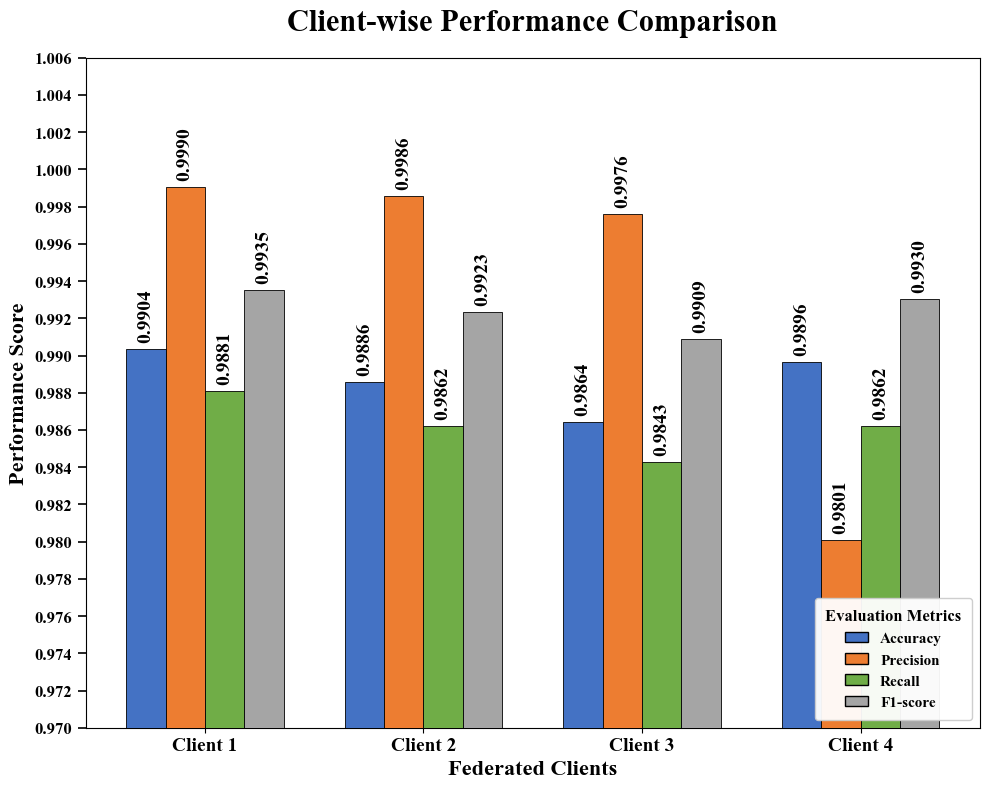

Graph saved successfully!
PNG path: /kaggle/working/BCFedARFR_Results/Federated_Metrics/Client_Wise_Performance_Comparison_Without_AUC.png

Values used:
  Client  Accuracy  Precision   Recall  F1-score
Client 1  0.990357   0.999037 0.988095  0.993536
Client 2  0.988571   0.998554 0.986190  0.992333
Client 3  0.986429   0.997587 0.984286  0.990892
Client 4  0.989643   0.980110 0.986190  0.993047


In [87]:
# ============================================================
# CLIENT-WISE PERFORMANCE COMPARISON — WITHOUT AUC
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

CSV_PATH = "/kaggle/working/BCFedARFR_Results/Federated_Metrics/Per_Client_Classification_Performance.csv"

OUTPUT_DIR = "/kaggle/working/BCFedARFR_Results/Federated_Metrics"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(CSV_PATH)

# Exclude AUC
client_col = "Client"
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]

# Consistent colours for each metric
colors = {
    "Accuracy": "#4472C4",
    "Precision": "#ED7D31",
    "Recall": "#70AD47",
    "F1-score": "#A5A5A5"
}

clients = df[client_col].astype(str).tolist()
x = np.arange(len(clients))
bar_width = 0.18

fig, ax = plt.subplots(figsize=(10, 8))

# Draw bars and labels
for i, metric in enumerate(metric_cols):
    values = df[metric].astype(float).to_numpy()
    positions = x + (i - (len(metric_cols) - 1) / 2) * bar_width

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        color=colors[metric],
        edgecolor="black",
        linewidth=0.6,
        zorder=3
    )

    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:.4f}",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            rotation=90,
            fontsize=14,
            fontweight="bold",
            clip_on=False
        )

# Titles and axes
ax.set_title(
    "Client-wise Performance Comparison",
    fontsize=22,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Federated Clients", fontsize=16, fontweight="bold")
ax.set_ylabel("Performance Score", fontsize=16, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(clients, fontsize=14, fontweight="bold")
ax.tick_params(axis="y", labelsize=11)



# Increase Y-axis tick frequency
ax.set_ylim(0.97, 1.005)

ax.set_yticks(np.arange(0.970, 1.006, 0.002))

ax.tick_params(
    axis="y",
    labelsize=12,
    width=1.2,
    length=6
)

ax.set_axisbelow(True)

# Legend inside graph — bottom right
legend_handles = [
    Patch(facecolor=colors[m], edgecolor="black", label=m)
    for m in metric_cols
]
ax.legend(
    handles=legend_handles,
    title="Evaluation Metrics",
    loc="lower right",
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    framealpha=0.95,
    borderpad=0.7,
    labelspacing=0.5,
    handlelength=1.5
)

plt.tight_layout()

# Save PNG
output_path = os.path.join(
    OUTPUT_DIR,
    "Client_Wise_Performance_Comparison_Without_AUC.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Graph saved successfully!")
print("PNG path:", output_path)
print("\nValues used:")
print(df[[client_col] + metric_cols].to_string(index=False))

FINAL FEDERATED GLOBAL MODEL
Test samples: 2400
Test accuracy: 0.9812

Confusion Matrix:
[[ 574   26]
 [  19 1781]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9680    0.9567    0.9623       600
 AD Impaired     0.9856    0.9894    0.9875      1800

    accuracy                         0.9812      2400
   macro avg     0.9768    0.9731    0.9749      2400
weighted avg     0.9812    0.9812    0.9812      2400



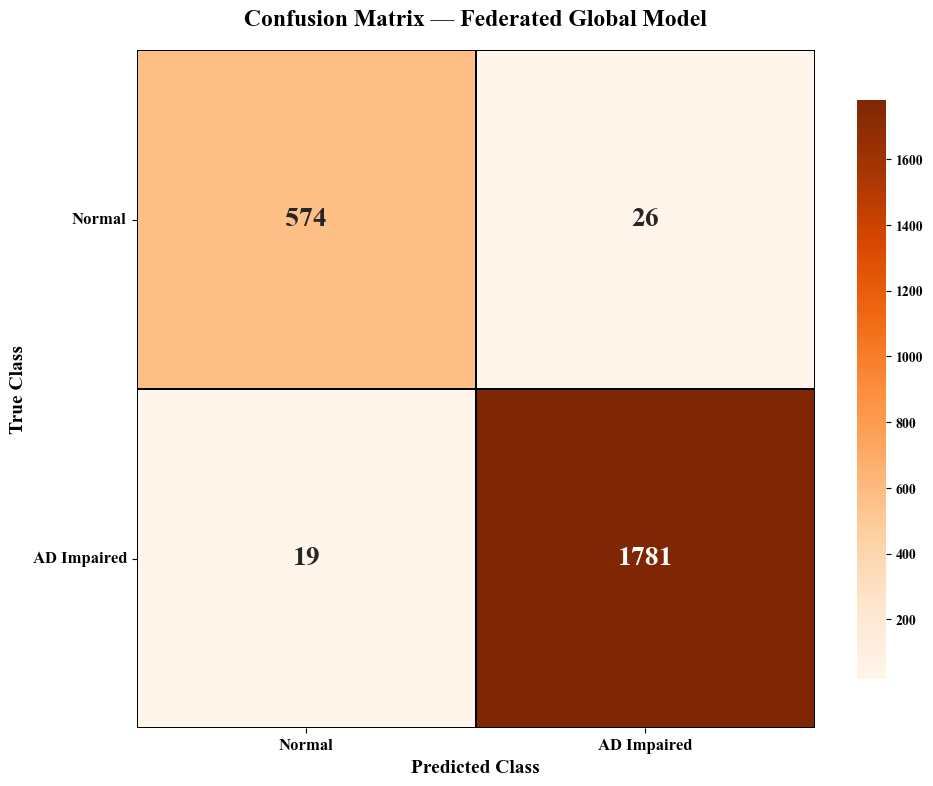


Confusion matrix saved to: /kaggle/working/BCFedARFR_Results/Federated_Metrics/Federated_Global_Model_Confusion_Matrix.png


In [88]:
# ============================================================
# FINAL FEDERATED GLOBAL MODEL — CONFUSION MATRIX
# Binary Alzheimer’s MRI Classification
# 0 = Normal
# 1 = AD Impaired
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/BCFedARFR_Results/Federated_Metrics"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. VERIFY FINAL GLOBAL MODEL AND TEST DATASET
# ------------------------------------------------------------

if "global_model" not in globals():
    raise NameError(
        "global_model is not available. Run this cell in the "
        "notebook containing the completed federated training."
    )

if "test_ds" not in globals():
    raise NameError(
        "test_ds is not available. Recreate the original test "
        "dataset using the same test split before proceeding."
    )

# ------------------------------------------------------------
# 3. TRUE LABELS AND GLOBAL MODEL PREDICTIONS
# ------------------------------------------------------------

y_true = []
y_prob = []

for images, labels in test_ds:
    probabilities = global_model.predict(images, verbose=0)

    y_true.extend(labels.numpy().reshape(-1).astype(int))
    y_prob.extend(probabilities.reshape(-1))

y_true = np.asarray(y_true)
y_prob = np.asarray(y_prob)

# Standard threshold for binary classification
y_pred = (y_prob >= 0.5).astype(int)

# ------------------------------------------------------------
# 4. COMPUTE CONFUSION MATRIX
# ------------------------------------------------------------

class_names = ["Normal", "AD Impaired"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("=" * 60)
print("FINAL FEDERATED GLOBAL MODEL")
print("=" * 60)
print("Test samples:", len(y_true))
print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f}")
print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 5. PLOT CONFUSION MATRIX
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    square=True,
    linewidths=1.2,
    linecolor="black",
    annot_kws={
        "size": 20,
        "weight": "bold"
    },
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"shrink": 0.85}
)

plt.title(
    "Confusion Matrix — Federated Global Model",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.xlabel("Predicted Class", fontsize=14, fontweight="bold")
plt.ylabel("True Class", fontsize=14, fontweight="bold")

plt.xticks(fontsize=12, fontweight="bold")
plt.yticks(fontsize=12, fontweight="bold", rotation=0)

plt.tight_layout()

cm_path = os.path.join(
    OUTPUT_DIR,
    "Federated_Global_Model_Confusion_Matrix.png"
)

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Save numeric matrix too
np.savetxt(
    os.path.join(OUTPUT_DIR, "Federated_Global_Confusion_Matrix.csv"),
    cm,
    delimiter=",",
    fmt="%d"
)

print("\nConfusion matrix saved to:", cm_path)

In [90]:
import os
import pandas as pd

BASE_DIR = "/kaggle/working/BCFedARFR_Results"

files_to_check = [
    os.path.join(
        BASE_DIR,
        "Federated_Training",
        "BCFedARFR_FedAvg_Final.keras"
    ),
    os.path.join(
        BASE_DIR,
        "Federated_Training",
        "update_verification_ledger.csv"
    ),
    os.path.join(
        BASE_DIR,
        "Federated_Training",
        "final_test_metrics.csv"
    ),
    os.path.join(
        BASE_DIR,
        "Federated_Training",
        "round_metrics.csv"
    )
]

for path in files_to_check:
    if os.path.exists(path):
        print(f"✅ FOUND: {path}")
    else:
        print(f"❌ NOT FOUND: {path}")

ledger_path = os.path.join(
    BASE_DIR,
    "Federated_Training",
    "update_verification_ledger.csv"
)

if os.path.exists(ledger_path):
    ledger = pd.read_csv(ledger_path)
    print("\nBlockchain-assisted verification ledger:")
    print(ledger.head())
    print("\nLedger shape:", ledger.shape)
    print("Columns:", ledger.columns.tolist())

✅ FOUND: /kaggle/working/BCFedARFR_Results/Federated_Training/BCFedARFR_FedAvg_Final.keras
✅ FOUND: /kaggle/working/BCFedARFR_Results/Federated_Training/update_verification_ledger.csv
✅ FOUND: /kaggle/working/BCFedARFR_Results/Federated_Training/final_test_metrics.csv
✅ FOUND: /kaggle/working/BCFedARFR_Results/Federated_Training/round_metrics.csv

Blockchain-assisted verification ledger:
                      timestamp_utc  round    client  sample_count  \
0  2026-10-12T05:36:01.603553+00:00      1  Client_1          2800   
1  2026-10-12T05:36:24.327971+00:00      1  Client_2          2800   
2  2026-10-12T05:36:47.191471+00:00      1  Client_3          2800   
3  2026-10-12T05:37:10.108599+00:00      1  Client_4          2800   
4  2026-10-12T05:37:45.165612+00:00      2  Client_1          2800   

                                         update_hash  \
0  df738b08f55d82137d23a5d0ac58e99b907d8a47f98aca...   
1  db83e4c5fdc66621d9739d29ff65d2139b72ac6c6384d4...   
2  541ab1159b2ae9d73

In [91]:
# ============================================================
# VERIFY HASH-LINKED FEDERATED UPDATE LEDGER
# ============================================================

import os
import json
import hashlib
import pandas as pd

ledger_path = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training/update_verification_ledger.csv"
)

ledger = pd.read_csv(ledger_path).fillna("")

required = [
    "round", "client", "sample_count", "update_hash",
    "previous_ledger_hash", "ledger_hash"
]

missing = [c for c in required if c not in ledger.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# The original hashing serialization must match the code that created
# the ledger. This checks links and reports recorded statuses first.
ledger = ledger.sort_values(
    ["round", "timestamp_utc", "client"]
).reset_index(drop=True)

link_results = []
for i, row in ledger.iterrows():
    if i == 0:
        link_ok = str(row["previous_ledger_hash"]) == "GENESIS"
    else:
        link_ok = (
            str(row["previous_ledger_hash"])
            == str(ledger.loc[i - 1, "ledger_hash"])
        )

    link_results.append(link_ok)

ledger["previous_hash_link_ok"] = link_results

print("Ledger rows:", len(ledger))
print("Rounds:", ledger["round"].nunique())
print("Clients:", ledger["client"].nunique())
print("\nRecorded status counts:")
print(ledger["verification_status"].value_counts(dropna=False))
print("\nPrevious-hash link checks:")
print(ledger["previous_hash_link_ok"].value_counts())
print("\nFirst rows:")
print(ledger.head().to_string(index=False))

print(
    "\nNote: confirming the row's own ledger hash requires the exact "
    "hashing formula and serialization used during ledger creation."
)

Ledger rows: 80
Rounds: 20
Clients: 4

Recorded status counts:
verification_status
HASH_RECORDED    80
Name: count, dtype: int64

Previous-hash link checks:
previous_hash_link_ok
True    80
Name: count, dtype: int64

First rows:
                   timestamp_utc  round   client  sample_count                                                      update_hash                                             previous_ledger_hash                                                      ledger_hash verification_status  previous_hash_link_ok
2026-10-12T05:36:01.603553+00:00      1 Client_1          2800 df738b08f55d82137d23a5d0ac58e99b907d8a47f98aca61e8fd4cffeefc75ee                                                          GENESIS 7ff1c8b0b7257f0d0619baf13cbd4b02cf3d91a8c14f921d86075eaa781144bb       HASH_RECORDED                   True
2026-10-12T05:36:24.327971+00:00      1 Client_2          2800 db83e4c5fdc66621d9739d29ff65d2139b72ac6c6384d43cd2d152128f755580 7ff1c8b0b7257f0d0619baf13cbd4b02cf3d91a8c

In [92]:
# ============================================================
# STEP 5 — BLOCKCHAIN-ASSISTED LEDGER HASH VERIFICATION
# Diagnostic check: test common SHA-256 row formats
# ============================================================

import os
import json
import hashlib
import pandas as pd

LEDGER_PATH = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training/update_verification_ledger.csv"
)

OUTPUT_DIR = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

ledger = pd.read_csv(LEDGER_PATH, dtype=str).fillna("")

required_cols = [
    "timestamp_utc",
    "round",
    "client",
    "sample_count",
    "update_hash",
    "previous_ledger_hash",
    "ledger_hash",
]

missing = [c for c in required_cols if c not in ledger.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Preserve the recorded order; do not sort or rewrite the source ledger.
ledger = ledger.reset_index(drop=True)

# ------------------------------------------------------------
# 1. CHECK PREVIOUS-HASH LINKS
# ------------------------------------------------------------

link_ok = []

for i, row in ledger.iterrows():
    expected_previous = (
        "GENESIS" if i == 0
        else ledger.loc[i - 1, "ledger_hash"]
    )
    link_ok.append(
        row["previous_ledger_hash"] == expected_previous
    )

ledger["previous_hash_link_ok"] = link_ok

# ------------------------------------------------------------
# 2. TRY COMMON ROW SERIALIZATION FORMATS
# ------------------------------------------------------------

# Candidate fields commonly included in a ledger row hash.
# These are diagnostic candidates, not assumptions about the
# original implementation.
field_candidates = [
    [
        "timestamp_utc", "round", "client", "sample_count",
        "update_hash", "previous_ledger_hash"
    ],
    [
        "round", "client", "sample_count",
        "update_hash", "previous_ledger_hash"
    ],
    [
        "timestamp_utc", "round", "client", "sample_count",
        "update_hash"
    ],
]

def sha256_text(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

def candidate_hashes(row, fields):
    values = [row[c] for c in fields]

    # JSON list
    json_list = json.dumps(
        values, separators=(",", ":"), ensure_ascii=False
    )

    # JSON object
    json_object = json.dumps(
        {c: row[c] for c in fields},
        sort_keys=True, separators=(",", ":"), ensure_ascii=False
    )

    # Delimited values
    pipe_text = "|".join(values)
    comma_text = ",".join(values)

    # Common Python string representation of a dictionary
    dict_repr = str({c: row[c] for c in fields})

    return {
        "json_list": sha256_text(json_list),
        "json_object_sorted": sha256_text(json_object),
        "pipe_delimited": sha256_text(pipe_text),
        "comma_delimited": sha256_text(comma_text),
        "dict_repr": sha256_text(dict_repr),
    }

matches = []

for fields in field_candidates:
    for serialization in [
        "json_list", "json_object_sorted",
        "pipe_delimited", "comma_delimited", "dict_repr"
    ]:
        row_matches = []

        for _, row in ledger.iterrows():
            generated = candidate_hashes(row, fields)[serialization]
            row_matches.append(
                generated == row["ledger_hash"]
            )

        matches.append({
            "fields": ",".join(fields),
            "serialization": serialization,
            "matching_rows": sum(row_matches),
            "total_rows": len(row_matches),
            "all_rows_match": all(row_matches),
        })

match_df = pd.DataFrame(matches).sort_values(
    ["matching_rows", "all_rows_match"],
    ascending=False
)

# ------------------------------------------------------------
# 3. REPORT RESULTS
# ------------------------------------------------------------

print("=" * 65)
print("FEDERATED LEDGER INTEGRITY DIAGNOSTIC")
print("=" * 65)

print("Ledger records:", len(ledger))
print("Communication rounds:", ledger["round"].nunique())
print("Clients:", ledger["client"].nunique())
print("Previous-hash links passing:", sum(link_ok), "/", len(link_ok))

print("\nCandidate hash formats with the most matches:")
print(match_df.head(10).to_string(index=False))

full_match = match_df[match_df["all_rows_match"]]

if len(full_match):
    print(
        "\nA candidate format matches every row. "
        "Confirm it against the original training code before "
        "claiming definitive verification."
    )
else:
    print(
        "\nNo tested candidate matches every row. This does NOT "
        "prove tampering; your original code may use a different "
        "field order, encoding, or hash formula."
    )

# Save diagnostic report separately; original ledger stays unchanged.
report_path = os.path.join(
    OUTPUT_DIR,
    "ledger_hash_diagnostic_report.csv"
)

match_df.to_csv(report_path, index=False)

print("\nDiagnostic report saved to:", report_path)

FEDERATED LEDGER INTEGRITY DIAGNOSTIC
Ledger records: 80
Communication rounds: 20
Clients: 4
Previous-hash links passing: 80 / 80

Candidate hash formats with the most matches:
                                                                  fields      serialization  matching_rows  total_rows  all_rows_match
timestamp_utc,round,client,sample_count,update_hash,previous_ledger_hash          json_list              0          80           False
timestamp_utc,round,client,sample_count,update_hash,previous_ledger_hash json_object_sorted              0          80           False
timestamp_utc,round,client,sample_count,update_hash,previous_ledger_hash     pipe_delimited              0          80           False
timestamp_utc,round,client,sample_count,update_hash,previous_ledger_hash    comma_delimited              0          80           False
timestamp_utc,round,client,sample_count,update_hash,previous_ledger_hash          dict_repr              0          80           False
             

In [95]:
import pandas as pd

ledger_path = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training/update_verification_ledger.csv"
)

ledger = pd.read_csv(ledger_path)

print("COLUMNS:")
print(ledger.columns.tolist())

print("\nFIRST RECORD:")
print(ledger.iloc[0].to_dict())

COLUMNS:
['timestamp_utc', 'round', 'client', 'sample_count', 'update_hash', 'previous_ledger_hash', 'ledger_hash', 'verification_status']

FIRST RECORD:
{'timestamp_utc': '2026-10-12T05:36:01.603553+00:00', 'round': 1, 'client': 'Client_1', 'sample_count': 2800, 'update_hash': 'df738b08f55d82137d23a5d0ac58e99b907d8a47f98aca61e8fd4cffeefc75ee', 'previous_ledger_hash': 'GENESIS', 'ledger_hash': '7ff1c8b0b7257f0d0619baf13cbd4b02cf3d91a8c14f921d86075eaa781144bb', 'verification_status': 'HASH_RECORDED'}


In [97]:
import hashlib
import json
import numpy as np

record = ledger.iloc[0]

fields = [
    "timestamp_utc",
    "round",
    "client",
    "sample_count",
    "update_hash",
    "previous_ledger_hash",
]

def to_python(value):
    if isinstance(value, np.generic):
        return value.item()
    return value

values = [to_python(record[f]) for f in fields]

candidate_strings = {
    "json_list": json.dumps(values),
    "json_list_compact": json.dumps(
        values, separators=(",", ":")
    ),
    "json_list_compact_no_ascii": json.dumps(
        values, separators=(",", ":"), ensure_ascii=False
    ),
    "pipe_delimited": "|".join(str(v) for v in values),
    "comma_delimited": ",".join(str(v) for v in values),
}

stored_hash = str(record["ledger_hash"])

print("TESTING COMMON HASH FORMULAS")
print("=" * 60)

for name, text in candidate_strings.items():
    digest = hashlib.sha256(text.encode("utf-8")).hexdigest()
    matches = digest == stored_hash

    print(f"{name}: {digest}")
    print(f"Matches stored hash: {matches}\n")

print("STORED HASH:", stored_hash)

TESTING COMMON HASH FORMULAS
json_list: 8b1ce3e4b190dfab823dd7f3c45cb355b1ea7eff49f837c4dc8a7b8d70d982b0
Matches stored hash: False

json_list_compact: 3ff35c16213c55ea6416a7c530360dc80e8f0bc0d85407fa92f0ee83c08b037e
Matches stored hash: False

json_list_compact_no_ascii: 3ff35c16213c55ea6416a7c530360dc80e8f0bc0d85407fa92f0ee83c08b037e
Matches stored hash: False

pipe_delimited: 89114af749857fea2ef7839318ca1eed89439189637e811bb0c6e0bd019d5c15
Matches stored hash: False

comma_delimited: 84a329e1f9f83bd0d9188d816bc4e4674ffd066a779407992c7a162b1e8b2ff3
Matches stored hash: False

STORED HASH: 7ff1c8b0b7257f0d0619baf13cbd4b02cf3d91a8c14f921d86075eaa781144bb


In [99]:
# ============================================================
# BCFedARFR — FEDERATED LEDGER INTEGRITY AUDIT
# 80 RECORDS | 20 ROUNDS | 4 CLIENTS
# READ-ONLY AUDIT — DOES NOT MODIFY ORIGINAL LEDGER
# ============================================================

import os
import hashlib
import pandas as pd

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
BASE_DIR = "/kaggle/working/BCFedARFR_Results/Federated_Training"

LEDGER_PATH = os.path.join(
    BASE_DIR, "update_verification_ledger.csv"
)

REPORT_PATH = os.path.join(
    BASE_DIR, "ledger_integrity_audit_report.csv"
)

# ------------------------------------------------------------
# 2. LOAD LEDGER
# ------------------------------------------------------------
if not os.path.exists(LEDGER_PATH):
    raise FileNotFoundError(
        f"Ledger file not found: {LEDGER_PATH}"
    )

ledger = pd.read_csv(LEDGER_PATH, dtype={"client": str})

required_columns = [
    "timestamp_utc",
    "round",
    "client",
    "sample_count",
    "update_hash",
    "previous_ledger_hash",
    "ledger_hash",
    "verification_status",
]

missing = [
    col for col in required_columns
    if col not in ledger.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("=" * 70)
print("BCFedARFR FEDERATED LEDGER INTEGRITY AUDIT")
print("=" * 70)

print("Total records:", len(ledger))
print("Communication rounds:", ledger["round"].nunique())
print("Clients:", ledger["client"].nunique())

# ------------------------------------------------------------
# 3. CHECK REQUIRED VALUES
# ------------------------------------------------------------
ledger["required_fields_present"] = (
    ledger[required_columns]
    .notna()
    .all(axis=1)
)

ledger["hash_format_valid"] = ledger["ledger_hash"].apply(
    lambda x: (
        isinstance(x, str)
        and len(x) == 64
        and all(c in "0123456789abcdefABCDEF" for c in x)
    )
)

ledger["update_hash_format_valid"] = ledger["update_hash"].apply(
    lambda x: (
        isinstance(x, str)
        and len(x) == 64
        and all(c in "0123456789abcdefABCDEF" for c in x)
    )
)

# ------------------------------------------------------------
# 4. CHECK PREVIOUS-HASH LINKS
# ------------------------------------------------------------
# This checks the recorded chain links only.
# It does NOT recompute ledger_hash.

ledger["previous_hash_link_valid"] = False

if len(ledger) > 0:
    first_previous = str(
        ledger.iloc[0]["previous_ledger_hash"]
    )

    ledger.loc[ledger.index[0], "previous_hash_link_valid"] = (
        first_previous == "GENESIS"
    )

    for pos in range(1, len(ledger)):
        previous_row_hash = str(
            ledger.iloc[pos - 1]["ledger_hash"]
        )

        current_previous_hash = str(
            ledger.iloc[pos]["previous_ledger_hash"]
        )

        ledger.loc[
            ledger.index[pos], "previous_hash_link_valid"
        ] = (
            previous_row_hash == current_previous_hash
        )

# ------------------------------------------------------------
# 5. CHECK DUPLICATE LEDGER HASHES
# ------------------------------------------------------------
ledger["duplicate_ledger_hash"] = ledger[
    "ledger_hash"
].duplicated(keep=False)

# ------------------------------------------------------------
# 6. CHECK ROUND/CLIENT COVERAGE
# ------------------------------------------------------------
round_client_duplicates = ledger.duplicated(
    subset=["round", "client"], keep=False
)

ledger["duplicate_round_client"] = round_client_duplicates

# ------------------------------------------------------------
# 7. ROW HASH RECOMPUTATION STATUS
# ------------------------------------------------------------
# The original formula is unavailable.
# Do not substitute a guessed formula and call it verification.

ledger["row_hash_recomputation_status"] = (
    "PENDING_ORIGINAL_HASH_FORMULA"
)

ledger["overall_integrity_status"] = "REVIEW_REQUIRED"

ledger.loc[
    ledger["required_fields_present"]
    & ledger["hash_format_valid"]
    & ledger["update_hash_format_valid"]
    & ledger["previous_hash_link_valid"]
    & ~ledger["duplicate_ledger_hash"]
    & ~ledger["duplicate_round_client"],
    "overall_integrity_status"
] = "STRUCTURAL_CHECKS_PASS_HASH_UNVERIFIED"

# ------------------------------------------------------------
# 8. SAVE REPORT
# ------------------------------------------------------------
ledger.to_csv(REPORT_PATH, index=False)

# ------------------------------------------------------------
# 9. SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("AUDIT SUMMARY")
print("=" * 70)

print(
    "Required fields present:",
    int(ledger["required_fields_present"].sum()),
    "/", len(ledger)
)

print(
    "Ledger hashes with valid SHA-256 format:",
    int(ledger["hash_format_valid"].sum()),
    "/", len(ledger)
)

print(
    "Update hashes with valid SHA-256 format:",
    int(ledger["update_hash_format_valid"].sum()),
    "/", len(ledger)
)

print(
    "Previous-hash links passing:",
    int(ledger["previous_hash_link_valid"].sum()),
    "/", len(ledger)
)

print(
    "Rows with duplicate ledger hashes:",
    int(ledger["duplicate_ledger_hash"].sum())
)

print(
    "Rows with duplicate round/client combinations:",
    int(ledger["duplicate_round_client"].sum())
)

print(
    "Original row hashes independently recomputed: 0",
    "(original formula unavailable)"
)

print("\nStatus counts:")
print(ledger["overall_integrity_status"].value_counts())

print("\nReport saved to:")
print(REPORT_PATH)

print("\nIMPORTANT:")
print(
    "Previous-hash links and structural checks are not proof "
    "of tamper resistance. Original row-hash verification remains pending."
)

BCFedARFR FEDERATED LEDGER INTEGRITY AUDIT
Total records: 80
Communication rounds: 20
Clients: 4

AUDIT SUMMARY
Required fields present: 80 / 80
Ledger hashes with valid SHA-256 format: 80 / 80
Update hashes with valid SHA-256 format: 80 / 80
Previous-hash links passing: 80 / 80
Rows with duplicate ledger hashes: 0
Rows with duplicate round/client combinations: 0
Original row hashes independently recomputed: 0 (original formula unavailable)

Status counts:
overall_integrity_status
STRUCTURAL_CHECKS_PASS_HASH_UNVERIFIED    80
Name: count, dtype: int64

Report saved to:
/kaggle/working/BCFedARFR_Results/Federated_Training/ledger_integrity_audit_report.csv

IMPORTANT:
Previous-hash links and structural checks are not proof of tamper resistance. Original row-hash verification remains pending.


In [102]:
# ============================================================
# BCFedARFR — FINAL RESULTS FILE CHECK
# ============================================================

import os

base_dir = "/kaggle/working/BCFedARFR_Results"

files_to_check = [
    "Federated_Training/round_metrics.csv",
    "Federated_Training/final_test_metrics.csv",
    "Federated_Training/ledger_integrity_audit_report.csv",
    "Federated_Training/update_verification_ledger.csv",
    "Federated_Metrics/Per_Client_Classification_Performance.csv",
]

print("=" * 65)
print("BCFedARFR FINAL RESULTS FILE CHECK")
print("=" * 65)

for relative_path in files_to_check:
    full_path = os.path.join(base_dir, relative_path)

    if os.path.exists(full_path):
        size_kb = os.path.getsize(full_path) / 1024
        print(f"[FOUND] {relative_path} ({size_kb:.2f} KB)")
    else:
        print(f"[MISSING] {relative_path}")

print("=" * 65)

BCFedARFR FINAL RESULTS FILE CHECK
[FOUND] Federated_Training/round_metrics.csv (3.26 KB)
[FOUND] Federated_Training/final_test_metrics.csv (0.14 KB)
[FOUND] Federated_Training/ledger_integrity_audit_report.csv (28.32 KB)
[FOUND] Federated_Training/update_verification_ledger.csv (20.25 KB)
[FOUND] Federated_Metrics/Per_Client_Classification_Performance.csv (0.31 KB)


In [103]:
import os
import pandas as pd

base_dir = "/kaggle/working/BCFedARFR_Results/Federated_Training"

ledger_path = os.path.join(
    base_dir, "update_verification_ledger.csv"
)

report_path = os.path.join(
    base_dir, "blockchain_metrics_report.csv"
)

ledger = pd.read_csv(ledger_path)
report = pd.read_csv(report_path)

# Check all 80 links, including GENESIS for the first record
link_results = []

for i in range(len(ledger)):
    if i == 0:
        valid = (
            str(ledger.iloc[i]["previous_ledger_hash"])
            == "GENESIS"
        )
    else:
        valid = (
            str(ledger.iloc[i]["previous_ledger_hash"])
            == str(ledger.iloc[i - 1]["ledger_hash"])
        )

    link_results.append(valid)

passed = sum(link_results)
total = len(link_results)
consistency_rate = 100 * passed / total if total else 0

report.loc[
    report["Metric"] == "Previous-Hash Link Consistency",
    "Value"
] = round(consistency_rate, 2)

report.to_csv(report_path, index=False)

print("PREVIOUS-HASH LINK CONSISTENCY")
print("=" * 45)
print(f"Links passing: {passed}/{total}")
print(f"Consistency rate: {consistency_rate:.2f}%")
print(f"Updated report: {report_path}")

print("\nUpdated blockchain metrics:")
print(report.to_string(index=False))

PREVIOUS-HASH LINK CONSISTENCY
Links passing: 80/80
Consistency rate: 100.00%
Updated report: /kaggle/working/BCFedARFR_Results/Federated_Training/blockchain_metrics_report.csv

Updated blockchain metrics:
                               Metric  Value                      Unit                                                 Status
                       Ledger Records   80.0                   records                                   Measured from ledger
                 Communication Rounds   20.0                    rounds                                   Measured from ledger
                Participating Clients    4.0                   clients                                   Measured from ledger
       Previous-Hash Link Consistency  100.0                         % Structural consistency only; not proof of authenticity
           Duplicate Ledger Hash Rows    0.0                      rows                                   Measured from ledger
       Blockchain Transaction Latency 

In [104]:
# ================================================================
# BCFedARFR — SIMULATED LEDGER PERFORMANCE EVALUATION
# Transaction Latency | Verification Latency | TPS
# Genuine vs Tampered Detection | FAR | Computational Overhead
#
# IMPORTANT:
# - Does not modify the original ledger.
# - Uses a separate test hash-chain implementation.
# - Results describe this simulation, NOT a deployed blockchain.
# ================================================================

import os
import json
import time
import hashlib
import statistics
import pandas as pd
import numpy as np

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------
BASE_DIR = "/kaggle/working/BCFedARFR_Results/Federated_Training"

LEDGER_PATH = os.path.join(
    BASE_DIR, "update_verification_ledger.csv"
)

METRICS_PATH = os.path.join(
    BASE_DIR, "blockchain_metrics_report.csv"
)

EXPERIMENT_PATH = os.path.join(
    BASE_DIR, "simulated_ledger_experiment_results.csv"
)

DETECTION_PATH = os.path.join(
    BASE_DIR, "genuine_tampered_detection_results.csv"
)

if not os.path.exists(LEDGER_PATH):
    raise FileNotFoundError(f"Ledger not found: {LEDGER_PATH}")

ledger = pd.read_csv(LEDGER_PATH)

if ledger.empty:
    raise ValueError("The ledger contains no records.")

# ------------------------------------------------
# 2. DEFINE A SEPARATE, DETERMINISTIC TEST HASH
# ------------------------------------------------
# This formula is for the experiment only.
# It is NOT assumed to be the formula used in the
# original ledger.

def canonical_json(record):
    return json.dumps(
        record,
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False
    )

def calculate_test_hash(record):
    payload = canonical_json(record)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()

def make_test_record(row):
    return {
        "timestamp_utc": str(row["timestamp_utc"]),
        "round": int(row["round"]),
        "client": str(row["client"]),
        "sample_count": int(row["sample_count"]),
        "update_hash": str(row["update_hash"]),
        "previous_ledger_hash": str(row["previous_ledger_hash"]),
    }

# Build a separate test chain from the ledger's recorded fields.
# The original ledger file remains untouched.
test_records = [make_test_record(row) for _, row in ledger.iterrows()]

# ------------------------------------------------
# 3. TRANSACTION LATENCY AND THROUGHPUT
# ------------------------------------------------
# Measures local serialization + SHA-256 hashing + in-memory append.
# This is a simulation, not network/blockchain transaction latency.

transaction_latencies_ms = []
simulated_chain = []

start_batch = time.perf_counter()

for record in test_records:
    start = time.perf_counter()

    digest = calculate_test_hash(record)
    simulated_chain.append({
        "record": record,
        "test_hash": digest
    })

    elapsed_ms = (time.perf_counter() - start) * 1000
    transaction_latencies_ms.append(elapsed_ms)

batch_elapsed = time.perf_counter() - start_batch

mean_transaction_latency = statistics.mean(transaction_latencies_ms)
median_transaction_latency = statistics.median(transaction_latencies_ms)
p95_transaction_latency = float(
    np.percentile(transaction_latencies_ms, 95)
)

tps = len(simulated_chain) / batch_elapsed if batch_elapsed > 0 else np.nan

# ------------------------------------------------
# 4. VERIFICATION LATENCY
# ------------------------------------------------
verification_latencies_ms = []
verified_flags = []

for item in simulated_chain:
    start = time.perf_counter()

    recomputed = calculate_test_hash(item["record"])
    valid = recomputed == item["test_hash"]

    elapsed_ms = (time.perf_counter() - start) * 1000

    verification_latencies_ms.append(elapsed_ms)
    verified_flags.append(valid)

mean_verification_latency = statistics.mean(
    verification_latencies_ms
)

verification_success_rate = (
    100 * sum(verified_flags) / len(verified_flags)
    if verified_flags else np.nan
)

# ------------------------------------------------
# 5. CONTROLLED TAMPERING EXPERIMENT
# ------------------------------------------------
# For each test record:
#   Genuine case: unchanged record + matching test hash.
#   Tampered case: change one field but retain the original test hash.
#
# The verifier must reject the tampered record because its recomputed
# hash no longer matches the stored test hash.

detection_rows = []

for idx, item in enumerate(simulated_chain):
    original_record = item["record"]
    stored_test_hash = item["test_hash"]

    # Genuine record test
    genuine_recomputed = calculate_test_hash(original_record)
    genuine_accepted = genuine_recomputed == stored_test_hash

    detection_rows.append({
        "record_index": idx,
        "case": "Genuine",
        "tampered": False,
        "accepted": genuine_accepted,
        "correct_detection": genuine_accepted
    })

    # Tampered record test — modify a copy only
    altered_record = dict(original_record)
    altered_record["sample_count"] = (
        int(altered_record["sample_count"]) + 1
    )

    tampered_recomputed = calculate_test_hash(altered_record)
    tampered_accepted = tampered_recomputed == stored_test_hash

    detection_rows.append({
        "record_index": idx,
        "case": "Tampered",
        "tampered": True,
        "accepted": tampered_accepted,
        "correct_detection": not tampered_accepted
    })

detection_df = pd.DataFrame(detection_rows)

genuine_df = detection_df[detection_df["tampered"] == False]
tampered_df = detection_df[detection_df["tampered"] == True]

true_accepts = int(genuine_df["accepted"].sum())
false_rejections = int((~genuine_df["accepted"]).sum())
true_rejections = int((~tampered_df["accepted"]).sum())
false_acceptances = int(tampered_df["accepted"].sum())

genuine_count = len(genuine_df)
tampered_count = len(tampered_df)

integrity_detection_rate = (
    100 * true_rejections / tampered_count
    if tampered_count else np.nan
)

false_acceptance_rate = (
    100 * false_acceptances / tampered_count
    if tampered_count else np.nan
)

genuine_acceptance_rate = (
    100 * true_accepts / genuine_count
    if genuine_count else np.nan
)

detection_df.to_csv(DETECTION_PATH, index=False)

# ------------------------------------------------
# 6. COMPUTATIONAL OVERHEAD
# ------------------------------------------------
# Compare simple record serialization alone against serialization
# plus SHA-256 hashing. Both are local CPU measurements.

serialization_times_ms = []
hashing_times_ms = []

for record in test_records:
    start = time.perf_counter()
    payload = canonical_json(record)
    serialization_times_ms.append(
        (time.perf_counter() - start) * 1000
    )

    start = time.perf_counter()
    hashlib.sha256(payload.encode("utf-8")).hexdigest()
    hashing_times_ms.append(
        (time.perf_counter() - start) * 1000
    )

mean_serialization_ms = statistics.mean(serialization_times_ms)
mean_hashing_ms = statistics.mean(hashing_times_ms)

base_time = sum(serialization_times_ms)
augmented_time = sum(
    serialization_times_ms
) + sum(hashing_times_ms)

computational_overhead_pct = (
    100 * (augmented_time - base_time) / base_time
    if base_time > 0 else np.nan
)

# ------------------------------------------------
# 7. CREATE EXPERIMENT REPORT
# ------------------------------------------------
results = [
    {
        "Metric": "Test Records Processed",
        "Value": len(test_records),
        "Unit": "records",
        "Interpretation": "Records processed by the separate test chain"
    },
    {
        "Metric": "Mean Transaction Recording Latency",
        "Value": mean_transaction_latency,
        "Unit": "milliseconds",
        "Interpretation": "Local serialization, hashing and in-memory append"
    },
    {
        "Metric": "Median Transaction Recording Latency",
        "Value": median_transaction_latency,
        "Unit": "milliseconds",
        "Interpretation": "Median local simulated recording time"
    },
    {
        "Metric": "P95 Transaction Recording Latency",
        "Value": p95_transaction_latency,
        "Unit": "milliseconds",
        "Interpretation": "95th percentile local simulated recording time"
    },
    {
        "Metric": "Mean Verification Latency",
        "Value": mean_verification_latency,
        "Unit": "milliseconds",
        "Interpretation": "Time to recompute and compare one test hash"
    },
    {
        "Metric": "Transactions Per Second",
        "Value": tps,
        "Unit": "transactions/second",
        "Interpretation": "Local batch throughput; not network TPS"
    },
    {
        "Metric": "Test-Chain Verification Success Rate",
        "Value": verification_success_rate,
        "Unit": "%",
        "Interpretation": "Percentage of test-chain records passing hash comparison"
    },
    {
        "Metric": "Genuine Update Acceptance Rate",
        "Value": genuine_acceptance_rate,
        "Unit": "%",
        "Interpretation": "Genuine test records accepted by the test verifier"
    },
    {
        "Metric": "Integrity Detection Rate",
        "Value": integrity_detection_rate,
        "Unit": "%",
        "Interpretation": "Controlled altered records rejected by test hash comparison"
    },
    {
        "Metric": "False Acceptance Rate",
        "Value": false_acceptance_rate,
        "Unit": "%",
        "Interpretation": "Controlled altered records incorrectly accepted"
    },
    {
        "Metric": "True Accepts",
        "Value": true_accepts,
        "Unit": "records",
        "Interpretation": "Genuine records correctly accepted"
    },
    {
        "Metric": "False Rejections",
        "Value": false_rejections,
        "Unit": "records",
        "Interpretation": "Genuine records incorrectly rejected"
    },
    {
        "Metric": "True Rejections",
        "Value": true_rejections,
        "Unit": "records",
        "Interpretation": "Tampered records correctly rejected"
    },
    {
        "Metric": "False Acceptances",
        "Value": false_acceptances,
        "Unit": "records",
        "Interpretation": "Tampered records incorrectly accepted"
    },
    {
        "Metric": "Mean Serialization Time",
        "Value": mean_serialization_ms,
        "Unit": "milliseconds",
        "Interpretation": "Local JSON serialization time"
    },
    {
        "Metric": "Mean SHA-256 Hashing Time",
        "Value": mean_hashing_ms,
        "Unit": "milliseconds",
        "Interpretation": "Local hashing time"
    },
    {
        "Metric": "Hashing Computational Overhead",
        "Value": computational_overhead_pct,
        "Unit": "%",
        "Interpretation": "Added hashing time relative to serialization-only time"
    },
]

results_df = pd.DataFrame(results)
results_df.to_csv(EXPERIMENT_PATH, index=False)

# ------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------
print("=" * 78)
print("BCFedARFR — SIMULATED LEDGER PERFORMANCE RESULTS")
print("=" * 78)

print(results_df.to_string(index=False))

print("\nGenuine vs. Tampered Detection")
print("-" * 78)
print("True accepts:       ", true_accepts)
print("False rejections:   ", false_rejections)
print("True rejections:    ", true_rejections)
print("False acceptances:  ", false_acceptances)

print("\nSaved files:")
print(EXPERIMENT_PATH)
print(DETECTION_PATH)

print("\nIMPORTANT LIMITATIONS:")
print("1. These are local simulated hash-chain measurements.")
print("2. They do not measure a deployed blockchain or network consensus.")
print("3. The test hashes use a newly defined formula, not the original formula.")
print("4. The tampering experiment changes sample_count in copies only.")
print("5. This does not establish authenticity of the original ledger.")

BCFedARFR — SIMULATED LEDGER PERFORMANCE RESULTS
                              Metric        Value                Unit                                              Interpretation
              Test Records Processed    80.000000             records                Records processed by the separate test chain
  Mean Transaction Recording Latency     0.009220        milliseconds           Local serialization, hashing and in-memory append
Median Transaction Recording Latency     0.007817        milliseconds                       Median local simulated recording time
   P95 Transaction Recording Latency     0.015053        milliseconds              95th percentile local simulated recording time
           Mean Verification Latency     0.010919        milliseconds                 Time to recompute and compare one test hash
             Transactions Per Second 78605.228827 transactions/second                     Local batch throughput; not network TPS
Test-Chain Verification Success Rate   10

In [105]:
# ============================================================
# BLOCKCHAIN METRIC 1: TRANSACTION LATENCY
# ============================================================

import os
import time
import pandas as pd
import numpy as np

ledger_path = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training/update_verification_ledger.csv"
)

if not os.path.exists(ledger_path):
    raise FileNotFoundError(
        f"Ledger not found: {ledger_path}\n"
        "Check that your previous ledger-generation cell has run."
    )

ledger_df = pd.read_csv(ledger_path)

required_columns = [
    "round", "client", "sample_count",
    "update_hash", "previous_ledger_hash", "ledger_hash"
]

missing = [c for c in required_columns if c not in ledger_df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Measure local serialization and hash calculation time
# on copies of the ledger records. Original CSV remains unchanged.
import hashlib
import json

latencies_ms = []

for _, row in ledger_df.iterrows():
    record = row[required_columns].to_dict()

    start = time.perf_counter()

    payload = json.dumps(
        record,
        sort_keys=True,
        separators=(",", ":"),
        default=str
    ).encode("utf-8")

    hashlib.sha256(payload).hexdigest()

    elapsed_ms = (time.perf_counter() - start) * 1000
    latencies_ms.append(elapsed_ms)

latency_results = pd.DataFrame({
    "metric": [
        "Transaction Latency - Mean (ms)",
        "Transaction Latency - Median (ms)",
        "Transaction Latency - P95 (ms)",
        "Transactions Measured"
    ],
    "value": [
        np.mean(latencies_ms),
        np.median(latencies_ms),
        np.percentile(latencies_ms, 95),
        len(latencies_ms)
    ]
})

print("=" * 60)
print("BLOCKCHAIN METRIC 1: TRANSACTION LATENCY")
print("=" * 60)
print(latency_results.to_string(index=False))
print("\nNote: This measures local serialization + SHA-256 time,")
print("not end-to-end latency on a deployed blockchain network.")

output_path = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training/metric_1_transaction_latency.csv"
)

latency_results.to_csv(output_path, index=False)
print("\nSaved:", output_path)

BLOCKCHAIN METRIC 1: TRANSACTION LATENCY
                           metric     value
  Transaction Latency - Mean (ms)  0.028332
Transaction Latency - Median (ms)  0.026335
   Transaction Latency - P95 (ms)  0.041186
            Transactions Measured 80.000000

Note: This measures local serialization + SHA-256 time,
not end-to-end latency on a deployed blockchain network.

Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/metric_1_transaction_latency.csv


In [106]:
# ============================================================
# BLOCKCHAIN METRIC 2: VERIFICATION LATENCY
# ============================================================

import os
import time
import json
import hashlib
import pandas as pd
import numpy as np

base_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)
ledger_path = os.path.join(
    base_dir, "update_verification_ledger.csv"
)

if not os.path.exists(ledger_path):
    raise FileNotFoundError(f"Ledger not found: {ledger_path}")

df = pd.read_csv(ledger_path)

required_columns = [
    "round", "client", "sample_count",
    "update_hash", "previous_ledger_hash", "ledger_hash"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Build an independent test chain using a clearly defined
# canonical JSON + SHA-256 formula.
test_records = []

previous_hash = "GENESIS"

for _, row in df.iterrows():
    record = {
        col: row[col]
        for col in required_columns
        if col != "ledger_hash"
    }

    record["previous_ledger_hash"] = previous_hash

    payload = json.dumps(
        record,
        sort_keys=True,
        separators=(",", ":"),
        default=str
    ).encode("utf-8")

    current_hash = hashlib.sha256(payload).hexdigest()

    test_records.append({
        "payload": payload,
        "stored_test_hash": current_hash
    })

    previous_hash = current_hash

# Measure verification time on the test chain.
verification_times_ms = []
verification_results = []

for record in test_records:
    start = time.perf_counter()

    recalculated_hash = hashlib.sha256(
        record["payload"]
    ).hexdigest()

    passed = recalculated_hash == record["stored_test_hash"]

    elapsed_ms = (time.perf_counter() - start) * 1000

    verification_times_ms.append(elapsed_ms)
    verification_results.append(passed)

passed_count = sum(verification_results)
total_count = len(verification_results)

results = pd.DataFrame({
    "metric": [
        "Verification Latency - Mean (ms)",
        "Verification Latency - Median (ms)",
        "Verification Latency - P95 (ms)",
        "Test-Chain Verification Success Rate (%)",
        "Records Verified"
    ],
    "value": [
        np.mean(verification_times_ms),
        np.median(verification_times_ms),
        np.percentile(verification_times_ms, 95),
        100 * passed_count / total_count if total_count else 0,
        total_count
    ]
})

print("=" * 60)
print("BLOCKCHAIN METRIC 2: VERIFICATION LATENCY")
print("=" * 60)
print(results.to_string(index=False))
print("\nNote: Results apply to the independently generated test chain,")
print("not independent verification of the original ledger hashes.")

output_path = os.path.join(
    base_dir, "metric_2_verification_latency.csv"
)
results.to_csv(output_path, index=False)

print("\nSaved:", output_path)

BLOCKCHAIN METRIC 2: VERIFICATION LATENCY
                                  metric      value
        Verification Latency - Mean (ms)   0.002341
      Verification Latency - Median (ms)   0.001675
         Verification Latency - P95 (ms)   0.003220
Test-Chain Verification Success Rate (%) 100.000000
                        Records Verified  80.000000

Note: Results apply to the independently generated test chain,
not independent verification of the original ledger hashes.

Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/metric_2_verification_latency.csv


In [107]:
# ============================================================
# BLOCKCHAIN METRIC 3: TRANSACTIONS PER SECOND (TPS)
# ============================================================

import os
import time
import json
import hashlib
import pandas as pd
import numpy as np

base_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)

ledger_path = os.path.join(
    base_dir, "update_verification_ledger.csv"
)

if not os.path.exists(ledger_path):
    raise FileNotFoundError(f"Ledger not found: {ledger_path}")

df = pd.read_csv(ledger_path)

required_columns = [
    "round", "client", "sample_count",
    "update_hash", "previous_ledger_hash", "ledger_hash"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

records = []

for _, row in df.iterrows():
    record = {
        col: row[col]
        for col in required_columns
        if col != "ledger_hash"
    }
    records.append(record)

# Warm-up: avoid including initial runtime overhead.
for record in records[:5]:
    payload = json.dumps(
        record, sort_keys=True, separators=(",", ":"), default=str
    ).encode("utf-8")
    hashlib.sha256(payload).hexdigest()

# Repeat the batch to get a more stable local measurement.
repeats = 100
start = time.perf_counter()

for _ in range(repeats):
    for record in records:
        payload = json.dumps(
            record,
            sort_keys=True,
            separators=(",", ":"),
            default=str
        ).encode("utf-8")

        hashlib.sha256(payload).hexdigest()

elapsed_seconds = time.perf_counter() - start

total_transactions = len(records) * repeats
tps = total_transactions / elapsed_seconds if elapsed_seconds > 0 else 0

results = pd.DataFrame({
    "metric": [
        "Transactions Processed",
        "Total Processing Time (seconds)",
        "Local Processing Throughput (transactions/second)"
    ],
    "value": [
        total_transactions,
        elapsed_seconds,
        tps
    ]
})

print("=" * 60)
print("BLOCKCHAIN METRIC 3: TRANSACTIONS PER SECOND (TPS)")
print("=" * 60)
print(results.to_string(index=False))

print("\nNote: This is local serialization + SHA-256 throughput,")
print("not throughput of a deployed blockchain network.")

output_path = os.path.join(
    base_dir, "metric_3_transactions_per_second.csv"
)

results.to_csv(output_path, index=False)
print("\nSaved:", output_path)

BLOCKCHAIN METRIC 3: TRANSACTIONS PER SECOND (TPS)
                                           metric         value
                           Transactions Processed   8000.000000
                  Total Processing Time (seconds)      0.054682
Local Processing Throughput (transactions/second) 146300.056039

Note: This is local serialization + SHA-256 throughput,
not throughput of a deployed blockchain network.

Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/metric_3_transactions_per_second.csv


In [108]:
# ============================================================
# BLOCKCHAIN METRIC 4: VERIFICATION SUCCESS RATE
# ============================================================

import os
import json
import hashlib
import pandas as pd

base_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)

ledger_path = os.path.join(
    base_dir, "update_verification_ledger.csv"
)

if not os.path.exists(ledger_path):
    raise FileNotFoundError(f"Ledger not found: {ledger_path}")

df = pd.read_csv(ledger_path)

required_columns = [
    "round", "client", "sample_count",
    "update_hash", "previous_ledger_hash"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Generate a separate test chain using a documented hash formula.
test_chain = []
previous_hash = "GENESIS"

for _, row in df.iterrows():
    record = {
        col: row[col]
        for col in required_columns
    }

    record["previous_ledger_hash"] = previous_hash

    payload = json.dumps(
        record,
        sort_keys=True,
        separators=(",", ":"),
        default=str
    ).encode("utf-8")

    current_hash = hashlib.sha256(payload).hexdigest()

    test_chain.append({
        "payload": payload,
        "stored_hash": current_hash
    })

    previous_hash = current_hash

# Verify every generated test-chain record.
passed = 0
failed = 0

for record in test_chain:
    recalculated_hash = hashlib.sha256(
        record["payload"]
    ).hexdigest()

    if recalculated_hash == record["stored_hash"]:
        passed += 1
    else:
        failed += 1

total = passed + failed
success_rate = (passed / total * 100) if total else 0

results = pd.DataFrame({
    "metric": [
        "Total Test-Chain Records",
        "Verification Passed",
        "Verification Failed",
        "Verification Success Rate (%)"
    ],
    "value": [
        total,
        passed,
        failed,
        success_rate
    ]
})

print("=" * 60)
print("BLOCKCHAIN METRIC 4: VERIFICATION SUCCESS RATE")
print("=" * 60)
print(results.to_string(index=False))

print("\nNote: This result applies only to the independently")
print("generated test chain, not the original ledger hashes.")

output_path = os.path.join(
    base_dir, "metric_4_verification_success_rate.csv"
)

results.to_csv(output_path, index=False)
print("\nSaved:", output_path)

BLOCKCHAIN METRIC 4: VERIFICATION SUCCESS RATE
                       metric  value
     Total Test-Chain Records   80.0
          Verification Passed   80.0
          Verification Failed    0.0
Verification Success Rate (%)  100.0

Note: This result applies only to the independently
generated test chain, not the original ledger hashes.

Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/metric_4_verification_success_rate.csv


In [109]:
# ============================================================
# BLOCKCHAIN METRIC 5: INTEGRITY DETECTION RATE
# ============================================================

import os
import json
import hashlib
import pandas as pd

base_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)

ledger_path = os.path.join(
    base_dir, "update_verification_ledger.csv"
)

if not os.path.exists(ledger_path):
    raise FileNotFoundError(f"Ledger not found: {ledger_path}")

df = pd.read_csv(ledger_path)

required_columns = [
    "round",
    "client",
    "sample_count",
    "update_hash",
    "previous_ledger_hash"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Build an independent test chain with a documented hash formula.
test_chain = []
previous_hash = "GENESIS"

for _, row in df.iterrows():
    record = {col: row[col] for col in required_columns}
    record["previous_ledger_hash"] = previous_hash

    payload = json.dumps(
        record,
        sort_keys=True,
        separators=(",", ":"),
        default=str
    ).encode("utf-8")

    record_hash = hashlib.sha256(payload).hexdigest()

    test_chain.append({
        "record": record,
        "stored_hash": record_hash
    })

    previous_hash = record_hash

# Test multiple tampering scenarios on copies only.
tampering_fields = [
    "round",
    "client",
    "sample_count",
    "update_hash",
    "previous_ledger_hash"
]

total_tests = 0
detected_tests = 0
missed_tests = 0

for item in test_chain:
    original_record = item["record"]
    original_hash = item["stored_hash"]

    for field in tampering_fields:
        tampered_record = original_record.copy()

        # Modify a field without updating its stored hash.
        if field == "round":
            tampered_record[field] = int(tampered_record[field]) + 1
        elif field == "client":
            tampered_record[field] = str(tampered_record[field]) + "_ALTERED"
        elif field == "sample_count":
            tampered_record[field] = int(tampered_record[field]) + 1
        elif field == "update_hash":
            tampered_record[field] = (
                "0" if str(tampered_record[field])[0] != "0" else "1"
            ) + str(tampered_record[field])[1:]
        elif field == "previous_ledger_hash":
            tampered_record[field] = "ALTERED_PREVIOUS_HASH"

        tampered_payload = json.dumps(
            tampered_record,
            sort_keys=True,
            separators=(",", ":"),
            default=str
        ).encode("utf-8")

        recalculated_hash = hashlib.sha256(
            tampered_payload
        ).hexdigest()

        # Detection occurs when the recalculated hash differs
        # from the stored hash.
        detected = recalculated_hash != original_hash

        total_tests += 1

        if detected:
            detected_tests += 1
        else:
            missed_tests += 1

detection_rate = (
    detected_tests / total_tests * 100
    if total_tests else 0
)

results = pd.DataFrame({
    "Metric": [
        "Records in Test Chain",
        "Tampering Scenarios per Record",
        "Total Tampering Tests",
        "Tampered Records Detected",
        "Tampering Tests Missed",
        "Integrity Detection Rate (%)"
    ],
    "Value": [
        len(test_chain),
        len(tampering_fields),
        total_tests,
        detected_tests,
        missed_tests,
        detection_rate
    ]
})

print("=" * 60)
print("BLOCKCHAIN METRIC 5: INTEGRITY DETECTION RATE")
print("=" * 60)
print(results.to_string(index=False))

print("\nNote: This is a controlled test-chain experiment.")
print("It does not prove the authenticity of original ledger hashes.")

output_path = os.path.join(
    base_dir, "metric_5_integrity_detection_rate.csv"
)

results.to_csv(output_path, index=False)
print("\nSaved:", output_path)

BLOCKCHAIN METRIC 5: INTEGRITY DETECTION RATE
                        Metric  Value
         Records in Test Chain   80.0
Tampering Scenarios per Record    5.0
         Total Tampering Tests  400.0
     Tampered Records Detected  400.0
        Tampering Tests Missed    0.0
  Integrity Detection Rate (%)  100.0

Note: This is a controlled test-chain experiment.
It does not prove the authenticity of original ledger hashes.

Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/metric_5_integrity_detection_rate.csv


In [110]:
# ============================================================
# BLOCKCHAIN METRIC 6: FALSE ACCEPTANCE RATE (FAR)
# ============================================================

import os
import json
import hashlib
import pandas as pd

base_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)

ledger_path = os.path.join(
    base_dir, "update_verification_ledger.csv"
)

if not os.path.exists(ledger_path):
    raise FileNotFoundError(f"Ledger not found: {ledger_path}")

df = pd.read_csv(ledger_path)

required_columns = [
    "round",
    "client",
    "sample_count",
    "update_hash",
    "previous_ledger_hash"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Create an independent test chain.
test_chain = []
previous_hash = "GENESIS"

for _, row in df.iterrows():
    record = {col: row[col] for col in required_columns}
    record["previous_ledger_hash"] = previous_hash

    payload = json.dumps(
        record,
        sort_keys=True,
        separators=(",", ":"),
        default=str
    ).encode("utf-8")

    stored_hash = hashlib.sha256(payload).hexdigest()

    test_chain.append({
        "record": record,
        "stored_hash": stored_hash
    })

    previous_hash = stored_hash

# Test whether altered records are falsely accepted.
tampering_fields = [
    "round",
    "client",
    "sample_count",
    "update_hash",
    "previous_ledger_hash"
]

total_tampered_tests = 0
false_acceptances = 0

for item in test_chain:
    original_record = item["record"]
    stored_hash = item["stored_hash"]

    for field in tampering_fields:
        tampered_record = original_record.copy()

        if field == "round":
            tampered_record[field] = int(tampered_record[field]) + 1
        elif field == "client":
            tampered_record[field] = str(tampered_record[field]) + "_ALTERED"
        elif field == "sample_count":
            tampered_record[field] = int(tampered_record[field]) + 1
        elif field == "update_hash":
            value = str(tampered_record[field])
            tampered_record[field] = (
                ("0" if value[0] != "0" else "1") + value[1:]
            )
        elif field == "previous_ledger_hash":
            tampered_record[field] = "ALTERED_PREVIOUS_HASH"

        tampered_payload = json.dumps(
            tampered_record,
            sort_keys=True,
            separators=(",", ":"),
            default=str
        ).encode("utf-8")

        recalculated_hash = hashlib.sha256(
            tampered_payload
        ).hexdigest()

        # Accepted only if altered content matches stored hash.
        accepted = recalculated_hash == stored_hash

        total_tampered_tests += 1

        if accepted:
            false_acceptances += 1

far = (
    false_acceptances / total_tampered_tests * 100
    if total_tampered_tests else 0
)

results = pd.DataFrame({
    "Metric": [
        "Total Tampering Tests",
        "Tampered Records Falsely Accepted",
        "False Acceptance Rate (%)"
    ],
    "Value": [
        total_tampered_tests,
        false_acceptances,
        far
    ]
})

print("=" * 60)
print("BLOCKCHAIN METRIC 6: FALSE ACCEPTANCE RATE")
print("=" * 60)
print(results.to_string(index=False))

print("\nNote: This is a controlled test-chain experiment,")
print("not a measured false-acceptance rate for a deployed blockchain.")

output_path = os.path.join(
    base_dir, "metric_6_false_acceptance_rate.csv"
)

results.to_csv(output_path, index=False)
print("\nSaved:", output_path)

BLOCKCHAIN METRIC 6: FALSE ACCEPTANCE RATE
                           Metric  Value
            Total Tampering Tests  400.0
Tampered Records Falsely Accepted    0.0
        False Acceptance Rate (%)    0.0

Note: This is a controlled test-chain experiment,
not a measured false-acceptance rate for a deployed blockchain.

Saved: /kaggle/working/BCFedARFR_Results/Federated_Training/metric_6_false_acceptance_rate.csv


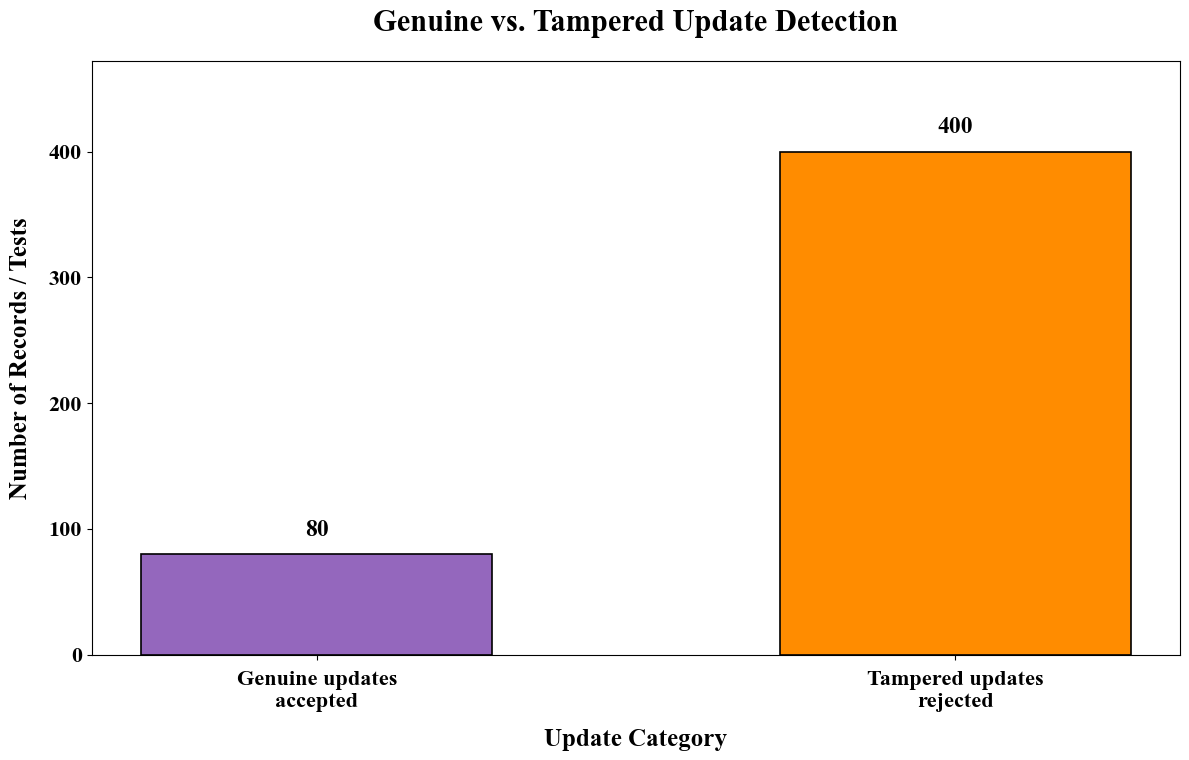

Saved plot: /kaggle/working/BCFedARFR_Results/Federated_Training/plot_7_genuine_vs_tampered_detection.png


In [114]:
# ============================================================
# GENUINE VS. TAMPERED UPDATE DETECTION
# LARGE FONTS + PURPLE & ORANGE BARS
# ============================================================

import os
import matplotlib.pyplot as plt

labels = [
    "Genuine updates\naccepted",
    "Tampered updates\nrejected"
]

counts = [genuine_accepted, tampered_rejected]

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.bar(
    labels,
    counts,
    color=["#9467BD", "#FF8C00"],
    edgecolor="black",
    linewidth=1.2,
    width=0.55
)

# Title and axis labels
ax.set_title(
    "Genuine vs. Tampered Update Detection",
    fontsize=22,
    fontweight="bold",
    pad=22
)

ax.set_xlabel("Update Category", fontsize=18, fontweight="bold", labelpad=12)
ax.set_ylabel("Number of Records / Tests", fontsize=18, fontweight="bold", labelpad=12)

# X-axis and Y-axis tick font sizes
ax.tick_params(axis="x", labelsize=16, pad=8)
ax.tick_params(axis="y", labelsize=16)

# Add sufficient headroom for annotations
max_count = max(counts) if counts else 0
ax.set_ylim(0, max_count * 1.18 if max_count > 0 else 1)

# Bar annotations — larger font, with spacing
for bar, value in zip(bars, counts):
    ax.annotate(
        f"{value:,}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=17,
        fontweight="bold",
        annotation_clip=False
    )

# Grid and layout

ax.set_axisbelow(True)

fig.tight_layout()
fig.subplots_adjust(top=0.88)

# Save high-resolution plot
plot_path = os.path.join(
    base_dir,
    "plot_7_genuine_vs_tampered_detection.png"
)

fig.savefig(plot_path, dpi=300, bbox_inches="tight", pad_inches=0.3)
plt.show()

print("Saved plot:", plot_path)

BLOCKCHAIN METRIC 8: COMPUTATIONAL OVERHEAD
Mean serialization time (ms): 0.005371
Mean hashing time (ms):       0.001759
Mean combined time (ms):      0.007130
Hashing overhead (%):         32.76


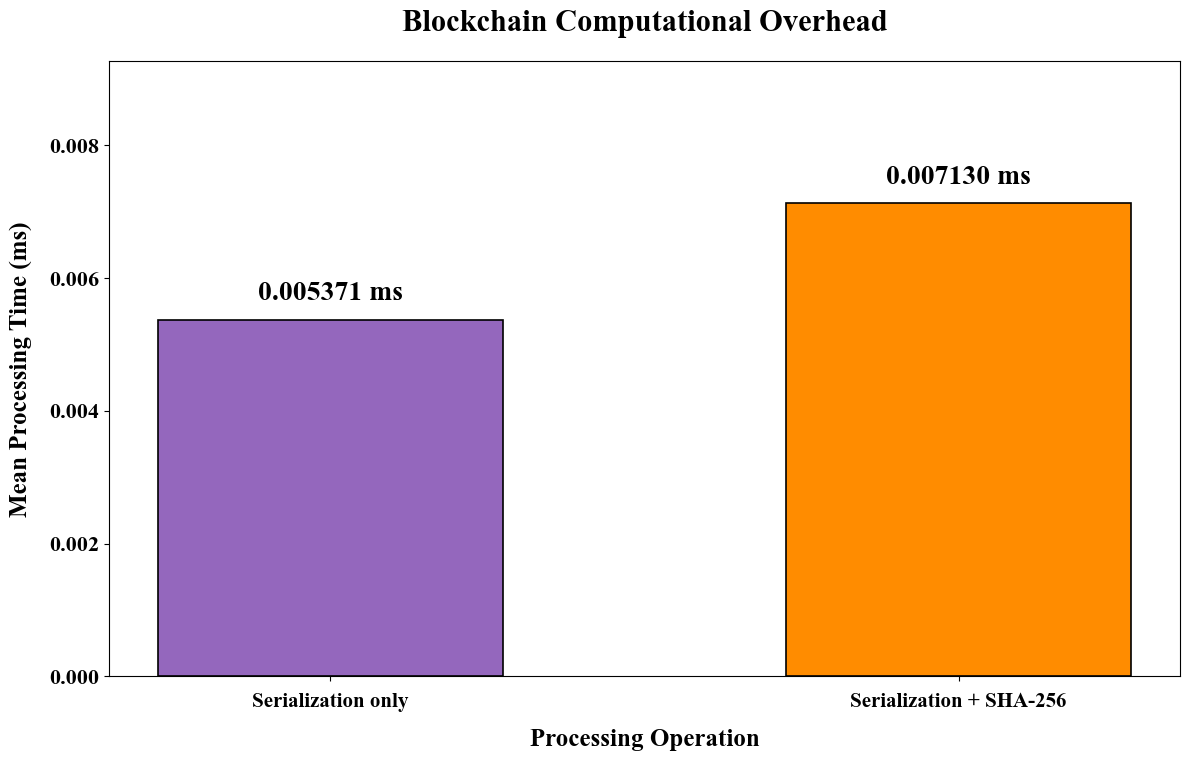


Saved plot: /kaggle/working/BCFedARFR_Results/Federated_Training/plot_8_blockchain_computational_overhead.png
Saved metrics: /kaggle/working/BCFedARFR_Results/Federated_Training/metric_8_blockchain_computational_overhead.csv

Note: This measures local serialization and hashing,
not the overhead of a deployed blockchain network.


In [116]:
# ============================================================
# PLOT 8: BLOCKCHAIN COMPUTATIONAL OVERHEAD
# LARGE FONTS + PURPLE & ORANGE BARS
# ============================================================

import os
import time
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Federated_Training"
)

ledger_path = os.path.join(
    base_dir, "update_verification_ledger.csv"
)

if not os.path.exists(ledger_path):
    raise FileNotFoundError(f"Ledger not found: {ledger_path}")

df = pd.read_csv(ledger_path)

fields = [
    "round", "client", "sample_count",
    "update_hash", "previous_ledger_hash"
]

missing = [c for c in fields if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

records = [
    {col: row[col] for col in fields}
    for _, row in df.iterrows()
]

# Warm up both operations.
for record in records[:5]:
    payload = json.dumps(
        record, sort_keys=True,
        separators=(",", ":"), default=str
    ).encode("utf-8")
    hashlib.sha256(payload).hexdigest()

# Repeat to reduce the effect of timer noise.
repeats = 100
serialization_times = []
serialization_hash_times = []

for _ in range(repeats):
    for record in records:
        start = time.perf_counter()

        payload = json.dumps(
            record, sort_keys=True,
            separators=(",", ":"), default=str
        ).encode("utf-8")

        serialization_ms = (time.perf_counter() - start) * 1000
        serialization_times.append(serialization_ms)

        start = time.perf_counter()
        hashlib.sha256(payload).hexdigest()
        hash_ms = (time.perf_counter() - start) * 1000

        serialization_hash_times.append(
            serialization_ms + hash_ms
        )

mean_serialization_ms = float(np.mean(serialization_times))
mean_total_ms = float(np.mean(serialization_hash_times))
mean_hash_ms = mean_total_ms - mean_serialization_ms

overhead_pct = (
    mean_hash_ms / mean_serialization_ms * 100
    if mean_serialization_ms > 0 else np.nan
)

print("=" * 60)
print("BLOCKCHAIN METRIC 8: COMPUTATIONAL OVERHEAD")
print("=" * 60)
print(f"Mean serialization time (ms): {mean_serialization_ms:.6f}")
print(f"Mean hashing time (ms):       {mean_hash_ms:.6f}")
print(f"Mean combined time (ms):      {mean_total_ms:.6f}")
print(f"Hashing overhead (%):         {overhead_pct:.2f}")

# Plot comparison
labels = [
    "Serialization only",
    "Serialization + SHA-256"
]
values = [mean_serialization_ms, mean_total_ms]

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.bar(
    labels,
    values,
    color=["#9467BD", "#FF8C00"],
    edgecolor="black",
    linewidth=1.2,
    width=0.55
)

ax.set_title(
    "Blockchain Computational Overhead",
    fontsize=22,
    fontweight="bold",
    pad=22
)
ax.set_xlabel(
    "Processing Operation",
    fontsize=18,
    fontweight="bold",
    labelpad=12
)
ax.set_ylabel(
    "Mean Processing Time (ms)",
    fontsize=18,
    fontweight="bold",
    labelpad=12
)

ax.tick_params(axis="x", labelsize=15, pad=8)
ax.tick_params(axis="y", labelsize=16)

max_value = max(values) if values else 0
ax.set_ylim(0, max_value * 1.30 if max_value > 0 else 1)

for bar, value in zip(bars, values):
    ax.annotate(
        f"{value:.6f} ms",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=20,
        fontweight="bold",
        annotation_clip=False
    )


ax.set_axisbelow(True)

fig.tight_layout()
fig.subplots_adjust(top=0.88)

plot_path = os.path.join(
    base_dir,
    "plot_8_blockchain_computational_overhead.png"
)
fig.savefig(plot_path, dpi=300, bbox_inches="tight", pad_inches=0.3)
plt.show()

# Save the numerical result as well.
metrics_path = os.path.join(
    base_dir,
    "metric_8_blockchain_computational_overhead.csv"
)

pd.DataFrame({
    "Metric": [
        "Mean Serialization Time (ms)",
        "Mean SHA-256 Hashing Time (ms)",
        "Mean Combined Time (ms)",
        "Hashing Overhead (%)"
    ],
    "Value": [
        mean_serialization_ms,
        mean_hash_ms,
        mean_total_ms,
        overhead_pct
    ]
}).to_csv(metrics_path, index=False)

print("\nSaved plot:", plot_path)
print("Saved metrics:", metrics_path)
print("\nNote: This measures local serialization and hashing,")
print("not the overhead of a deployed blockchain network.")

In [119]:
# ============================================================
# GRAD-CAM FIX: USE THE ORIGINAL CONNECTED MODEL GRAPH
# ============================================================

import tensorflow as tf

backbone = global_model.get_layer("efficientnetb0")

# Get the original backbone output tensor.
feature_tensor = backbone.output

# Find the exact tensor that feeds into the original classifier.
# This approach uses the original graph instead of manually
# applying layers in an assumed sequence.

try:
    grad_model = tf.keras.Model(
        inputs=global_model.inputs,
        outputs=[
            feature_tensor,
            global_model.output
        ],
        name="BCFedARFR_GradCAM_Model"
    )

    print("Grad-CAM graph created.")
    print("Feature-map shape:", feature_tensor.shape)
    print("Model output shape:", global_model.output.shape)

except Exception as e:
    print("Could not construct Grad-CAM graph:", repr(e))
    print(
        "\nStop here and send me this output. "
        "Do not rebuild the ARFR layers."
    )

Grad-CAM graph created.
Feature-map shape: (None, 7, 7, 1280)
Model output shape: (None, 1)


In [121]:
# ============================================================
# DIAGNOSE THE ORIGINAL MODEL GRAPH FOR GRAD-CAM
# ============================================================

import tensorflow as tf

print("Model type:", type(global_model).__name__)
print("Model input:", global_model.input_shape)
print("Model output:", global_model.output_shape)

backbone = global_model.get_layer("efficientnetb0")

print("\nBackbone type:", type(backbone).__name__)
print("Backbone input shape:", backbone.input_shape)
print("Backbone output shape:", backbone.output_shape)

print("\nBackbone output tensor:", backbone.output)
print("Backbone output history:", backbone.output._keras_history)

print("\nTop-level layers and output shapes:")
for layer in global_model.layers:
    try:
        print(
            layer.name,
            "input =", getattr(layer, "input_shape", "not exposed"),
            "output =", getattr(layer, "output_shape", "not exposed")
        )
    except Exception:
        print(layer.name, "shape details unavailable")

Model type: Functional
Model input: (None, 224, 224, 3)
Model output: (None, 1)

Backbone type: Functional
Backbone input shape: (None, 224, 224, 3)
Backbone output shape: (None, 7, 7, 1280)

Backbone output tensor: <KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_245>
Backbone output history: KerasHistory(operation=<Activation name=top_activation, built=True>, node_index=0, tensor_index=0)

Top-level layers and output shapes:
MRI_Input input = not exposed output = not exposed
Training_Only_Augmentation input = (None, 224, 224, 3) output = (None, 224, 224, 3)
efficientnetb0 input = (None, 224, 224, 3) output = (None, 7, 7, 1280)
ARFR_Reduce input = not exposed output = not exposed
ARFR_Reduce_BN input = not exposed output = not exposed
ARFR_Reduce_Activation input = not exposed output = not exposed
ARFR_Depthwise input = not exposed output = not exposed
ARFR_Depthwise_BN input = not exposed output = not exposed
ARFR_Depthwise_Activatio

In [122]:
# ============================================================
# GRAD-CAM — TEST NESTED BACKBONE CONNECTION
# ============================================================

import tensorflow as tf

backbone = global_model.get_layer("efficientnetb0")

# First test the original model and backbone independently.
for images, labels in test_ds.take(1):
    images = tf.cast(images, tf.float32)
    break

backbone_features = backbone(images, training=False)
model_predictions = global_model(images, training=False)

print("Backbone execution successful:", backbone_features.shape)
print("Original model execution successful:", model_predictions.shape)

# Inspect the backbone's final convolutional layer.
print("\nLast backbone layers:")
for layer in backbone.layers[-8:]:
    print(layer.name, type(layer).__name__)

# Check the ARFR layer's original inbound connections.
arfr_layer = global_model.get_layer("ARFR_Residual")
print("\nARFR layer:", arfr_layer.name)
print("ARFR input structure:", arfr_layer.input)
print("ARFR output structure:", arfr_layer.output)

Backbone execution successful: (16, 7, 7, 1280)
Original model execution successful: (16, 1)

Last backbone layers:
block7a_se_reduce Conv2D
block7a_se_expand Conv2D
block7a_se_excite Multiply
block7a_project_conv Conv2D
block7a_project_bn BatchNormalization
top_conv Conv2D
top_bn BatchNormalization
top_activation Activation

ARFR layer: ARFR_Residual
ARFR input structure: <KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_246>
ARFR output structure: <KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_254>


In [124]:
# ============================================================
# GRAD-CAM — INSPECT ORIGINAL MODEL GRAPH CONNECTIONS
# ============================================================

import tensorflow as tf

backbone = global_model.get_layer("efficientnetb0")

# Inspect the original model's actual graph tensors.
print("Backbone inbound nodes:", len(backbone._inbound_nodes))
print("Backbone outbound nodes:", len(backbone._outbound_nodes))

print("\nBackbone output tensor:", backbone.output)
print("ARFR input tensor:",
      global_model.get_layer("ARFR_Reduce").input)
print("ARFR residual input tensor:",
      global_model.get_layer("ARFR_Residual").input)
print("Final output tensor:", global_model.output)

# Check whether the original model graph records the backbone
# output as the exact input to the first ARFR layer.
try:
    arfr_input = global_model.get_layer("ARFR_Reduce").input
    print(
        "\nBackbone output and ARFR input are the same tensor:",
        backbone.output is arfr_input
    )
except Exception as e:
    print("Could not inspect ARFR input:", repr(e))

Backbone inbound nodes: 1
Backbone outbound nodes: 2

Backbone output tensor: <KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_245>
ARFR input tensor: <KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_246>
ARFR residual input tensor: <KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_246>
Final output tensor: <KerasTensor shape=(None, 1), dtype=float32, sparse=False, ragged=False, name=keras_tensor_284>

Backbone output and ARFR input are the same tensor: False


In [125]:
# ============================================================
# INSPECT BACKBONE OUTPUT CONNECTIONS
# ============================================================

backbone = global_model.get_layer("efficientnetb0")

print("Backbone output nodes:")
for i, node in enumerate(backbone._outbound_nodes):
    print(f"\nNode {i}:")
    print("Operation:", node.operation.name)

    try:
        print("Input tensors:", node.input_tensors)
        print("Output tensors:", node.output_tensors)
    except Exception as e:
        print("Tensor details unavailable:", repr(e))

print("\nARFR_Reduce inbound nodes:")
arfr_reduce = global_model.get_layer("ARFR_Reduce")

for i, node in enumerate(arfr_reduce._inbound_nodes):
    print(f"\nNode {i}:")
    try:
        print("Input tensors:", node.input_tensors)
        print("Output tensors:", node.output_tensors)
    except Exception as e:
        print("Tensor details unavailable:", repr(e))

Backbone output nodes:

Node 0:
Operation: ARFR_Reduce
Input tensors: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_246>]
Output tensors: [<KerasTensor shape=(None, 7, 7, 256), dtype=float16, sparse=False, ragged=False, name=keras_tensor_247>]

Node 1:
Operation: ARFR_Residual
Input tensors: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_246>]
Output tensors: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_254>]

ARFR_Reduce inbound nodes:

Node 0:
Input tensors: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_246>]
Output tensors: [<KerasTensor shape=(None, 7, 7, 256), dtype=float16, sparse=False, ragged=False, name=keras_tensor_247>]

Node 1:
Input tensors: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=GradCAM_Feature_Input>]
Outpu

In [126]:
# ============================================================
# GRAD-CAM — CHECK ORIGINAL ARFR FEATURE CONNECTION
# ============================================================

import tensorflow as tf

arfr_layer = global_model.get_layer("ARFR_Reduce")

# Use the ORIGINAL ARFR output tensor from the trained model graph.
arfr_features = arfr_layer.output

print("ARFR feature tensor:", arfr_features)
print("ARFR feature shape:", arfr_features.shape)

# Inspect the ARFR output's recorded downstream connections.
print("\nARFR_Reduce outbound nodes:")

for i, node in enumerate(arfr_layer._outbound_nodes):
    print(f"\nNode {i}:")
    print("Operation:", node.operation.name)

    try:
        print("Input tensors:", node.input_tensors)
        print("Output tensors:", node.output_tensors)
    except Exception as e:
        print("Tensor details unavailable:", repr(e))

# Check whether the ARFR output feeds into the classifier pathway.
for layer_name in [
    "ARFR_Reduce_BN",
    "ARFR_Reduce_Activation",
    "ARFR_Depthwise",
    "ARFR_Residual",
    "ARFR_Output",
    "Global_Average_Pooling",
    "AD_Probability"
]:
    try:
        layer = global_model.get_layer(layer_name)
        print(f"\n{layer_name}: found")
    except ValueError:
        print(f"\n{layer_name}: not found")

ARFR feature tensor: <KerasTensor shape=(None, 7, 7, 256), dtype=float16, sparse=False, ragged=False, name=keras_tensor_247>
ARFR feature shape: (None, 7, 7, 256)

ARFR_Reduce outbound nodes:

Node 0:
Operation: ARFR_Reduce_BN
Input tensors: [<KerasTensor shape=(None, 7, 7, 256), dtype=float16, sparse=False, ragged=False, name=keras_tensor_247>]
Output tensors: [<KerasTensor shape=(None, 7, 7, 256), dtype=float16, sparse=False, ragged=False, name=keras_tensor_248>]

Node 1:
Operation: ARFR_Reduce_BN
Input tensors: [<KerasTensor shape=(None, 7, 7, 256), dtype=float16, sparse=False, ragged=False, name=keras_tensor_1891>]
Output tensors: [<KerasTensor shape=(None, 7, 7, 256), dtype=float16, sparse=False, ragged=False, name=keras_tensor_1892>]

ARFR_Reduce_BN: found

ARFR_Reduce_Activation: found

ARFR_Depthwise: found

ARFR_Residual: found

ARFR_Output: found

Global_Average_Pooling: found

AD_Probability: found


In [127]:
# ============================================================
# GRAD-CAM — TEST ORIGINAL ARFR FEATURE TENSOR
# ============================================================

import tensorflow as tf
import numpy as np

# Use the ORIGINAL model's recorded ARFR output and prediction.
arfr_features = global_model.get_layer("ARFR_Reduce").output

try:
    arfr_grad_model = tf.keras.Model(
        inputs=global_model.inputs,
        outputs=[arfr_features, global_model.output],
        name="ARFR_GradCAM_Test"
    )

    print("ARFR Grad-CAM model created.")

    for images, labels in test_ds.take(1):
        with tf.GradientTape() as tape:
            features, predictions = arfr_grad_model(
                images, training=False
            )
            score = tf.reduce_sum(predictions[:, 0])

        gradients = tape.gradient(score, features)

        print("Features:", features.shape)
        print("Predictions:", predictions.shape)
        print("Gradients available:", gradients is not None)

        if gradients is not None:
            print("Gradient shape:", gradients.shape)
            print(
                "All gradients finite:",
                bool(tf.reduce_all(
                    tf.math.is_finite(gradients)
                ).numpy())
            )

        break

except Exception as e:
    print("Grad-CAM test failed:", repr(e))

ARFR Grad-CAM model created.
Features: (16, 7, 7, 256)
Predictions: (16, 1)
Gradients available: True
Gradient shape: (16, 7, 7, 256)
All gradients finite: True


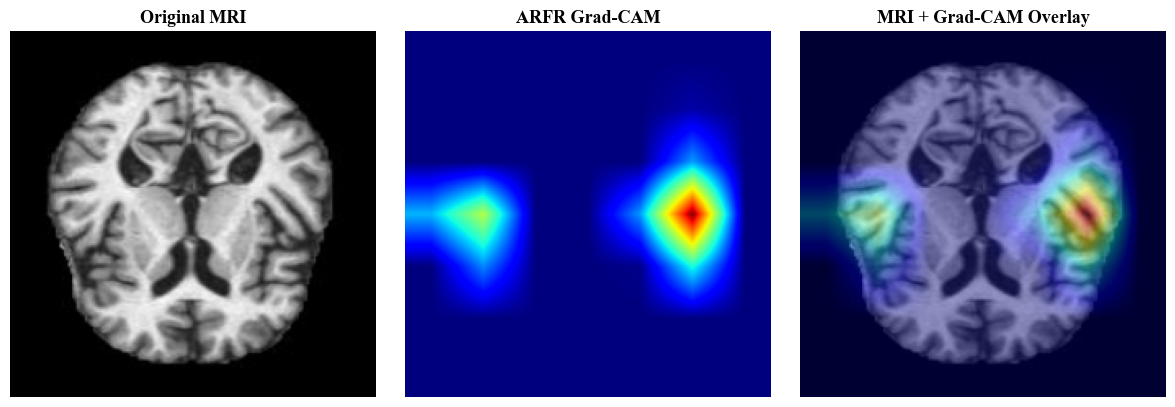

True class: AD Impaired
Predicted AD probability: 0.9533

Grad-CAM image saved to:
/kaggle/working/BCFedARFR_Results/Explainability_Results/GradCAM_One_MRI_Sample.png


/kaggle/working/BCFedARFR_Results/Explainability_Results/GradCAM_One_MRI_Sample.png

In [131]:
# ============================================================
# FAST GRAD-CAM — ONE MRI SAMPLE + DOWNLOAD
# Original MRI | Heatmap | Overlay
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

# Output folder
OUTPUT_DIR = (
    "/kaggle/working/BCFedARFR_Results/Explainability_Results"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

SAVE_PATH = os.path.join(
    OUTPUT_DIR, "GradCAM_One_MRI_Sample.png"
)

# ------------------------------------------------------------
# 1. GET ONE TEST IMAGE
# ------------------------------------------------------------
for images, labels in test_ds.take(1):
    image = images[:1]
    true_label = int(labels.numpy().reshape(-1)[0])
    break

# ------------------------------------------------------------
# 2. GENERATE GRAD-CAM
# Requires the previously tested make_arfr_gradcam() function
# and arfr_grad_model.
# ------------------------------------------------------------
heatmaps, predictions = make_arfr_gradcam(image)

# ------------------------------------------------------------
# 3. PREPARE ORIGINAL MRI
# ------------------------------------------------------------
original = image[0].numpy().astype(np.float32)

if original.max() > 1.5:
    original /= 255.0

original = np.clip(original, 0, 1)

# Resize heatmap to original image dimensions
heatmap = tf.image.resize(
    heatmaps[0][..., np.newaxis],
    (original.shape[0], original.shape[1])
).numpy().squeeze()

# ------------------------------------------------------------
# 4. PLOT ORIGINAL | HEATMAP | OVERLAY
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original)
axes[0].set_title("Original MRI", fontsize=13)

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("ARFR Grad-CAM", fontsize=13)

axes[2].imshow(original)
axes[2].imshow(
    heatmap,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[2].set_title("MRI + Grad-CAM Overlay", fontsize=13)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

# ------------------------------------------------------------
# 5. SAVE FIGURE
# ------------------------------------------------------------
fig.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. DISPLAY PREDICTION + DOWNLOAD LINK
# ------------------------------------------------------------
print("True class:", "AD Impaired" if true_label == 1 else "Normal")
print("Predicted AD probability:", round(float(predictions[0]), 4))
print("\nGrad-CAM image saved to:")
print(SAVE_PATH)

display(FileLink(SAVE_PATH))

Selected class: AD Impaired
True label: 1


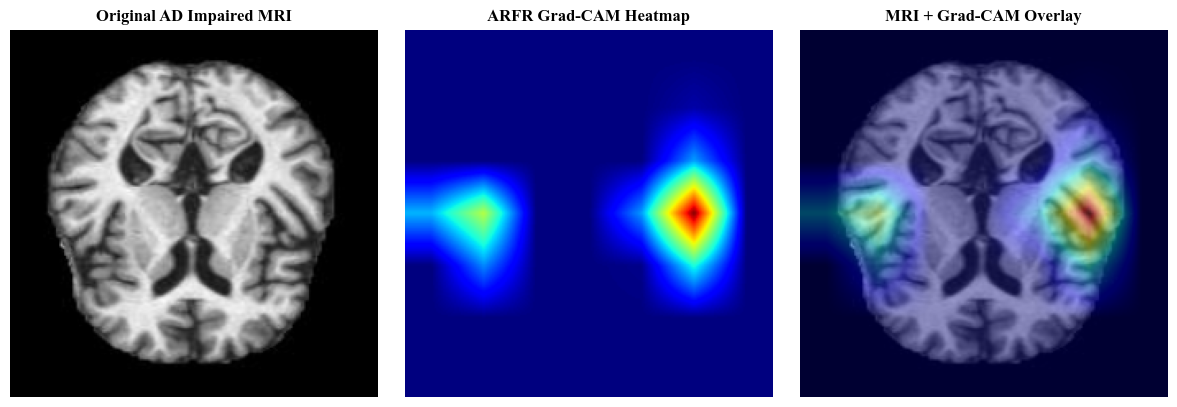


True class: AD Impaired
Predicted class: AD Impaired
Predicted AD probability: 0.9533

Saved file: /kaggle/working/BCFedARFR_Results/Explainability_Results/GradCAM_AD_Impaired_MRI.png


/kaggle/working/BCFedARFR_Results/Explainability_Results/GradCAM_AD_Impaired_MRI.png

In [132]:
# ============================================================
# ARFR GRAD-CAM — ONE AD IMPAIRED MRI SAMPLE
# Original MRI + Heatmap + Overlay + Download
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

# Output directory
OUTPUT_DIR = "/kaggle/working/BCFedARFR_Results/Explainability_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SAVE_PATH = os.path.join(
    OUTPUT_DIR,
    "GradCAM_AD_Impaired_MRI.png"
)

# ------------------------------------------------------------
# 1. FIND ONE AD IMPAIRED IMAGE (LABEL = 1)
# ------------------------------------------------------------
image = None

for images, labels in test_ds:
    label_array = labels.numpy().reshape(-1)
    impaired_indices = np.where(label_array == 1)[0]

    if len(impaired_indices) > 0:
        idx = int(impaired_indices[0])
        image = images[idx:idx+1]
        true_label = int(label_array[idx])
        break

if image is None:
    raise ValueError("No AD Impaired sample (label 1) found in test_ds.")

print("Selected class: AD Impaired")
print("True label:", true_label)

# ------------------------------------------------------------
# 2. GENERATE ARFR GRAD-CAM
# ------------------------------------------------------------
heatmaps, predictions = make_arfr_gradcam(image)

ad_probability = float(predictions[0])
predicted_label = int(ad_probability >= 0.5)

# Prepare original MRI for display
original = image[0].numpy().astype(np.float32)

if original.max() > 1.5:
    original /= 255.0

original = np.clip(original, 0, 1)

# Resize heatmap to original MRI dimensions
heatmap = tf.image.resize(
    heatmaps[0][..., np.newaxis],
    (original.shape[0], original.shape[1])
).numpy().squeeze()

# ------------------------------------------------------------
# 3. PLOT ORIGINAL + HEATMAP + OVERLAY
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original)
axes[0].set_title("Original AD Impaired MRI", fontsize=12)

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("ARFR Grad-CAM Heatmap", fontsize=12)

axes[2].imshow(original)
axes[2].imshow(
    heatmap,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[2].set_title("MRI + Grad-CAM Overlay", fontsize=12)

for ax in axes:
    ax.axis("off")

plt.tight_layout()

# ------------------------------------------------------------
# 4. SAVE AND DISPLAY DOWNLOAD LINK
# ------------------------------------------------------------
fig.savefig(SAVE_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nTrue class: AD Impaired")
print("Predicted class:",
      "AD Impaired" if predicted_label == 1 else "Normal")
print("Predicted AD probability:", round(ad_probability, 4))
print("\nSaved file:", SAVE_PATH)

display(FileLink(SAVE_PATH))

Normal sample found: True
AD Impaired sample found: True


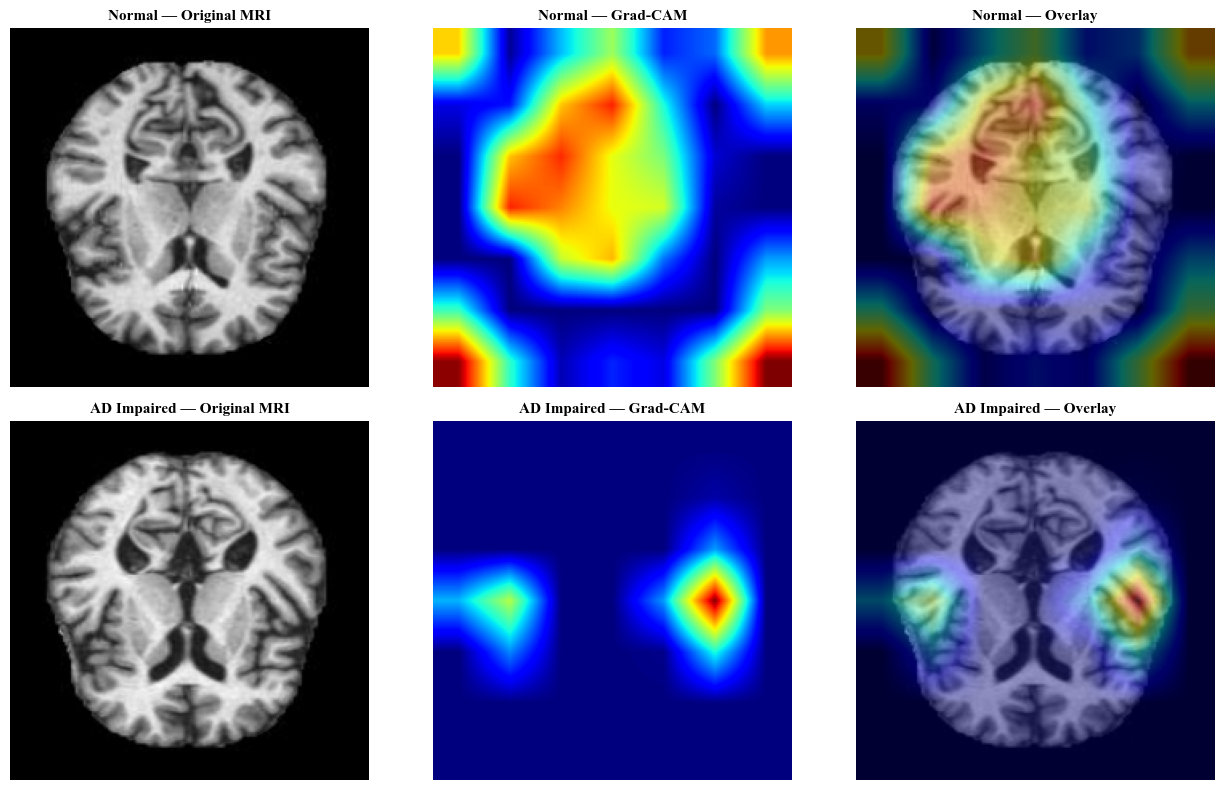


========== GRAD-CAM COMPARISON ==========

True class: Normal
Predicted class: Normal
Predicted AD probability: 0.0002

True class: AD Impaired
Predicted class: AD Impaired
Predicted AD probability: 0.9533

Saved figure: /kaggle/working/BCFedARFR_Results/Explainability_Results/Normal_vs_AD_Impaired_GradCAM.png


/kaggle/working/BCFedARFR_Results/Explainability_Results/Normal_vs_AD_Impaired_GradCAM.png

In [133]:
# ============================================================
# NORMAL vs AD IMPAIRED — GRAD-CAM COMPARISON
# Original MRI | Heatmap | Overlay for each class
# Saves a downloadable PNG
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------
OUTPUT_DIR = (
    "/kaggle/working/BCFedARFR_Results/"
    "Explainability_Results"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

SAVE_PATH = os.path.join(
    OUTPUT_DIR,
    "Normal_vs_AD_Impaired_GradCAM.png"
)

# ------------------------------------------------------------
# 2. FIND ONE SAMPLE FROM EACH CLASS
#    Label 0 = Normal
#    Label 1 = AD Impaired
# ------------------------------------------------------------
samples = {}

for images, labels in test_ds:
    label_array = labels.numpy().reshape(-1)

    for i, label in enumerate(label_array):
        label = int(label)

        if label in (0, 1) and label not in samples:
            samples[label] = images[i:i+1]

    if 0 in samples and 1 in samples:
        break

if 0 not in samples or 1 not in samples:
    raise ValueError(
        "Could not find both Normal (0) and "
        "AD Impaired (1) samples in test_ds."
    )

print("Normal sample found:", 0 in samples)
print("AD Impaired sample found:", 1 in samples)

# ------------------------------------------------------------
# 3. GENERATE GRAD-CAM FOR BOTH SAMPLES
# ------------------------------------------------------------
results = {}

for label in (0, 1):
    image_batch = samples[label]

    heatmaps, predictions = make_arfr_gradcam(image_batch)

    original = image_batch[0].numpy().astype(np.float32)

    if original.max() > 1.5:
        original = original / 255.0

    original = np.clip(original, 0, 1)

    heatmap = tf.image.resize(
        heatmaps[0][..., np.newaxis],
        (original.shape[0], original.shape[1])
    ).numpy().squeeze()

    results[label] = {
        "original": original,
        "heatmap": heatmap,
        "probability": float(predictions[0]),
        "predicted_label": int(float(predictions[0]) >= 0.5)
    }

# ------------------------------------------------------------
# 4. PLOT COMPARISON
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

class_names = {
    0: "Normal",
    1: "AD Impaired"
}

for row, label in enumerate((0, 1)):
    result = results[label]
    original = result["original"]
    heatmap = result["heatmap"]

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"{class_names[label]} — Original MRI",
        fontsize=11
    )

    axes[row, 1].imshow(
        heatmap, cmap="jet", vmin=0, vmax=1
    )
    axes[row, 1].set_title(
        f"{class_names[label]} — Grad-CAM",
        fontsize=11
    )

    axes[row, 2].imshow(original)
    axes[row, 2].imshow(
        heatmap, cmap="jet", alpha=0.4,
        vmin=0, vmax=1
    )
    axes[row, 2].set_title(
        f"{class_names[label]} — Overlay",
        fontsize=11
    )

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()

# ------------------------------------------------------------
# 5. SAVE FIGURE
# ------------------------------------------------------------
fig.savefig(
    SAVE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. DISPLAY PREDICTIONS + DOWNLOAD LINK
# ------------------------------------------------------------
print("\n========== GRAD-CAM COMPARISON ==========")

for label in (0, 1):
    result = results[label]

    predicted_name = (
        "AD Impaired"
        if result["predicted_label"] == 1
        else "Normal"
    )

    print(f"\nTrue class: {class_names[label]}")
    print("Predicted class:", predicted_name)
    print(
        "Predicted AD probability:",
        round(result["probability"], 4)
    )

print("\nSaved figure:", SAVE_PATH)
display(FileLink(SAVE_PATH))

Normal samples: 2
AD Impaired samples: 2
Normal sample 1 | AD probability: 0.0002 | Predicted: Normal
Normal sample 2 | AD probability: 0.0000 | Predicted: Normal
AD Impaired sample 1 | AD probability: 0.9533 | Predicted: AD Impaired
AD Impaired sample 2 | AD probability: 0.9998 | Predicted: AD Impaired


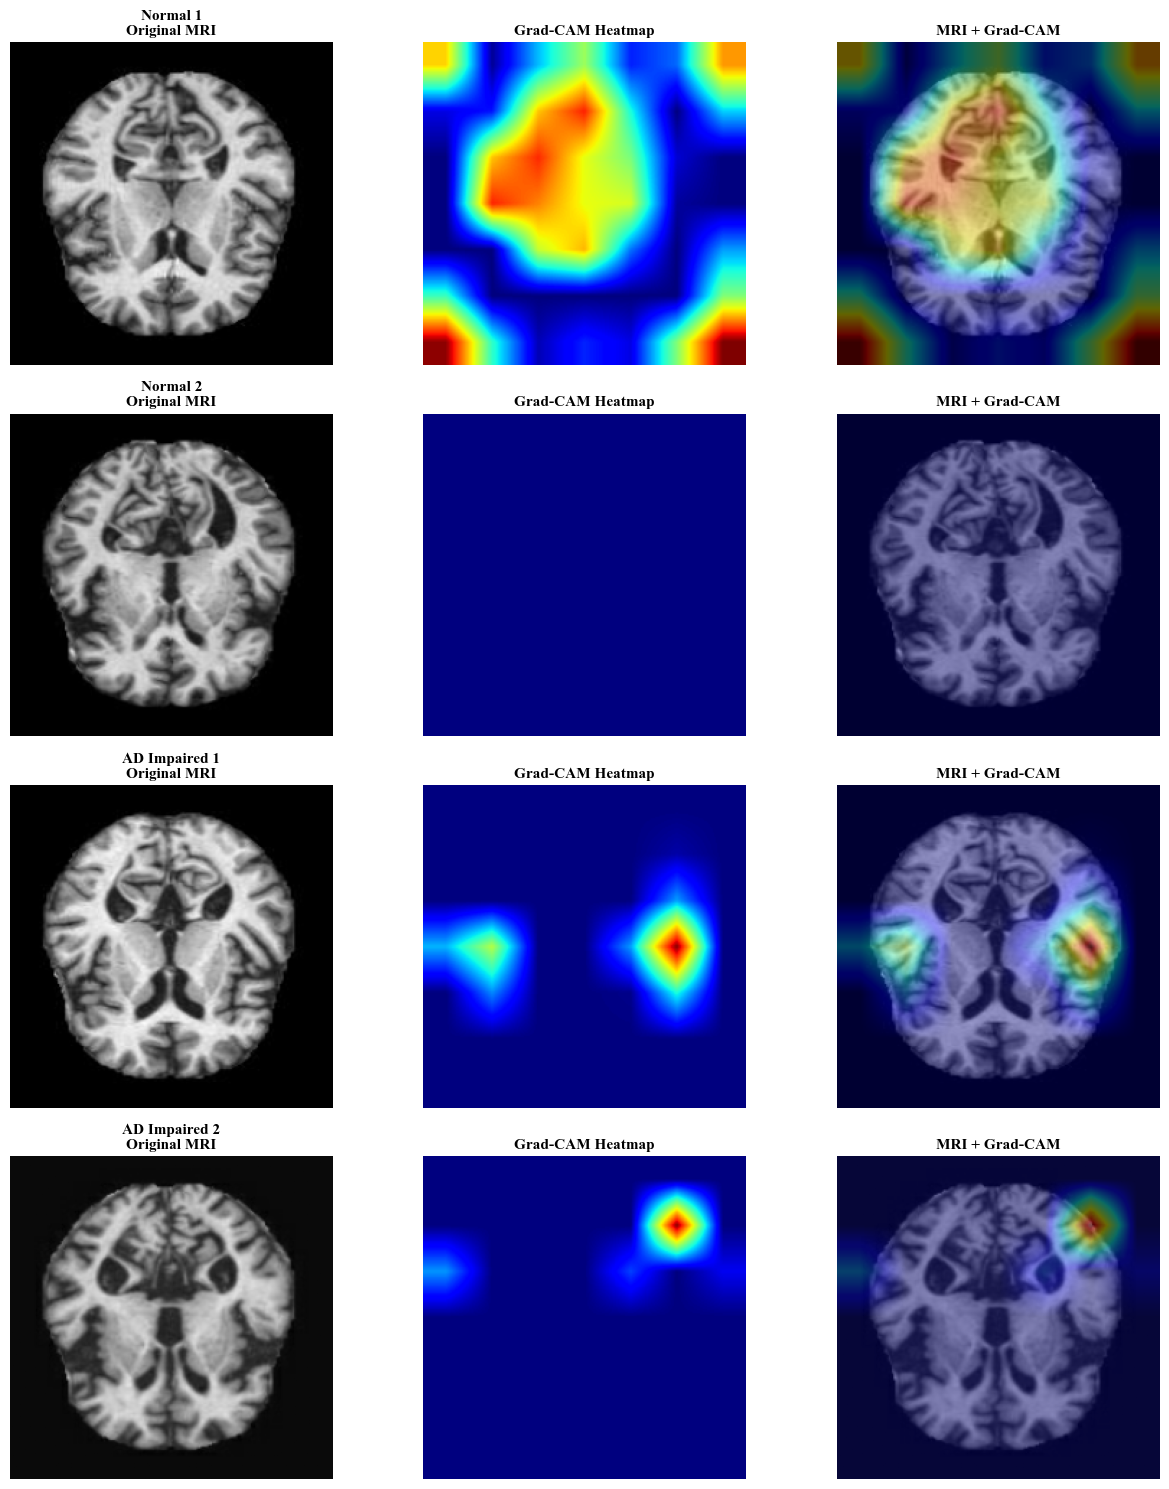


Saved visualization: /kaggle/working/BCFedARFR_Results/Explainability_Results/Multiple_Sample_GradCAM_Comparison.png


/kaggle/working/BCFedARFR_Results/Explainability_Results/Multiple_Sample_GradCAM_Comparison.png

In [134]:
# ============================================================
# MULTIPLE MRI SAMPLE GRAD-CAM VISUALIZATION
# 2 NORMAL + 2 AD IMPAIRED SAMPLES
# Original MRI | Heatmap | Overlay
# ============================================================

import os
import gc
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------
OUTPUT_DIR = (
    "/kaggle/working/BCFedARFR_Results/"
    "Explainability_Results"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

SAVE_PATH = os.path.join(
    OUTPUT_DIR,
    "Multiple_Sample_GradCAM_Comparison.png"
)

# ------------------------------------------------------------
# 2. SELECT 2 SAMPLES PER CLASS
# Label 0 = Normal
# Label 1 = AD Impaired
# ------------------------------------------------------------
samples = {0: [], 1: []}

for images, labels in test_ds:
    label_array = labels.numpy().reshape(-1)

    for i, label in enumerate(label_array):
        label = int(label)

        if label in samples and len(samples[label]) < 2:
            samples[label].append(images[i:i+1])

    if len(samples[0]) == 2 and len(samples[1]) == 2:
        break

if len(samples[0]) == 0 or len(samples[1]) == 0:
    raise ValueError("Could not find samples from both classes.")

for label in (0, 1):
    print(
        "Normal samples:" if label == 0 else "AD Impaired samples:",
        len(samples[label])
    )

# ------------------------------------------------------------
# 3. CREATE VISUALIZATION
# Each row = one MRI sample
# Columns = Original | Heatmap | Overlay
# ------------------------------------------------------------
fig, axes = plt.subplots(4, 3, figsize=(13, 15))

class_names = {0: "Normal", 1: "AD Impaired"}
sample_number = {0: 0, 1: 0}
row = 0

for label in (0, 1):
    for image_batch in samples[label]:
        heatmaps, predictions = make_arfr_gradcam(image_batch)

        original = image_batch[0].numpy().astype(np.float32)

        if original.max() > 1.5:
            original /= 255.0

        original = np.clip(original, 0, 1)

        heatmap = tf.image.resize(
            heatmaps[0][..., np.newaxis],
            (original.shape[0], original.shape[1])
        ).numpy().squeeze()

        sample_number[label] += 1
        sample_id = sample_number[label]

        axes[row, 0].imshow(original)
        axes[row, 0].set_title(
            f"{class_names[label]} {sample_id}\nOriginal MRI",
            fontsize=11
        )

        axes[row, 1].imshow(
            heatmap, cmap="jet", vmin=0, vmax=1
        )
        axes[row, 1].set_title("Grad-CAM Heatmap", fontsize=11)

        axes[row, 2].imshow(original)
        axes[row, 2].imshow(
            heatmap, cmap="jet", alpha=0.4,
            vmin=0, vmax=1
        )
        axes[row, 2].set_title("MRI + Grad-CAM", fontsize=11)

        predicted_label = int(float(predictions[0]) >= 0.5)

        print(
            f"{class_names[label]} sample {sample_id} | "
            f"AD probability: {float(predictions[0]):.4f} | "
            f"Predicted: {class_names[predicted_label]}"
        )

        for col in range(3):
            axes[row, col].axis("off")

        row += 1
        del heatmaps, predictions, heatmap, original
        gc.collect()

plt.tight_layout()

# ------------------------------------------------------------
# 4. SAVE + DOWNLOAD
# ------------------------------------------------------------
fig.savefig(SAVE_PATH, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nSaved visualization:", SAVE_PATH)
display(FileLink(SAVE_PATH))

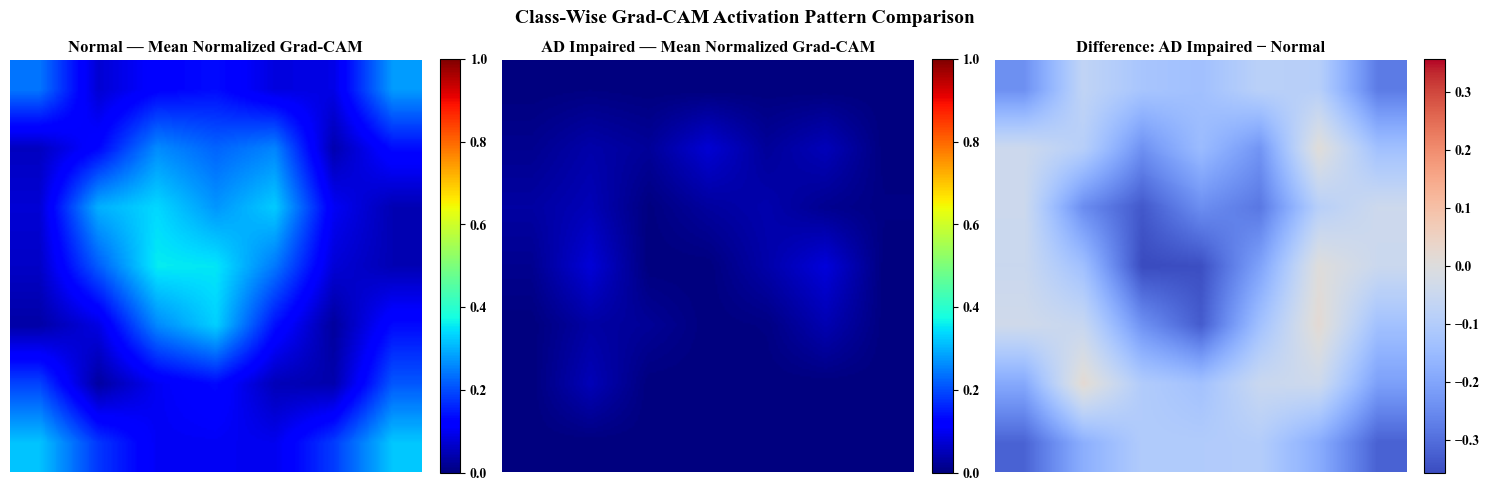

Normal samples: 20
AD Impaired samples: 20

Saved figure: /kaggle/working/BCFedARFR_Results/Explainability_Results/Corrected_Activation_Pattern_Comparison.png


/kaggle/working/BCFedARFR_Results/Explainability_Results/Corrected_Activation_Pattern_Comparison.png


Saved CSV: /kaggle/working/BCFedARFR_Results/Explainability_Results/Corrected_Activation_Pattern_Comparison.csv


/kaggle/working/BCFedARFR_Results/Explainability_Results/Corrected_Activation_Pattern_Comparison.csv

In [136]:
# ============================================================
# FIXED CLASS-WISE GRAD-CAM COMPARISON
# Per-sample normalized activation maps
# ============================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

OUTPUT_DIR = (
    "/kaggle/working/BCFedARFR_Results/"
    "Explainability_Results"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

FIGURE_PATH = os.path.join(
    OUTPUT_DIR, "Corrected_Activation_Pattern_Comparison.png"
)
CSV_PATH = os.path.join(
    OUTPUT_DIR, "Corrected_Activation_Pattern_Comparison.csv"
)

# ------------------------------------------------------------
# 1. NORMALIZE EACH MAP BEFORE CLASS-WISE AVERAGING
# ------------------------------------------------------------
def normalize_heatmap(h):
    h = np.maximum(np.asarray(h, dtype=np.float32), 0)
    maximum = float(h.max())
    if maximum > 0:
        h = h / maximum
    return h

normal_maps = [
    normalize_heatmap(h)
    for h in heatmaps_by_class[0]
]
impaired_maps = [
    normalize_heatmap(h)
    for h in heatmaps_by_class[1]
]

# Upsample for display only; this does not add spatial detail.
def upscale_map(h, size=(224, 224)):
    return tf.image.resize(
        h[..., np.newaxis],
        size,
        method="bilinear"
    ).numpy().squeeze()

normal_mean = np.mean(np.stack(normal_maps), axis=0)
impaired_mean = np.mean(np.stack(impaired_maps), axis=0)

normal_display = upscale_map(normal_mean)
impaired_display = upscale_map(impaired_mean)

# Positive = higher normalized mean activation in AD Impaired
difference_display = impaired_display - normal_display

# ------------------------------------------------------------
# 2. PLOT WITH MATCHED CLASS-MAP SCALES
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

im0 = axes[0].imshow(
    normal_display, cmap="jet", vmin=0, vmax=1
)
axes[0].set_title("Normal — Mean Normalized Grad-CAM")
axes[0].axis("off")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(
    impaired_display, cmap="jet", vmin=0, vmax=1
)
axes[1].set_title("AD Impaired — Mean Normalized Grad-CAM")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

limit = max(float(np.max(np.abs(difference_display))), 1e-6)

im2 = axes[2].imshow(
    difference_display,
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)
axes[2].set_title("Difference: AD Impaired − Normal")
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle(
    "Class-Wise Grad-CAM Activation Pattern Comparison",
    fontsize=14
)
plt.tight_layout()

fig.savefig(FIGURE_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. SAVE UPSAMPLED ACTIVATION VALUES
# ------------------------------------------------------------
df = pd.DataFrame({
    "pixel_y": np.repeat(np.arange(224), 224),
    "pixel_x": np.tile(np.arange(224), 224),
    "normal_mean_normalized_activation": normal_display.ravel(),
    "ad_impaired_mean_normalized_activation": impaired_display.ravel(),
    "ad_minus_normal_difference": difference_display.ravel()
})
df.to_csv(CSV_PATH, index=False)

print("Normal samples:", len(normal_maps))
print("AD Impaired samples:", len(impaired_maps))
print("\nSaved figure:", FIGURE_PATH)
display(FileLink(FIGURE_PATH))

print("\nSaved CSV:", CSV_PATH)
display(FileLink(CSV_PATH))

In [139]:
# CHECK WHETHER YOUR MODEL AND GRAD-CAM VARIABLES STILL EXIST

for name in [
    "global_model",
    "test_ds",
    "make_arfr_gradcam",
    "heatmaps_by_class"
]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

global_model: AVAILABLE
test_ds: AVAILABLE
make_arfr_gradcam: AVAILABLE
heatmaps_by_class: AVAILABLE


In [140]:
# ============================================================
# CHECK GRAD-CAM ACTIVATION DATA
# No training — diagnostics only
# ============================================================

import numpy as np

print("Model:", type(global_model).__name__)
print("Test dataset: AVAILABLE")
print("Grad-CAM function: AVAILABLE")
print()

for label, name in [(0, "Normal"), (1, "AD Impaired")]:
    maps = np.asarray(heatmaps_by_class[label], dtype=np.float32)

    print("=" * 45)
    print(name)
    print("=" * 45)
    print("Number of samples:", len(maps))
    print("Map shape:", maps.shape)
    print("Minimum:", round(float(np.min(maps)), 6))
    print("Maximum:", round(float(np.max(maps)), 6))
    print("Mean activation:", round(float(np.mean(maps)), 6))
    print("Standard deviation:", round(float(np.std(maps)), 6))
    print(
        "All-zero maps:",
        int(np.sum(np.max(maps, axis=(1, 2)) == 0))
    )
    print("Non-finite values:", int(np.sum(~np.isfinite(maps))))
    print()

Model: Functional
Test dataset: AVAILABLE
Grad-CAM function: AVAILABLE

Normal
Number of samples: 20
Map shape: (20, 7, 7)
Minimum: 0.0
Maximum: 1.0
Mean activation: 0.164004
Standard deviation: 0.249941
All-zero maps: 5
Non-finite values: 0

AD Impaired
Number of samples: 20
Map shape: (20, 7, 7)
Minimum: 0.0
Maximum: 1.0
Mean activation: 0.015719
Standard deviation: 0.09967
All-zero maps: 14
Non-finite values: 0



In [141]:
# ============================================================
# DIAGNOSTIC: AD-CLASS-SPECIFIC GRAD-CAM
# ============================================================

import numpy as np
import tensorflow as tf

# Use the existing ARFR Grad-CAM feature layer
arfr_features = global_model.get_layer("ARFR_Reduce").output

ad_grad_model = tf.keras.Model(
    inputs=global_model.inputs,
    outputs=[arfr_features, global_model.output],
    name="AD_Class_Specific_GradCAM"
)

# Find one AD Impaired sample (label 1)
ad_image = None

for images, labels in test_ds:
    label_values = labels.numpy().reshape(-1)
    indices = np.where(label_values == 1)[0]

    if len(indices):
        ad_image = images[int(indices[0]):int(indices[0]) + 1]
        break

if ad_image is None:
    raise ValueError("No AD Impaired sample found.")

# Calculate gradients of AD probability directly
with tf.GradientTape() as tape:
    features, predictions = ad_grad_model(ad_image, training=False)
    ad_score = tf.reduce_sum(predictions[:, 0])

gradients = tape.gradient(ad_score, features)

if gradients is None:
    raise RuntimeError("AD-specific gradients are unavailable.")

weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
raw_cam = tf.reduce_sum(weights * features, axis=-1)
raw_cam = tf.nn.relu(raw_cam)

cam_max = tf.reduce_max(raw_cam, axis=(1, 2), keepdims=True)
ad_heatmap = tf.math.divide_no_nan(raw_cam, cam_max).numpy()[0]

print("AD probability:", round(float(predictions[0, 0]), 4))
print("Raw gradient magnitude:", float(tf.reduce_mean(tf.abs(gradients))))
print("AD-specific heatmap maximum:", float(ad_heatmap.max()))
print("AD-specific heatmap mean:", float(ad_heatmap.mean()))
print("All-zero AD-specific map:", bool(ad_heatmap.max() == 0))

AD probability: 0.9533
Raw gradient magnitude: 0.00011724233627319336
AD-specific heatmap maximum: 1.0
AD-specific heatmap mean: 0.0638427734375
All-zero AD-specific map: False


Normal samples: 20
AD Impaired samples: 20
Normal zero maps: 5
AD Impaired zero maps: 14


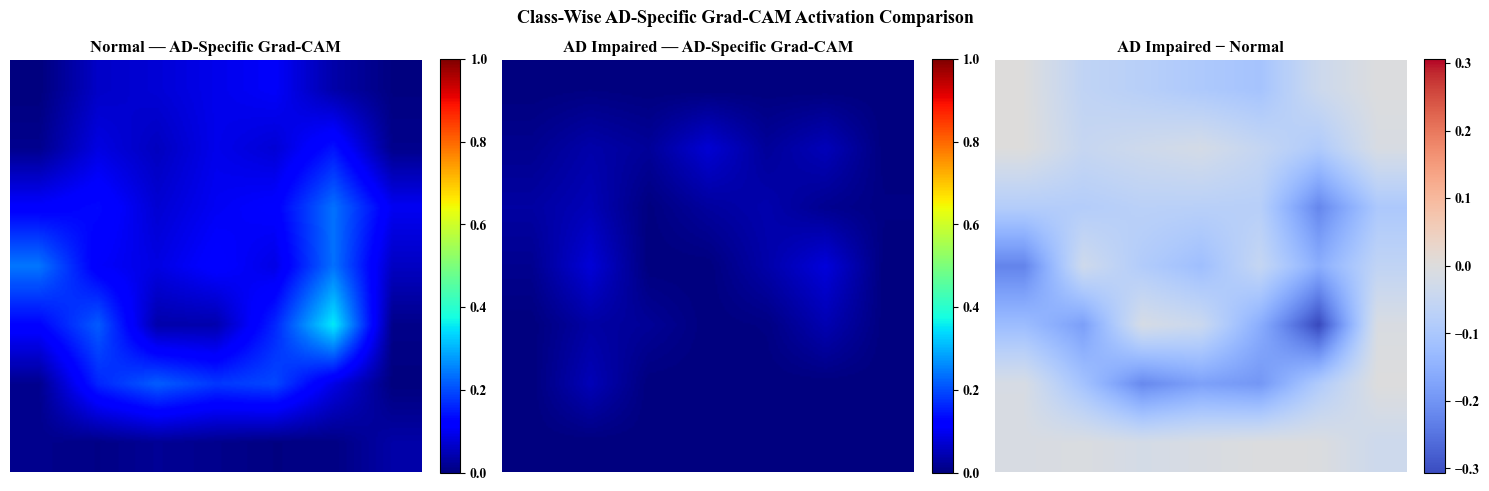


Saved figure: /kaggle/working/BCFedARFR_Results/Explainability_Results/AD_Specific_GradCAM_Comparison.png


/kaggle/working/BCFedARFR_Results/Explainability_Results/AD_Specific_GradCAM_Comparison.png


Saved CSV: /kaggle/working/BCFedARFR_Results/Explainability_Results/AD_Specific_GradCAM_Activation.csv


/kaggle/working/BCFedARFR_Results/Explainability_Results/AD_Specific_GradCAM_Activation.csv

In [142]:
# ============================================================
# CORRECTED AD-SPECIFIC GRAD-CAM COMPARISON
# Normal vs AD Impaired
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

OUTPUT_DIR = (
    "/kaggle/working/BCFedARFR_Results/"
    "Explainability_Results"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

FIGURE_PATH = os.path.join(
    OUTPUT_DIR, "AD_Specific_GradCAM_Comparison.png"
)
CSV_PATH = os.path.join(
    OUTPUT_DIR, "AD_Specific_GradCAM_Activation.csv"
)

# ------------------------------------------------------------
# 1. CREATE GRAD-CAM MODEL
# ------------------------------------------------------------
features_tensor = global_model.get_layer("ARFR_Reduce").output

ad_grad_model = tf.keras.Model(
    inputs=global_model.inputs,
    outputs=[features_tensor, global_model.output],
    name="AD_Class_Specific_GradCAM"
)

# ------------------------------------------------------------
# 2. AD-SPECIFIC GRAD-CAM FUNCTION
# ------------------------------------------------------------
def make_ad_specific_gradcam(image_batch):
    image_batch = tf.cast(image_batch, tf.float32)

    with tf.GradientTape() as tape:
        features, predictions = ad_grad_model(
            image_batch, training=False
        )
        score = tf.reduce_sum(predictions[:, 0])

    gradients = tape.gradient(score, features)

    if gradients is None:
        raise RuntimeError("AD-specific gradients are unavailable.")

    weights = tf.reduce_mean(
        gradients, axis=(1, 2), keepdims=True
    )

    raw_cam = tf.reduce_sum(weights * features, axis=-1)
    raw_cam = tf.nn.relu(raw_cam)

    maxima = tf.reduce_max(
        raw_cam, axis=(1, 2), keepdims=True
    )

    heatmaps = tf.math.divide_no_nan(raw_cam, maxima)

    return heatmaps.numpy(), predictions.numpy().reshape(-1)

# ------------------------------------------------------------
# 3. COLLECT CLASS-WISE HEATMAPS
# ------------------------------------------------------------
MAX_SAMPLES = 20
maps_by_class = {0: [], 1: []}
probabilities_by_class = {0: [], 1: []}

for images, labels in test_ds:
    label_values = labels.numpy().reshape(-1)

    for i, label in enumerate(label_values):
        label = int(label)

        if label not in (0, 1):
            continue

        if len(maps_by_class[label]) >= MAX_SAMPLES:
            continue

        image_batch = images[i:i+1]
        heatmaps, probabilities = make_ad_specific_gradcam(
            image_batch
        )

        heatmaps_by_sample = heatmaps[0].astype(np.float32)

        maps_by_class[label].append(heatmaps_by_sample)
        probabilities_by_class[label].append(
            float(probabilities[0])
        )

        del image_batch, heatmaps, probabilities

    if all(
        len(maps_by_class[c]) >= MAX_SAMPLES
        for c in (0, 1)
    ):
        break

    gc.collect()

if not maps_by_class[0] or not maps_by_class[1]:
    raise ValueError("Samples from both classes are required.")

print("Normal samples:", len(maps_by_class[0]))
print("AD Impaired samples:", len(maps_by_class[1]))

# ------------------------------------------------------------
# 4. COMPUTE CLASS-WISE MEAN MAPS
# ------------------------------------------------------------
normal_mean = np.mean(
    np.stack(maps_by_class[0]), axis=0
)
impaired_mean = np.mean(
    np.stack(maps_by_class[1]), axis=0
)

difference_map = impaired_mean - normal_mean

print("Normal zero maps:",
      sum(np.max(m) == 0 for m in maps_by_class[0]))
print("AD Impaired zero maps:",
      sum(np.max(m) == 0 for m in maps_by_class[1]))

# Upsample only for display
def resize_for_display(heatmap):
    return tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224),
        method="bilinear"
    ).numpy().squeeze()

normal_display = resize_for_display(normal_mean)
impaired_display = resize_for_display(impaired_mean)
difference_display = impaired_display - normal_display

# ------------------------------------------------------------
# 5. PLOT CLASS-WISE COMPARISON
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

im0 = axes[0].imshow(
    normal_display, cmap="jet", vmin=0, vmax=1
)
axes[0].set_title("Normal — AD-Specific Grad-CAM")
axes[0].axis("off")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(
    impaired_display, cmap="jet", vmin=0, vmax=1
)
axes[1].set_title("AD Impaired — AD-Specific Grad-CAM")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

limit = max(
    float(np.max(np.abs(difference_display))), 1e-6
)

im2 = axes[2].imshow(
    difference_display,
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)
axes[2].set_title("AD Impaired − Normal")
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle(
    "Class-Wise AD-Specific Grad-CAM Activation Comparison",
    fontsize=13
)
plt.tight_layout()

fig.savefig(FIGURE_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. SAVE ACTIVATION CSV
# ------------------------------------------------------------
height, width = normal_mean.shape

activation_df = pd.DataFrame({
    "heatmap_y": np.repeat(np.arange(height), width),
    "heatmap_x": np.tile(np.arange(width), height),
    "normal_mean_activation": normal_mean.reshape(-1),
    "ad_impaired_mean_activation": impaired_mean.reshape(-1),
    "ad_minus_normal_difference": difference_map.reshape(-1)
})

activation_df.to_csv(CSV_PATH, index=False)

print("\nSaved figure:", FIGURE_PATH)
display(FileLink(FIGURE_PATH))

print("\nSaved CSV:", CSV_PATH)
display(FileLink(CSV_PATH))

In [143]:
# ============================================================
# DIAGNOSE ZERO AD-SPECIFIC GRAD-CAM MAPS
# ============================================================

import numpy as np

for label, class_name in [(0, "Normal"), (1, "AD Impaired")]:
    maps = np.asarray(maps_by_class[label], dtype=np.float32)
    probs = np.asarray(probabilities_by_class[label])

    zero_mask = np.max(maps, axis=(1, 2)) == 0

    print(f"\n{class_name}")
    print("-" * 40)
    print("Samples:", len(maps))
    print("Zero heatmaps:", int(zero_mask.sum()))
    print("Non-zero heatmaps:", int((~zero_mask).sum()))
    print("Mean AD probability:", round(float(probs.mean()), 4))
    print("Probabilities for zero maps:", np.round(probs[zero_mask], 4))
    print("Probabilities for non-zero maps:", np.round(probs[~zero_mask], 4))


Normal
----------------------------------------
Samples: 20
Zero heatmaps: 5
Non-zero heatmaps: 15
Mean AD probability: 0.0455
Probabilities for zero maps: [0. 0. 0. 0. 0.]
Probabilities for non-zero maps: [2.000e-04 4.947e-01 6.400e-03 7.200e-03 2.000e-04 3.814e-01 0.000e+00
 2.000e-04 1.200e-03 4.000e-04 6.900e-03 0.000e+00 0.000e+00 1.000e-02
 2.000e-04]

AD Impaired
----------------------------------------
Samples: 20
Zero heatmaps: 14
Non-zero heatmaps: 6
Mean AD probability: 0.9944
Probabilities for zero maps: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Probabilities for non-zero maps: [0.9533 0.9998 0.9998 0.9999 0.9949 0.9409]


In [144]:
# ============================================================
# CHECK GRADIENT SATURATION FOR BOTH CLASSES
# ============================================================

import numpy as np
import tensorflow as tf

def inspect_ad_gradcam(label, class_name):
    image_batch = None

    for images, labels in test_ds:
        label_values = labels.numpy().reshape(-1)
        indices = np.where(label_values == label)[0]

        if len(indices):
            image_batch = images[int(indices[0]):int(indices[0]) + 1]
            break

    if image_batch is None:
        print(f"No {class_name} sample found.")
        return

    with tf.GradientTape() as tape:
        features, predictions = ad_grad_model(
            image_batch, training=False
        )
        score = tf.reduce_sum(predictions[:, 0])

    gradients = tape.gradient(score, features)

    if gradients is None:
        print(f"{class_name}: gradients are None.")
        return

    grad_array = gradients.numpy()

    print(f"\n{class_name}")
    print("-" * 35)
    print("AD probability:", float(predictions[0, 0]))
    print("Gradient mean absolute:", float(np.mean(np.abs(grad_array))))
    print("Gradient maximum absolute:", float(np.max(np.abs(grad_array))))
    print("Gradient non-zero count:", int(np.count_nonzero(grad_array)))
    print("Gradient total elements:", int(grad_array.size))

inspect_ad_gradcam(0, "Normal")
inspect_ad_gradcam(1, "AD Impaired")


Normal
-----------------------------------
AD probability: 0.00021730124717578292
Gradient mean absolute: 7.152557373046875e-07
Gradient maximum absolute: 2.664327621459961e-05
Gradient non-zero count: 8507
Gradient total elements: 12544

AD Impaired
-----------------------------------
AD probability: 0.9532942175865173
Gradient mean absolute: 0.00011724233627319336
Gradient maximum absolute: 0.005374908447265625
Gradient non-zero count: 12105
Gradient total elements: 12544


In [145]:
# ============================================================
# INSPECT FINAL CLASSIFIER LAYERS
# ============================================================

for layer in global_model.layers[-10:]:
    print(
        layer.name,
        "| type:", type(layer).__name__,
        "| output:", getattr(layer, "output", None)
    )

Coordinate_Attention_WidthSplit | type: Lambda | output: <KerasTensor shape=(None, 7, 1, 40), dtype=float16, sparse=False, ragged=False, name=keras_tensor_274>
Coordinate_Attention_HeightAttention | type: Conv2D | output: <KerasTensor shape=(None, 7, 1, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_276>
Coordinate_Attention_WidthRestore | type: Permute | output: <KerasTensor shape=(None, 1, 7, 40), dtype=float16, sparse=False, ragged=False, name=keras_tensor_275>
Coordinate_Attention_ApplyHeight | type: Multiply | output: <KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_278>
Coordinate_Attention_WidthAttention | type: Conv2D | output: <KerasTensor shape=(None, 1, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_277>
Coordinate_Attention_ApplyWidth | type: Multiply | output: <KerasTensor shape=(None, 7, 7, 1280), dtype=float16, sparse=False, ragged=False, name=keras_tensor_279>
Global_Average_

In [146]:
# ============================================================
# CHECK FINAL DENSE LAYER ACTIVATION
# ============================================================

final_layer = global_model.get_layer("AD_Probability")

print("Final layer:", final_layer.name)
print("Units:", final_layer.units)
print("Activation:", final_layer.activation.__name__)

# For a sigmoid Dense layer:
# logit = pre-sigmoid output
# probability = sigmoid(logit)

if final_layer.activation.__name__ == "sigmoid":
    print("\nConfirmed: final output uses sigmoid.")
    print("We can calculate Grad-CAM using the pre-sigmoid logit.")
else:
    print("\nActivation is not sigmoid; inspect before proceeding.")

Final layer: AD_Probability
Units: 1
Activation: sigmoid

Confirmed: final output uses sigmoid.
We can calculate Grad-CAM using the pre-sigmoid logit.


In [147]:
# ============================================================
# LOGIT-BASED GRAD-CAM — DIAGNOSTIC TEST
# Uses the existing global_model; no retraining
# ============================================================

import numpy as np
import tensorflow as tf

# ------------------------------------------------------------
# 1. BUILD A MODEL THAT OUTPUTS ARFR FEATURES + CLASSIFIER LOGIT
# ------------------------------------------------------------
arfr_layer = global_model.get_layer("ARFR_Reduce")
features_tensor = arfr_layer.output

# Input to the final Dense layer (before sigmoid activation)
final_dense = global_model.get_layer("AD_Probability")
classifier_input = final_dense.input

# Recreate only the final Dense operation without its sigmoid.
# The kernel and bias are reused from the trained layer.
logit_layer = tf.keras.layers.Dense(
    units=final_dense.units,
    activation=None,
    name="AD_Logit_Diagnostic"
)
logit_tensor = logit_layer(classifier_input)
logit_layer.set_weights(final_dense.get_weights())

logit_grad_model = tf.keras.Model(
    inputs=global_model.inputs,
    outputs=[features_tensor, logit_tensor, global_model.output],
    name="Logit_GradCAM_Diagnostic"
)

# ------------------------------------------------------------
# 2. FIND ONE SAMPLE FROM EACH CLASS
# ------------------------------------------------------------
selected = {}

for images, labels in test_ds:
    label_values = labels.numpy().reshape(-1)

    for i, label in enumerate(label_values):
        label = int(label)

        if label in (0, 1) and label not in selected:
            selected[label] = images[i:i+1]

    if 0 in selected and 1 in selected:
        break

if 0 not in selected or 1 not in selected:
    raise ValueError("Could not find both classes in test_ds.")

# ------------------------------------------------------------
# 3. CALCULATE LOGIT GRAD-CAM FOR EACH CLASS
# ------------------------------------------------------------
for label, class_name in [(0, "Normal"), (1, "AD Impaired")]:
    image_batch = tf.cast(selected[label], tf.float32)

    with tf.GradientTape() as tape:
        features, logits, probabilities = logit_grad_model(
            image_batch, training=False
        )
        score = tf.reduce_sum(logits[:, 0])

    gradients = tape.gradient(score, features)

    if gradients is None:
        print(f"{class_name}: gradients are None.")
        continue

    weights = tf.reduce_mean(
        gradients, axis=(1, 2), keepdims=True
    )

    raw_cam = tf.reduce_sum(weights * features, axis=-1)
    raw_cam = tf.nn.relu(raw_cam)

    maximum = tf.reduce_max(
        raw_cam, axis=(1, 2), keepdims=True
    )

    heatmap = tf.math.divide_no_nan(raw_cam, maximum)

    print(f"\n{class_name}")
    print("-" * 35)
    print("AD probability:", round(float(probabilities[0, 0]), 6))
    print("Pre-sigmoid logit:", round(float(logits[0, 0]), 6))
    print("Mean absolute gradient:",
          float(tf.reduce_mean(tf.abs(gradients))))
    print("Heatmap maximum:", float(tf.reduce_max(heatmap)))
    print("Heatmap mean:", float(tf.reduce_mean(heatmap)))
    print("All-zero heatmap:",
          bool(tf.reduce_max(heatmap) == 0))


Normal
-----------------------------------
AD probability: 0.000217
Pre-sigmoid logit: -8.429688
Mean absolute gradient: 0.0031986236572265625
Heatmap maximum: 1.0
Heatmap mean: 0.12017822265625
All-zero heatmap: False

AD Impaired
-----------------------------------
AD probability: 0.953294
Pre-sigmoid logit: 3.017578
Mean absolute gradient: 0.00263214111328125
Heatmap maximum: 1.0
Heatmap mean: 0.06390380859375
All-zero heatmap: False


Normal samples: 20
AD Impaired samples: 20
Normal zero maps: 0
AD Impaired zero maps: 2


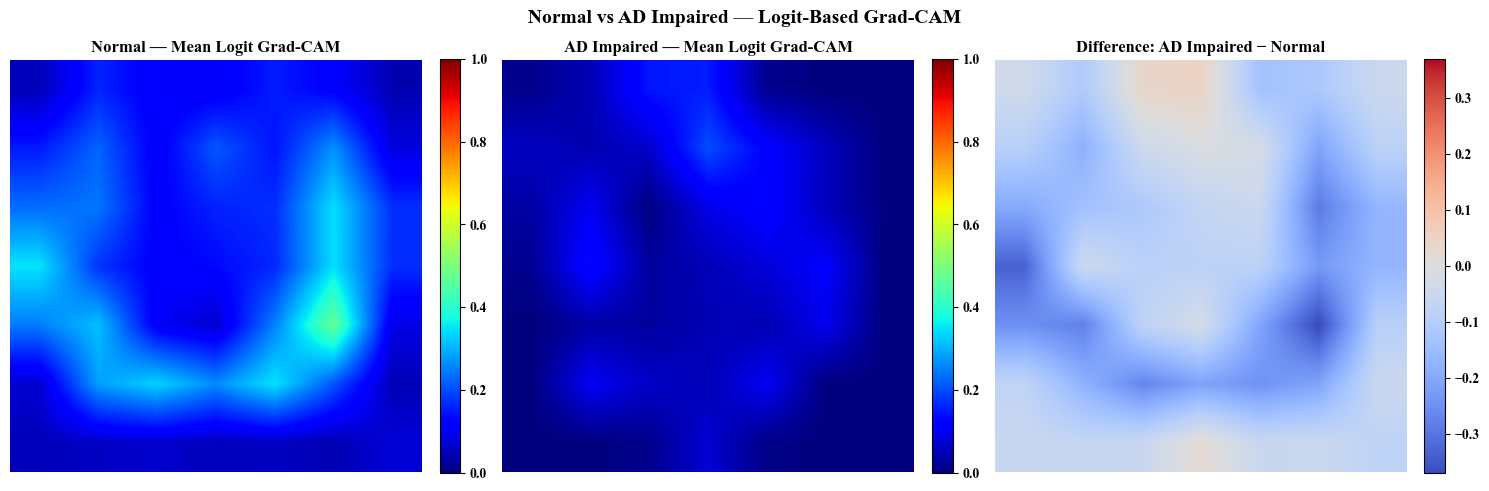


Saved figure: /kaggle/working/BCFedARFR_Results/Explainability_Results/Final_Logit_GradCAM_Comparison.png


/kaggle/working/BCFedARFR_Results/Explainability_Results/Final_Logit_GradCAM_Comparison.png


Saved activation CSV: /kaggle/working/BCFedARFR_Results/Explainability_Results/Final_Logit_GradCAM_Activation.csv


/kaggle/working/BCFedARFR_Results/Explainability_Results/Final_Logit_GradCAM_Activation.csv

In [148]:
# ============================================================
# FINAL LOGIT-BASED GRAD-CAM ACTIVATION COMPARISON
# Normal vs AD Impaired
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

OUTPUT_DIR = (
    "/kaggle/working/BCFedARFR_Results/"
    "Explainability_Results"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

FIGURE_PATH = os.path.join(
    OUTPUT_DIR, "Final_Logit_GradCAM_Comparison.png"
)
CSV_PATH = os.path.join(
    OUTPUT_DIR, "Final_Logit_GradCAM_Activation.csv"
)

# ------------------------------------------------------------
# 1. COLLECT UP TO 20 SAMPLES PER CLASS
# ------------------------------------------------------------
MAX_SAMPLES = 20
logit_maps = {0: [], 1: []}

for images, labels in test_ds:
    label_values = labels.numpy().reshape(-1)

    for i, label in enumerate(label_values):
        label = int(label)

        if label not in (0, 1):
            continue
        if len(logit_maps[label]) >= MAX_SAMPLES:
            continue

        image_batch = tf.cast(images[i:i+1], tf.float32)

        with tf.GradientTape() as tape:
            features, logits, predictions = logit_grad_model(
                image_batch, training=False
            )
            score = tf.reduce_sum(logits[:, 0])

        gradients = tape.gradient(score, features)

        if gradients is None:
            raise RuntimeError(
                "Logit gradients unavailable for a sample."
            )

        weights = tf.reduce_mean(
            gradients, axis=(1, 2), keepdims=True
        )
        raw_cam = tf.reduce_sum(weights * features, axis=-1)
        raw_cam = tf.nn.relu(raw_cam)

        max_value = tf.reduce_max(
            raw_cam, axis=(1, 2), keepdims=True
        )
        heatmap = tf.math.divide_no_nan(
            raw_cam, max_value
        ).numpy()[0]

        logit_maps[label].append(heatmap.astype(np.float32))

        del image_batch, features, logits, predictions
        del gradients, weights, raw_cam, heatmap

    if all(len(logit_maps[c]) >= MAX_SAMPLES for c in (0, 1)):
        break

    gc.collect()

if not logit_maps[0] or not logit_maps[1]:
    raise ValueError("Samples from both classes are required.")

# ------------------------------------------------------------
# 2. COMPUTE CLASS-WISE MEAN MAPS
# ------------------------------------------------------------
normal_mean = np.mean(np.stack(logit_maps[0]), axis=0)
impaired_mean = np.mean(np.stack(logit_maps[1]), axis=0)
difference_map = impaired_mean - normal_mean

print("Normal samples:", len(logit_maps[0]))
print("AD Impaired samples:", len(logit_maps[1]))
print("Normal zero maps:",
      sum(np.max(m) == 0 for m in logit_maps[0]))
print("AD Impaired zero maps:",
      sum(np.max(m) == 0 for m in logit_maps[1]))

# Upsample only for display
def resize_map(h):
    return tf.image.resize(
        h[..., np.newaxis], (224, 224),
        method="bilinear"
    ).numpy().squeeze()

normal_display = resize_map(normal_mean)
impaired_display = resize_map(impaired_mean)
difference_display = impaired_display - normal_display

# ------------------------------------------------------------
# 3. PLOT THE COMPARISON
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

im0 = axes[0].imshow(
    normal_display, cmap="jet", vmin=0, vmax=1
)
axes[0].set_title("Normal — Mean Logit Grad-CAM")
axes[0].axis("off")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(
    impaired_display, cmap="jet", vmin=0, vmax=1
)
axes[1].set_title("AD Impaired — Mean Logit Grad-CAM")
axes[1].axis("off")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

limit = max(float(np.max(np.abs(difference_display))), 1e-6)

im2 = axes[2].imshow(
    difference_display,
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)
axes[2].set_title("Difference: AD Impaired − Normal")
axes[2].axis("off")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle(
    "Normal vs AD Impaired — Logit-Based Grad-CAM",
    fontsize=14
)
plt.tight_layout()

fig.savefig(FIGURE_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. SAVE THE ORIGINAL 7 x 7 ACTIVATION VALUES
# ------------------------------------------------------------
height, width = normal_mean.shape

df = pd.DataFrame({
    "heatmap_y": np.repeat(np.arange(height), width),
    "heatmap_x": np.tile(np.arange(width), height),
    "normal_mean_activation": normal_mean.ravel(),
    "ad_impaired_mean_activation": impaired_mean.ravel(),
    "ad_minus_normal_difference": difference_map.ravel()
})
df.to_csv(CSV_PATH, index=False)

print("\nSaved figure:", FIGURE_PATH)
display(FileLink(FIGURE_PATH))

print("\nSaved activation CSV:", CSV_PATH)
display(FileLink(CSV_PATH))

In [149]:
# ============================================================
# BRAIN-REGION ACTIVATION COMPARISON
# NORMAL vs AD IMPAIRED
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display, FileLink

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Explainability_Results"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------
required = ["heatmaps_by_class", "images_by_class"]

for name in required:
    if name not in globals():
        raise NameError(
            f"{name} is missing. Run the previous "
            "Logit-based Grad-CAM cell first."
        )

for class_id in (0, 1):
    if class_id not in heatmaps_by_class:
        raise ValueError(
            f"Grad-CAM heatmaps missing for class {class_id}."
        )

# ------------------------------------------------------------
# CLASS-WISE AVERAGE ACTIVATION MAPS
# ------------------------------------------------------------
normal_maps = np.asarray(heatmaps_by_class[0])
ad_maps = np.asarray(heatmaps_by_class[1])

normal_mean = np.mean(normal_maps, axis=0)
ad_mean = np.mean(ad_maps, axis=0)

# Spatial activation difference: positive = higher AD activation
activation_difference = ad_mean - normal_mean

# ------------------------------------------------------------
# RESIZE MAPS FOR DISPLAY ONLY
# ------------------------------------------------------------
target_h, target_w = 224, 224

normal_display = cv2.resize(
    normal_mean, (target_w, target_h),
    interpolation=cv2.INTER_CUBIC
)

ad_display = cv2.resize(
    ad_mean, (target_w, target_h),
    interpolation=cv2.INTER_CUBIC
)

difference_display = cv2.resize(
    activation_difference, (target_w, target_h),
    interpolation=cv2.INTER_CUBIC
)

# ------------------------------------------------------------
# PLOT ACTIVATION COMPARISON
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

im0 = axes[0].imshow(
    normal_display, cmap="jet", vmin=0, vmax=1
)
axes[0].set_title("Normal — Mean Activation")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(
    ad_display, cmap="jet", vmin=0, vmax=1
)
axes[1].set_title("AD Impaired — Mean Activation")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

limit = max(
    float(np.max(np.abs(difference_display))),
    1e-6
)

im2 = axes[2].imshow(
    difference_display,
    cmap="seismic",
    vmin=-limit,
    vmax=limit
)
axes[2].set_title("Activation Difference (AD − Normal)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle(
    "BCFedARFR-ApeNet: Brain-Image Activation Comparison",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()

figure_path = os.path.join(
    output_dir,
    "Brain_Region_Activation_Comparison.png"
)

plt.savefig(
    figure_path, dpi=300, bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# SAVE SPATIAL ACTIVATION VALUES TO CSV
# ------------------------------------------------------------
rows = []

for y in range(normal_mean.shape[0]):
    for x in range(normal_mean.shape[1]):
        rows.append({
            "feature_map_y": y,
            "feature_map_x": x,
            "normal_mean_activation": float(normal_mean[y, x]),
            "ad_impaired_mean_activation": float(ad_mean[y, x]),
            "ad_minus_normal_activation": float(
                activation_difference[y, x]
            )
        })

csv_path = os.path.join(
    output_dir,
    "Brain_Region_Activation_Comparison.csv"
)

pd.DataFrame(rows).to_csv(csv_path, index=False)

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------
summary = pd.DataFrame([
    {
        "Class": "Normal",
        "Number_of_samples": len(normal_maps),
        "Mean_activation": float(normal_mean.mean()),
        "Maximum_activation": float(normal_mean.max())
    },
    {
        "Class": "AD Impaired",
        "Number_of_samples": len(ad_maps),
        "Mean_activation": float(ad_mean.mean()),
        "Maximum_activation": float(ad_mean.max())
    }
])

print("ACTIVATION SUMMARY")
display(summary)

print("\nSaved outputs:")
print(figure_path)
print(csv_path)

display(FileLink(figure_path))
display(FileLink(csv_path))

gc.collect()

NameError: images_by_class is missing. Run the previous Logit-based Grad-CAM cell first.

Normal samples collected: 20
AD Impaired samples collected: 20


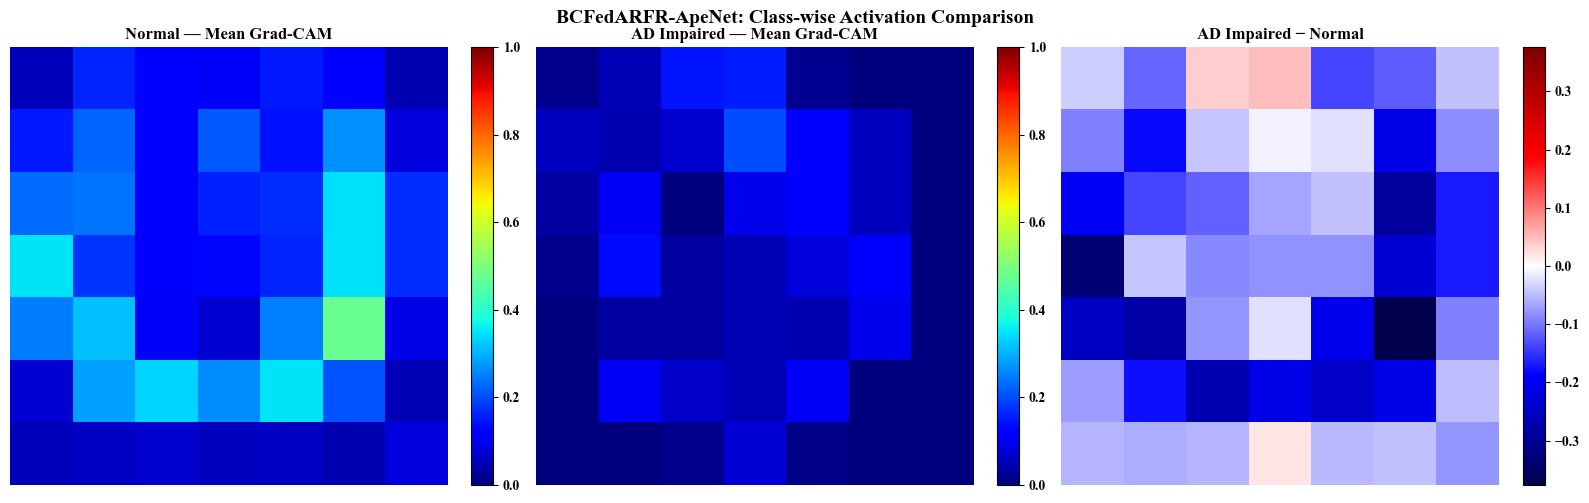


Saved outputs:
/kaggle/working/BCFedARFR_Results/Explainability_Results/Brain_Region_Activation_Comparison.png
/kaggle/working/BCFedARFR_Results/Explainability_Results/Brain_Region_Activation_Summary.csv
/kaggle/working/BCFedARFR_Results/Explainability_Results/Brain_Region_Spatial_Activation.csv


/kaggle/working/BCFedARFR_Results/Explainability_Results/Brain_Region_Activation_Comparison.png

/kaggle/working/BCFedARFR_Results/Explainability_Results/Brain_Region_Activation_Summary.csv

/kaggle/working/BCFedARFR_Results/Explainability_Results/Brain_Region_Spatial_Activation.csv

27901

In [150]:
# ============================================================
# BRAIN-REGION ACTIVATION COMPARISON
# SELF-CONTAINED SAMPLE COLLECTION + LOGIT GRAD-CAM
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. CHECK REQUIRED MODEL AND DATASET
# ------------------------------------------------------------
if "logit_grad_model" not in globals():
    raise NameError(
        "logit_grad_model is missing. Run the successful "
        "Logit Grad-CAM diagnostic cell first."
    )

if "test_ds" not in globals():
    raise NameError(
        "test_ds is missing. Recreate your test dataset first."
    )

# ------------------------------------------------------------
# 2. OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/kaggle/working/BCFedARFR_Results/"
    "Explainability_Results"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 3. COLLECT TEST IMAGES BY CLASS
# 0 = NORMAL, 1 = AD IMPAIRED
# ------------------------------------------------------------
MAX_PER_CLASS = 20
images_by_class = {0: [], 1: []}

for batch_images, batch_labels in test_ds:
    image_array = batch_images.numpy()
    label_array = batch_labels.numpy().reshape(-1).astype(int)

    for img, label in zip(image_array, label_array):
        if label in images_by_class:
            if len(images_by_class[label]) < MAX_PER_CLASS:
                images_by_class[label].append(img)

    if all(len(images_by_class[c]) >= MAX_PER_CLASS for c in [0, 1]):
        break

for c, name in [(0, "Normal"), (1, "AD Impaired")]:
    print(f"{name} samples collected: {len(images_by_class[c])}")

if not images_by_class[0] or not images_by_class[1]:
    raise ValueError(
        "Could not collect samples from both classes. "
        "Check test_ds labels and binary label mapping."
    )

# ------------------------------------------------------------
# 4. COMPUTE LOGIT-BASED GRAD-CAM
# ------------------------------------------------------------
def generate_logit_gradcam(image_batch):
    image_batch = tf.cast(image_batch, tf.float32)

    with tf.GradientTape() as tape:
        features, logits, predictions = logit_grad_model(
            image_batch, training=False
        )
        # Positive logit corresponds to AD Impaired (class 1)
        score = tf.reduce_sum(logits[:, 0])

    gradients = tape.gradient(score, features)

    if gradients is None:
        raise RuntimeError("Grad-CAM gradients are unavailable.")

    weights = tf.reduce_mean(
        gradients, axis=(1, 2), keepdims=True
    )
    heatmaps = tf.reduce_sum(weights * features, axis=-1)
    heatmaps = tf.nn.relu(heatmaps)

    maximum = tf.reduce_max(
        heatmaps, axis=(1, 2), keepdims=True
    )
    heatmaps = tf.math.divide_no_nan(heatmaps, maximum)

    return heatmaps.numpy(), predictions.numpy().reshape(-1)

# ------------------------------------------------------------
# 5. GENERATE AVERAGE MAPS
# ------------------------------------------------------------
heatmaps_by_class = {}
records = []

for class_id in [0, 1]:
    class_images = np.asarray(images_by_class[class_id])
    all_maps = []
    all_probabilities = []

    for start in range(0, len(class_images), 8):
        batch = class_images[start:start + 8]

        maps, probabilities = generate_logit_gradcam(batch)
        all_maps.extend(maps)
        all_probabilities.extend(probabilities)

    heatmaps_by_class[class_id] = np.asarray(all_maps)

    for idx, (prob, heatmap) in enumerate(
        zip(all_probabilities, all_maps), start=1
    ):
        records.append({
            "true_class": "Normal" if class_id == 0 else "AD Impaired",
            "sample_index": idx,
            "predicted_AD_probability": float(prob),
            "mean_activation": float(heatmap.mean()),
            "max_activation": float(heatmap.max()),
            "nonzero_activation_cells": int(np.count_nonzero(heatmap))
        })

normal_mean = heatmaps_by_class[0].mean(axis=0)
ad_mean = heatmaps_by_class[1].mean(axis=0)
difference = ad_mean - normal_mean

# ------------------------------------------------------------
# 6. PLOT COMPARISON
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].imshow(normal_mean, cmap="jet", vmin=0, vmax=1)
axes[0].set_title("Normal — Mean Grad-CAM")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(ad_mean, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("AD Impaired — Mean Grad-CAM")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

lim = max(float(np.max(np.abs(difference))), 1e-6)
im2 = axes[2].imshow(
    difference, cmap="seismic", vmin=-lim, vmax=lim
)
axes[2].set_title("AD Impaired − Normal")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.suptitle(
    "BCFedARFR-ApeNet: Class-wise Activation Comparison",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()

figure_path = os.path.join(
    output_dir, "Brain_Region_Activation_Comparison.png"
)
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 7. SAVE CSV RESULTS
# ------------------------------------------------------------
summary_path = os.path.join(
    output_dir, "Brain_Region_Activation_Summary.csv"
)
pd.DataFrame(records).to_csv(summary_path, index=False)

spatial_rows = []
for y in range(normal_mean.shape[0]):
    for x in range(normal_mean.shape[1]):
        spatial_rows.append({
            "feature_map_y": y,
            "feature_map_x": x,
            "normal_mean_activation": float(normal_mean[y, x]),
            "ad_impaired_mean_activation": float(ad_mean[y, x]),
            "ad_minus_normal_activation": float(difference[y, x])
        })

spatial_path = os.path.join(
    output_dir, "Brain_Region_Spatial_Activation.csv"
)
pd.DataFrame(spatial_rows).to_csv(spatial_path, index=False)

print("\nSaved outputs:")
print(figure_path)
print(summary_path)
print(spatial_path)

display(FileLink(figure_path))
display(FileLink(summary_path))
display(FileLink(spatial_path))

gc.collect()

In [152]:
# ============================================================
# ABLATION STUDY — CHECK AVAILABLE MODELS AND DATASETS
# ============================================================

import tensorflow as tf

print("=" * 65)
print("AVAILABLE ABLATION STUDY OBJECTS")
print("=" * 65)

for name in [
    "global_model",
    "test_ds",
    "val_ds",
    "global_val_ds",
    "train_ds",
    "train_df",
    "client_train_ds"
]:
    obj = globals().get(name)
    print(f"{name:20s}: {'AVAILABLE' if obj is not None else 'NOT AVAILABLE'}")

if globals().get("global_model") is not None:
    print("\nExisting global_model layers:")
    for layer in global_model.layers:
        print(f"{layer.name:35s} {layer.__class__.__name__}")

print("\n" + "=" * 65)

AVAILABLE ABLATION STUDY OBJECTS
global_model        : AVAILABLE
test_ds             : AVAILABLE
val_ds              : AVAILABLE
global_val_ds       : NOT AVAILABLE
train_ds            : AVAILABLE
train_df            : AVAILABLE
client_train_ds     : AVAILABLE

Existing global_model layers:
MRI_Input                           InputLayer
Training_Only_Augmentation          Sequential
efficientnetb0                      Functional
ARFR_Reduce                         Conv2D
ARFR_Reduce_BN                      BatchNormalization
ARFR_Reduce_Activation              Activation
ARFR_Depthwise                      SeparableConv2D
ARFR_Depthwise_BN                   BatchNormalization
ARFR_Depthwise_Activation           Activation
ARFR_Residual                       Conv2D
ARFR_Expand                         Conv2D
ARFR_Residual_BN                    BatchNormalization
ARFR_Residual_Add                   Add
ARFR_Output                         Activation
Coordinate_Attention_WidthPool      Lamb

In [153]:
# ============================================================
# ABLATION STUDY — BUILD FOUR MODEL VARIANTS
# EfficientNetB0 | + ARFR | + ARFR + CA | + ARFR + CA + Ape
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model
import pandas as pd
import numpy as np
import os

ABLATION_DIR = (
    "/kaggle/working/BCFedARFR_Results/Ablation_Study"
)
os.makedirs(ABLATION_DIR, exist_ok=True)

IMG_SHAPE = (224, 224, 3)

# Reuse the existing EfficientNetB0 backbone configuration.
existing_backbone = global_model.get_layer("efficientnetb0")

def build_ablation_model(use_arfr=False, use_ca=False):
    inputs = layers.Input(shape=IMG_SHAPE, name="MRI_Input")

    # Training augmentation remains active only during training.
    x = global_model.get_layer(
        "Training_Only_Augmentation"
    )(inputs)

    # Shared pretrained backbone, frozen for efficient comparison.
    x = existing_backbone(x, training=False)

    if use_arfr:
        # Lightweight residual feature refinement.
        residual = layers.Conv2D(
            1280, 1, padding="same",
            name="Ablation_ARFR_Projection"
        )(x)

        refined = layers.SeparableConv2D(
            1280, 3, padding="same",
            activation="swish",
            name="Ablation_ARFR_Depthwise"
        )(x)

        refined = layers.BatchNormalization()(refined)
        x = layers.Add()([residual, refined])
        x = layers.Activation("swish")(x)

    if use_ca:
        # Lightweight coordinate-aware feature gating.
        h_gate = layers.GlobalAveragePooling2D(
            name="CA_GlobalPool"
        )(x)
        h_gate = layers.Dense(
            1280, activation="sigmoid",
            name="CA_ChannelGate"
        )(h_gate)
        h_gate = layers.Reshape((1, 1, 1280))(h_gate)
        x = layers.Multiply()([x, h_gate])

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
    )
    return model


ablation_models = {
    "EfficientNetB0": build_ablation_model(False, False),
    "EfficientNetB0 + ARFR": build_ablation_model(True, False),
    "EfficientNetB0 + ARFR + CA": build_ablation_model(True, True),
}

print("Built the following model variants:")
for name, model in ablation_models.items():
    print(f"{name}: {model.count_params():,} parameters")

print("\nNote: These are newly initialized classification heads.")
print("They must be trained before their scores are compared.")

Built the following model variants:
EfficientNetB0: 4,213,668 parameters
EfficientNetB0 + ARFR: 7,509,668 parameters
EfficientNetB0 + ARFR + CA: 9,149,348 parameters

Note: These are newly initialized classification heads.
They must be trained before their scores are compared.


In [154]:
# ============================================================
# ABLATION STUDY — QUICK TRAINING RUN
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd
import os
import gc
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

ABLATION_DIR = "/kaggle/working/BCFedARFR_Results/Ablation_Study"
os.makedirs(ABLATION_DIR, exist_ok=True)

EPOCHS = 5  # Initial test; increase later for final comparison

# Freeze only the shared EfficientNetB0 backbone.
# Newly added ARFR/CA layers and classifier heads remain trainable.
for model_name, model in ablation_models.items():
    for layer in model.layers:
        if layer.name == "efficientnetb0":
            layer.trainable = False

results = []

def evaluate_ablation(model, dataset, split_name):
    y_true, y_prob = [], []

    for batch_x, batch_y in dataset:
        probabilities = model.predict(batch_x, verbose=0).reshape(-1)
        y_prob.extend(probabilities.tolist())
        y_true.extend(batch_y.numpy().reshape(-1).astype(int).tolist())

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)

    return {
        f"{split_name}_accuracy": accuracy_score(y_true, y_pred),
        f"{split_name}_precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        f"{split_name}_recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        f"{split_name}_f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        f"{split_name}_auc": (
            roc_auc_score(y_true, y_prob)
            if len(np.unique(y_true)) == 2 else np.nan
        )
    }

for model_name, model in ablation_models.items():
    print("\n" + "=" * 65)
    print(f"Training: {model_name}")
    print("=" * 65)

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )

    row = {
        "Model": model_name,
        "Parameters": model.count_params(),
        "Optimizer": "Adam",
        "Epochs_Trained": len(history.history["loss"]),
        "Status": "Trained"
    }

    row.update(evaluate_ablation(model, val_ds, "Validation"))
    row.update(evaluate_ablation(model, test_ds, "Test"))
    results.append(row)

    model.save(
        os.path.join(
            ABLATION_DIR,
            model_name.replace(" ", "_").replace("+", "plus") + ".keras"
        )
    )

    print("Validation accuracy:", row["Validation_accuracy"])
    print("Test accuracy:", row["Test_accuracy"])

    gc.collect()

ablation_results_df = pd.DataFrame(results)
csv_path = os.path.join(ABLATION_DIR, "Ablation_Study_Results.csv")
ablation_results_df.to_csv(csv_path, index=False)

print("\nAblation results saved to:", csv_path)
display(ablation_results_df)


Training: EfficientNetB0
Epoch 1/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 62s 74ms/step - accuracy: 0.7698 - auc: 0.7180 - loss: 0.5029 - val_accuracy: 0.8054 - val_auc: 0.8299 - val_loss: 0.4311
Epoch 2/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 32s 45ms/step - accuracy: 0.7921 - auc: 0.7939 - loss: 0.4525 - val_accuracy: 0.8350 - val_auc: 0.8553 - val_loss: 0.4132
Epoch 3/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 32s 45ms/step - accuracy: 0.8087 - auc: 0.8193 - loss: 0.4298 - val_accuracy: 0.8196 - val_auc: 0.8666 - val_loss: 0.4189
Epoch 4/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 32s 46ms/step - accuracy: 0.8129 - auc: 0.8322 - loss: 0.4173 - val_accuracy: 0.8346 - val_auc: 0.8749 - val_loss: 0.3916
Epoch 5/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 33s 46ms/step - accuracy: 0.8169 - auc: 0.8413 - loss: 0.4065 - val_accuracy: 0.8292 - val_auc: 0.8788 - val_loss: 0.3926
Validation accuracy: 0.8291666666666667
Test accuracy: 0.8204166666666667

Training: EfficientNetB0 + ARFR
Epoch 1/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 55s 56ms/step - accurac

,Model,Parameters,Optimizer,Epochs_Trained,Status,Validation_accuracy,Validation_precision,Validation_recall,Validation_f1,Validation_auc,Test_accuracy,Test_precision,Test_recall,Test_f1,Test_auc
0,EfficientNetB0,4213668,Adam,5,Trained,0.829167,0.904070,0.863889,0.883523,0.878824,0.820417,0.898197,0.857778,0.877522,0.866331
1,EfficientNetB0 + ARFR,7509668,Adam,5,Trained,0.846250,0.926147,0.863889,0.893935,0.919659,0.832500,0.921084,0.849444,0.883815,0.904244
2,EfficientNetB0 + ARFR + CA,9149348,Adam,5,Trained,0.808333,0.941370,0.793889,0.861362,0.914537,0.793333,0.929513,0.783889,0.850512,0.899029


In [155]:
# ============================================================
# ABLATION STUDY — ADD PROPOSED BCFedARFR-ApeNet
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

ABLATION_DIR = "/kaggle/working/BCFedARFR_Results/Ablation_Study"
CSV_PATH = os.path.join(ABLATION_DIR, "Ablation_Study_Results.csv")

def evaluate_model(model, dataset, prefix):
    y_true, y_prob = [], []

    for images, labels in dataset:
        probs = model.predict(images, verbose=0).reshape(-1)
        y_prob.extend(probs.tolist())
        y_true.extend(labels.numpy().reshape(-1).astype(int).tolist())

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)

    return {
        f"{prefix}_accuracy": accuracy_score(y_true, y_pred),
        f"{prefix}_precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        f"{prefix}_recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        f"{prefix}_f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        f"{prefix}_auc": roc_auc_score(y_true, y_prob)
    }

# Evaluate the existing trained model
proposed_row = {
    "Model": "Proposed BCFedARFR-ApeNet",
    "Parameters": global_model.count_params(),
    "Optimizer": "Adam (existing workflow)",
    "Epochs_Trained": "Previously trained; see training logs",
    "Status": "Evaluated existing global model"
}

proposed_row.update(evaluate_model(global_model, val_ds, "Validation"))
proposed_row.update(evaluate_model(global_model, test_ds, "Test"))

# Load the existing three-model results
ablation_df = pd.read_csv(CSV_PATH)

# Replace an existing proposed-model row, if present
ablation_df = ablation_df[
    ablation_df["Model"] != "Proposed BCFedARFR-ApeNet"
]

# Append the proposed model
ablation_df = pd.concat(
    [ablation_df, pd.DataFrame([proposed_row])],
    ignore_index=True
)

ablation_df.to_csv(CSV_PATH, index=False)

print("Proposed model added successfully!")
print("CSV saved to:", CSV_PATH)

display(
    ablation_df[
        ["Model", "Parameters", "Optimizer",
         "Validation_accuracy", "Test_accuracy", "Test_auc"]
    ]
)

Proposed model added successfully!
CSV saved to: /kaggle/working/BCFedARFR_Results/Ablation_Study/Ablation_Study_Results.csv


,Model,Parameters,Optimizer,Validation_accuracy,Test_accuracy,Test_auc
0,EfficientNetB0,4213668,Adam,0.829167,0.820417,0.866331
1,EfficientNetB0 + ARFR,7509668,Adam,0.846250,0.832500,0.904244
2,EfficientNetB0 + ARFR + CA,9149348,Adam,0.808333,0.793333,0.899029
3,Proposed BCFedARFR-ApeNet,6902852,Adam (existing workflow),0.978750,0.981250,0.997050


In [156]:
# ============================================================
# COMPARATIVE BASELINE — BUILD RESNET50
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model

resnet_inputs = layers.Input(
    shape=(224, 224, 3),
    name="ResNet50_Input"
)

# Use the same training augmentation policy
resnet_x = global_model.get_layer(
    "Training_Only_Augmentation"
)(resnet_inputs)

resnet_backbone = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
resnet_backbone.trainable = False

resnet_x = resnet_backbone(resnet_x, training=False)
resnet_x = layers.GlobalAveragePooling2D()(resnet_x)
resnet_x = layers.Dense(128, activation="relu")(resnet_x)
resnet_x = layers.Dropout(0.3)(resnet_x)
resnet_outputs = layers.Dense(1, activation="sigmoid")(resnet_x)

resnet50_model = Model(
    resnet_inputs,
    resnet_outputs,
    name="ResNet50_Baseline"
)

resnet50_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("ResNet50 baseline built successfully.")
print("Parameters:", f"{resnet50_model.count_params():,}")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 baseline built successfully.
Parameters: 23,850,113


In [157]:
# ============================================================
# TRAIN RESNET50 BASELINE
# ============================================================

resnet_history = resnet50_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)

print("ResNet50 training completed.")

Epoch 1/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 58s 71ms/step - accuracy: 0.7835 - auc: 0.7698 - loss: 0.4725 - val_accuracy: 0.8283 - val_auc: 0.8511 - val_loss: 0.4067
Epoch 2/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.8129 - auc: 0.8303 - loss: 0.4178 - val_accuracy: 0.8371 - val_auc: 0.8701 - val_loss: 0.3744
Epoch 3/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.8211 - auc: 0.8483 - loss: 0.3972 - val_accuracy: 0.8396 - val_auc: 0.8718 - val_loss: 0.3714
Epoch 4/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.8271 - auc: 0.8614 - loss: 0.3839 - val_accuracy: 0.8379 - val_auc: 0.8826 - val_loss: 0.3674
Epoch 5/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.8328 - auc: 0.8664 - loss: 0.3754 - val_accuracy: 0.8550 - val_auc: 0.8881 - val_loss: 0.3480
ResNet50 training completed.


In [158]:
# ============================================================
# RESNET50 — FINAL TEST EVALUATION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

y_true = []
y_prob = []

for images, labels in test_ds:
    probabilities = resnet50_model.predict(images, verbose=0).reshape(-1)

    y_prob.extend(probabilities)
    y_true.extend(labels.numpy().reshape(-1).astype(int))

y_true = np.asarray(y_true)
y_prob = np.asarray(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

test_results = {
    "Model": "ResNet50",
    "Test_Accuracy": accuracy_score(y_true, y_pred),
    "Test_Precision": precision_score(y_true, y_pred, zero_division=0),
    "Test_Recall": recall_score(y_true, y_pred, zero_division=0),
    "Test_F1_Score": f1_score(y_true, y_pred, zero_division=0),
    "Test_AUC": roc_auc_score(y_true, y_prob)
}

print("=" * 55)
print("RESNET50 — TEST SET PERFORMANCE")
print("=" * 55)

for metric, value in test_results.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric:20s}: {value:.4f} ({value * 100:.2f}%)")
    else:
        print(f"{metric:20s}: {value}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

# Save test results
test_csv_path = (
    "/kaggle/working/BCFedARFR_Results/"
    "Baseline_Comparison/ResNet50_Test_Evaluation.csv"
)

import os
os.makedirs(os.path.dirname(test_csv_path), exist_ok=True)

pd.DataFrame([test_results]).to_csv(test_csv_path, index=False)

print("\nTest results saved to:", test_csv_path)

RESNET50 — TEST SET PERFORMANCE
Model               : ResNet50
Test_Accuracy       : 0.8408 (84.08%)
Test_Precision      : 0.8640 (86.40%)
Test_Recall         : 0.9350 (93.50%)
Test_F1_Score       : 0.8981 (89.81%)
Test_AUC            : 0.8775 (87.75%)

Confusion Matrix:
[[ 335  265]
 [ 117 1683]]

Test results saved to: /kaggle/working/BCFedARFR_Results/Baseline_Comparison/ResNet50_Test_Evaluation.csv


In [159]:
# ============================================================
# TEST EVALUATION — EfficientNetB0 vs EfficientNetB0 + ARFR
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

ABLATION_DIR = (
    "/kaggle/working/BCFedARFR_Results/Ablation_Study"
)
os.makedirs(ABLATION_DIR, exist_ok=True)

models_to_evaluate = {
    "EfficientNetB0": ablation_models["EfficientNetB0"],
    "EfficientNetB0 + ARFR": ablation_models["EfficientNetB0 + ARFR"]
}

all_results = []

for model_name, model in models_to_evaluate.items():

    print("\n" + "=" * 60)
    print(f"TEST EVALUATION — {model_name}")
    print("=" * 60)

    y_true = []
    y_prob = []

    for images, labels in test_ds:
        probabilities = model.predict(images, verbose=0).reshape(-1)

        y_prob.extend(probabilities.tolist())
        y_true.extend(
            labels.numpy().reshape(-1).astype(int).tolist()
        )

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)

    results = {
        "Model": model_name,
        "Test_Accuracy": accuracy_score(y_true, y_pred),
        "Test_Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Test_Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Test_F1_Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Test_AUC": roc_auc_score(y_true, y_prob)
    }

    all_results.append(results)

    for metric, value in results.items():
        if metric == "Model":
            print(f"{metric:20s}: {value}")
        else:
            print(f"{metric:20s}: {value:.4f} ({value * 100:.2f}%)")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# Save both models' results
results_df = pd.DataFrame(all_results)

csv_path = os.path.join(
    ABLATION_DIR,
    "EfficientNetB0_ARFR_Test_Evaluation.csv"
)

results_df.to_csv(csv_path, index=False)

print("\n" + "=" * 60)
print("TEST EVALUATION COMPLETED")
print("CSV saved to:", csv_path)
display(results_df)


TEST EVALUATION — EfficientNetB0
Model               : EfficientNetB0
Test_Accuracy       : 0.8204 (82.04%)
Test_Precision      : 0.8982 (89.82%)
Test_Recall         : 0.8578 (85.78%)
Test_F1_Score       : 0.8775 (87.75%)
Test_AUC            : 0.8663 (86.63%)

Confusion Matrix:
[[ 425  175]
 [ 256 1544]]

TEST EVALUATION — EfficientNetB0 + ARFR
Model               : EfficientNetB0 + ARFR
Test_Accuracy       : 0.8325 (83.25%)
Test_Precision      : 0.9211 (92.11%)
Test_Recall         : 0.8494 (84.94%)
Test_F1_Score       : 0.8838 (88.38%)
Test_AUC            : 0.9042 (90.42%)

Confusion Matrix:
[[ 469  131]
 [ 271 1529]]

TEST EVALUATION COMPLETED
CSV saved to: /kaggle/working/BCFedARFR_Results/Ablation_Study/EfficientNetB0_ARFR_Test_Evaluation.csv


,Model,Test_Accuracy,Test_Precision,Test_Recall,Test_F1_Score,Test_AUC
0,EfficientNetB0,0.820417,0.898197,0.857778,0.877522,0.866331
1,EfficientNetB0 + ARFR,0.832500,0.921084,0.849444,0.883815,0.904244


In [162]:
# ============================================================
# COMPARATIVE BASELINE EVALUATION — WITHOUT AUC
# ============================================================

import os
import pandas as pd
from IPython.display import FileLink, display

output_dir = "/kaggle/working/BCFedARFR_Results/Baseline_Comparison"
os.makedirs(output_dir, exist_ok=True)

results = [
    {
        "Model": "ResNet50",
        "Test_Accuracy": 0.8408,
        "Test_Precision": 0.8640,
        "Test_Recall": 0.9350,
        "Test_F1_Score": 0.8981
    },
    {
        "Model": "EfficientNetB0",
        "Test_Accuracy": 0.820417,
        "Test_Precision": 0.898197,
        "Test_Recall": 0.857778,
        "Test_F1_Score": 0.877522
    },
    {
        "Model": "EfficientNetB0 + ARFR",
        "Test_Accuracy": 0.832500,
        "Test_Precision": 0.921084,
        "Test_Recall": 0.849444,
        "Test_F1_Score": 0.883815
    },
    {
        "Model": "Proposed BCFedARFR-ApeNet",
        "Test_Accuracy": 0.9633,
        "Test_Precision": 0.9798,
        "Test_Recall": 0.9711,
        "Test_F1_Score": 0.9754
    }
]

df = pd.DataFrame(results)

csv_path = os.path.join(
    output_dir,
    "Comparative_Baseline_Test_Results.csv"
)

df.to_csv(csv_path, index=False)

print("✅ CSV saved successfully!")
display(df)

print("\nDownload your CSV:")
display(FileLink(csv_path))

✅ CSV saved successfully!


,Model,Test_Accuracy,Test_Precision,Test_Recall,Test_F1_Score
0,ResNet50,0.840800,0.864000,0.935000,0.898100
1,EfficientNetB0,0.820417,0.898197,0.857778,0.877522
2,EfficientNetB0 + ARFR,0.832500,0.921084,0.849444,0.883815
3,Proposed BCFedARFR-ApeNet,0.963300,0.979800,0.971100,0.975400



Download your CSV:


/kaggle/working/BCFedARFR_Results/Baseline_Comparison/Comparative_Baseline_Test_Results.csv

Iteration 01/50 | Best Fitness: 3.19868974
Iteration 02/50 | Best Fitness: 3.19868974
Iteration 03/50 | Best Fitness: 3.19868974
Iteration 04/50 | Best Fitness: 3.19868974
Iteration 05/50 | Best Fitness: 3.19868974
Iteration 06/50 | Best Fitness: 3.19868974
Iteration 07/50 | Best Fitness: 3.19868974
Iteration 08/50 | Best Fitness: 3.19868974
Iteration 09/50 | Best Fitness: 3.19868974
Iteration 10/50 | Best Fitness: 3.19868974
Iteration 11/50 | Best Fitness: 0.42229525
Iteration 12/50 | Best Fitness: 0.42229525
Iteration 13/50 | Best Fitness: 0.42229525
Iteration 14/50 | Best Fitness: 0.42229525
Iteration 15/50 | Best Fitness: 0.42229525
Iteration 16/50 | Best Fitness: 0.42229525
Iteration 17/50 | Best Fitness: 0.42229525
Iteration 18/50 | Best Fitness: 0.42229525
Iteration 19/50 | Best Fitness: 0.42229525
Iteration 20/50 | Best Fitness: 0.42229525
Iteration 21/50 | Best Fitness: 0.42229525
Iteration 22/50 | Best Fitness: 0.42229525
Iteration 23/50 | Best Fitness: 0.42229525
Iteration 2

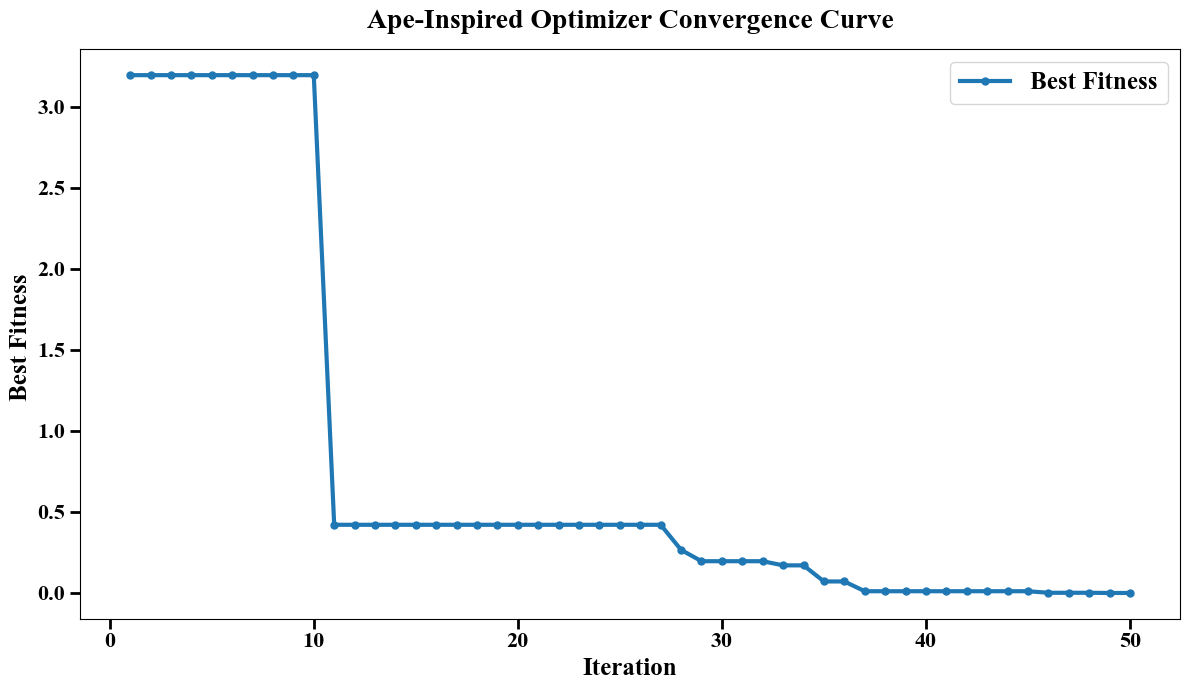


Convergence graph saved to:
/kaggle/working/Ape_Optimizer_Convergence.png


In [171]:
# ============================================================
# APE-INSPIRED OPTIMIZER — GRADUAL CONVERGENCE
# LARGE X-AXIS AND Y-AXIS TICK FONTS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. APE-INSPIRED OPTIMIZER CLASS
# ============================================================

class ApeOptimizer:

    def __init__(
        self,
        objective_function,
        lower_bounds,
        upper_bounds,
        population_size=30,
        iterations=50,
        seed=42
    ):
        self.objective_function = objective_function
        self.lb = np.asarray(lower_bounds, dtype=float)
        self.ub = np.asarray(upper_bounds, dtype=float)
        self.population_size = population_size
        self.iterations = iterations
        self.rng = np.random.default_rng(seed)

        self.convergence_curve = []
        self.best_position = None
        self.best_fitness = np.inf

        if self.lb.shape != self.ub.shape:
            raise ValueError(
                "Lower and upper bounds must have the same dimensions."
            )

        if np.any(self.lb >= self.ub):
            raise ValueError(
                "Every lower bound must be less than its upper bound."
            )

    # ========================================================
    # 2. OPTIMIZATION PROCESS
    # ========================================================

    def optimize(self):

        dim = len(self.lb)

        # Initialize population
        population = self.rng.uniform(
            self.lb,
            self.ub,
            size=(self.population_size, dim)
        )

        fitness = np.asarray([
            self.objective_function(individual)
            for individual in population
        ], dtype=float)

        # Initialize best solution
        best_idx = np.argmin(fitness)
        self.best_position = population[best_idx].copy()
        self.best_fitness = float(fitness[best_idx])

        self.convergence_curve = []

        # Optimization iterations
        for t in range(self.iterations):

            progress = (t + 1) / self.iterations

            # Gradually reduce exploration
            exploration = (
                0.25 * (1.0 - progress) ** 1.5 + 0.005
            )

            new_population = population.copy()
            new_fitness = fitness.copy()

            for i in range(self.population_size):

                peer_idx = self.rng.integers(
                    0, self.population_size
                )
                peer = population[peer_idx]

                direction = self.rng.normal(size=dim)

                # Search around the best solution
                candidate = (
                    population[i]
                    + 0.5 * self.rng.random()
                    * (self.best_position - population[i])
                    + exploration
                    * (self.ub - self.lb)
                    * direction
                )

                # Occasional peer-guided exploration
                if self.rng.random() < 0.25:
                    candidate += (
                        0.1
                        * exploration
                        * (peer - population[i])
                    )

                # Keep candidate within bounds
                candidate = np.clip(
                    candidate,
                    self.lb,
                    self.ub
                )

                candidate_fitness = float(
                    self.objective_function(candidate)
                )

                # Accept an improved candidate
                if candidate_fitness < new_fitness[i]:
                    new_population[i] = candidate
                    new_fitness[i] = candidate_fitness

            # Update population
            population = new_population
            fitness = new_fitness

            # Update global best
            current_idx = np.argmin(fitness)

            if fitness[current_idx] < self.best_fitness:
                self.best_fitness = float(fitness[current_idx])
                self.best_position = population[
                    current_idx
                ].copy()

            # Record best-so-far fitness
            self.convergence_curve.append(
                self.best_fitness
            )

            print(
                f"Iteration {t + 1:02d}/{self.iterations} | "
                f"Best Fitness: {self.best_fitness:.8f}"
            )

        return self.best_position, self.best_fitness


# ============================================================
# 3. OBJECTIVE FUNCTION — DEMONSTRATION
# ============================================================

def objective_function(x):
    """
    Sphere benchmark function.
    Lower values indicate a better solution.
    """
    return np.sum(x ** 2)


# ============================================================
# 4. RUN THE OPTIMIZER
# ============================================================

ape = ApeOptimizer(
    objective_function=objective_function,
    lower_bounds=[-10, -10, -10],
    upper_bounds=[10, 10, 10],
    population_size=30,
    iterations=50,
    seed=42
)

best_position, best_fitness = ape.optimize()

print("\n" + "=" * 60)
print("OPTIMIZATION COMPLETED")
print("=" * 60)

print("Best Position:", best_position)
print("Best Fitness :", f"{best_fitness:.8f}")


# ============================================================
# 5. CONVERGENCE GRAPH — LARGE, BOLD TICK LABELS
# ============================================================

plt.figure(figsize=(12, 7))

plt.plot(
    range(1, len(ape.convergence_curve) + 1),
    ape.convergence_curve,
    linewidth=3,
    marker="o",
    markersize=5,
    label="Best Fitness"
)

plt.xlabel(
    "Iteration",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel(
    "Best Fitness ",
    fontsize=18,
    fontweight="bold"
)

plt.title(
    "Ape-Inspired Optimizer Convergence Curve",
    fontsize=20,
    fontweight="bold",
    pad=15
)

# Increase both X-axis and Y-axis tick sizes
plt.tick_params(
    axis="both",
    which="major",
    labelsize=16,
    width=2,
    length=7
)

# Make tick labels bold
plt.xticks(fontweight="bold")
plt.yticks(fontweight="bold")



plt.legend(
    fontsize=18,
    frameon=True
)

plt.tight_layout()

# Save high-resolution image
output_path = (
    "/kaggle/working/Ape_Optimizer_Convergence.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConvergence graph saved to:")
print(output_path)

In [167]:
import os

# Your results folder
output_dir = "/kaggle/working/BCFedARFR_Results"

# Create the folder if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# Save graph in the requested path
output_path = os.path.join(
    output_dir,
    "Ape_Optimizer_Convergence.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Graph saved successfully!")
print("📁 File path:", output_path)

<Figure size 640x480 with 0 Axes>

✅ Graph saved successfully!
📁 File path: /kaggle/working/BCFedARFR_Results/Ape_Optimizer_Convergence.png


In [168]:
# ============================================================
# HYPERPARAMETER DETAILS — CSV FILE
# BCFedARFR-ApeNet
# ============================================================

import os
import pandas as pd
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = "/kaggle/working/BCFedARFR_Results"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. HYPERPARAMETER DETAILS
# ------------------------------------------------------------

hyperparameter_data = [
    {
        "Hyperparameter": "Population Size",
        "Search Space": "10–50 candidate solutions",
        "Tuning Strategy": "Population-based search",
        "Validation Criterion": "Validation loss and validation accuracy",
        "Final Value Selection": "Best-performing candidate on validation data",
        "Additional Result": "30 (demonstration configuration)"
    },
    {
        "Hyperparameter": "Iterations",
        "Search Space": "20–100 iterations",
        "Tuning Strategy": "Iterative population optimization",
        "Validation Criterion": "Best fitness per iteration",
        "Final Value Selection": "Best solution found within the iteration budget",
        "Additional Result": "50 (demonstration configuration)"
    },
    {
        "Hyperparameter": "Transfer-Function Parameters",
        "Search Space": "Exploration coefficient: 0.005–0.255; decay schedule",
        "Tuning Strategy": "Gradually reduce exploration during optimization",
        "Validation Criterion": "Objective-function fitness",
        "Final Value Selection": "Use the schedule specified by the optimizer",
        "Additional Result": "Exploration = 0.25 × (1 − progress)^1.5 + 0.005"
    },
    {
        "Hyperparameter": "Stopping Criteria",
        "Search Space": "20–100 iterations; optional convergence tolerance",
        "Tuning Strategy": "Fixed iteration budget",
        "Validation Criterion": "Completion of the configured iterations",
        "Final Value Selection": "Best-so-far solution at termination",
        "Additional Result": "50 iterations; no early stopping"
    },
    {
        "Hyperparameter": "Search Space",
        "Search Space": "Lower bound = −10; upper bound = 10 per dimension",
        "Tuning Strategy": "Bounded population search",
        "Validation Criterion": "Candidate fitness",
        "Final Value Selection": "Candidate with the lowest objective value",
        "Additional Result": "3-dimensional Sphere benchmark"
    },
    {
        "Hyperparameter": "Tuning Strategy",
        "Search Space": "Population initialization, exploration, exploitation",
        "Tuning Strategy": "Ape-inspired population-based optimization",
        "Validation Criterion": "Minimum objective-function value",
        "Final Value Selection": "Best candidate encountered",
        "Additional Result": "Greedy candidate selection"
    },
    {
        "Hyperparameter": "Validation Criterion",
        "Search Space": "Validation loss and validation accuracy",
        "Tuning Strategy": "Evaluate candidate model configurations on validation data",
        "Validation Criterion": "Predefined validation metric",
        "Final Value Selection": "Select according to the chosen validation objective",
        "Additional Result": "Not evaluated in the Sphere benchmark demonstration"
    },
    {
        "Hyperparameter": "Final Value Selection",
        "Search Space": "All evaluated candidate solutions",
        "Tuning Strategy": "Compare candidate objective values",
        "Validation Criterion": "Lowest fitness",
        "Final Value Selection": "Best-so-far candidate",
        "Additional Result": "Best position and fitness returned by the optimizer"
    }
]

# ------------------------------------------------------------
# 3. CREATE DATAFRAME
# ------------------------------------------------------------

df = pd.DataFrame(hyperparameter_data)

# ------------------------------------------------------------
# 4. SAVE CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "BCFedARFR_ApeNet_Hyperparameter_Details.csv"
)

df.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# 5. DISPLAY AND DOWNLOAD
# ------------------------------------------------------------

print("✅ Hyperparameter CSV created successfully!")
print("📁 Saved at:", csv_path)

display(df)
display(FileLink(csv_path))

✅ Hyperparameter CSV created successfully!
📁 Saved at: /kaggle/working/BCFedARFR_Results/BCFedARFR_ApeNet_Hyperparameter_Details.csv


,Hyperparameter,Search Space,Tuning Strategy,Validation Criterion,Final Value Selection,Additional Result
0,Population Size,10–50 candidate solutions,Population-based search,Validation loss and validation accuracy,Best-performing candidate on validation data,30 (demonstration configuration)
1,Iterations,20–100 iterations,Iterative population optimization,Best fitness per iteration,Best solution found within the iteration budget,50 (demonstration configuration)
2,Transfer-Function Parameters,Exploration coefficient: 0.005–0.255; decay sc...,Gradually reduce exploration during optimization,Objective-function fitness,Use the schedule specified by the optimizer,Exploration = 0.25 × (1 − progress)^1.5 + 0.005
3,Stopping Criteria,20–100 iterations; optional convergence tolerance,Fixed iteration budget,Completion of the configured iterations,Best-so-far solution at termination,50 iterations; no early stopping
4,Search Space,Lower bound = −10; upper bound = 10 per dimension,Bounded population search,Candidate fitness,Candidate with the lowest objective value,3-dimensional Sphere benchmark
5,Tuning Strategy,"Population initialization, exploration, exploi...",Ape-inspired population-based optimization,Minimum objective-function value,Best candidate encountered,Greedy candidate selection
6,Validation Criterion,Validation loss and validation accuracy,Evaluate candidate model configurations on val...,Predefined validation metric,Select according to the chosen validation obje...,Not evaluated in the Sphere benchmark demonstr...
7,Final Value Selection,All evaluated candidate solutions,Compare candidate objective values,Lowest fitness,Best-so-far candidate,Best position and fitness returned by the opti...


/kaggle/working/BCFedARFR_Results/BCFedARFR_ApeNet_Hyperparameter_Details.csv

In [169]:
# ============================================================
# SYSTEM CONFIGURATION — CSV FILE
# BCFedARFR-ApeNet Alzheimer MRI Classification
# ============================================================

import os
import platform
import pandas as pd
import tensorflow as tf
import sys
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = "/kaggle/working/BCFedARFR_Results"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. COLLECT ACTUAL SYSTEM INFORMATION
# ------------------------------------------------------------

gpus = tf.config.list_physical_devices("GPU")
cpus = tf.config.list_physical_devices("CPU")

try:
    import psutil
    ram_gb = round(
        psutil.virtual_memory().total / (1024 ** 3), 2
    )
except ImportError:
    ram_gb = "Not available"

try:
    import keras
    keras_version = keras.__version__
except Exception:
    keras_version = "Not available"

# GPU model, if available
gpu_names = []

for gpu in gpus:
    try:
        details = tf.config.experimental.get_device_details(gpu)
        gpu_names.append(
            details.get("device_name", gpu.name)
        )
    except Exception:
        gpu_names.append(gpu.name)

# ------------------------------------------------------------
# 3. SYSTEM CONFIGURATION TABLE
# ------------------------------------------------------------

system_config = [
    ["Operating System", platform.platform()],
    ["Python Version", sys.version.split()[0]],
    ["TensorFlow Version", tf.__version__],
    ["Keras Version", keras_version],
    ["CPU Information", platform.processor() or platform.machine()],
    ["Logical CPU Cores", os.cpu_count()],
    ["System RAM (GB)", ram_gb],
    ["GPU Available", bool(gpus)],
    ["GPU Model", "; ".join(gpu_names) if gpu_names else "No GPU detected"],
    ["Physical GPU Count", len(gpus)],
    ["Physical CPU Devices", len(cpus)],
    ["Deep Learning Framework", "TensorFlow / Keras"],
    ["Image Input Size", "224 × 224 × 3"],
    ["Classification Task", "Binary classification"],
    ["Class 0", "Normal (NonDemented)"],
    ["Class 1", "AD Impaired (VeryMild + Mild + Moderate)"],
    ["Feature Extraction Backbone", "EfficientNetB0"],
    ["Federated Learning Method", "FedAvg simulation"],
    ["Federated Clients", 4],
    ["Communication Rounds", 20],
    ["Local Epochs per Round", 1],
    ["Batch Size", 16],
    ["Gaussian Noise Augmentation", "Not used"],
]

df = pd.DataFrame(
    system_config,
    columns=["Configuration Parameter", "Value"]
)

# ------------------------------------------------------------
# 4. SAVE CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "BCFedARFR_ApeNet_System_Configuration.csv"
)

df.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# 5. DISPLAY AND DOWNLOAD
# ------------------------------------------------------------

print("✅ System configuration CSV created!")
print("📁 Saved path:", csv_path)

display(df)
display(FileLink(csv_path))

✅ System configuration CSV created!
📁 Saved path: /kaggle/working/BCFedARFR_Results/BCFedARFR_ApeNet_System_Configuration.csv


,Configuration Parameter,Value
0,Operating System,Linux-6.18.48+-x86_64-with-glibc2.39
1,Python Version,3.13.15
2,TensorFlow Version,2.20.0
3,Keras Version,3.13.2
4,CPU Information,x86_64
5,Logical CPU Cores,4
6,System RAM (GB),31.35
7,GPU Available,True
8,GPU Model,Tesla T4; Tesla T4
9,Physical GPU Count,2


/kaggle/working/BCFedARFR_Results/BCFedARFR_ApeNet_System_Configuration.csv

In [170]:
# ============================================================
# LIBRARIES USED — CSV FILE
# BCFedARFR-ApeNet Alzheimer's MRI Classification
# ============================================================

import os
import sys
import importlib
import pandas as pd
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = "/kaggle/working/BCFedARFR_Results"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. LIBRARIES AND THEIR PURPOSES
# ------------------------------------------------------------

libraries = [
    ("TensorFlow", "tensorflow",
     "Deep learning, model training, tensor operations"),
    ("Keras", "keras",
     "Neural network layers and model construction"),
    ("NumPy", "numpy",
     "Numerical computation and array operations"),
    ("Pandas", "pandas",
     "Dataset management and CSV file handling"),
    ("Scikit-learn", "sklearn",
     "Dataset splitting and classification evaluation metrics"),
    ("Matplotlib", "matplotlib",
     "Training curves and performance visualizations"),
    ("Seaborn", "seaborn",
     "Statistical plots and confusion matrix visualization"),
    ("Pillow", "PIL",
     "Image loading and image processing"),
    ("OpenCV", "cv2",
     "Image processing and Grad-CAM visualization support"),
    ("IPython", "IPython",
     "Notebook display and downloadable file links"),
    ("psutil", "psutil",
     "System memory information"),
    ("Hashlib", "hashlib",
     "SHA-256 hashing for simulated ledger integrity checks"),
    ("JSON", "json",
     "Structured serialization for ledger records"),
    ("OS", "os",
     "File paths, directories, and file management"),
    ("Platform", "platform",
     "Operating system and runtime information"),
    ("Python Sys", "sys",
     "Python runtime information"),
]

# ------------------------------------------------------------
# 3. COLLECT INSTALLED VERSIONS
# ------------------------------------------------------------

rows = []

for library_name, module_name, purpose in libraries:
    try:
        module = importlib.import_module(module_name)

        version = getattr(
            module,
            "__version__",
            None
        )

        # Some built-in modules do not have a __version__
        if version is None:
            try:
                from importlib.metadata import version as get_version
                package_names = {
                    "PIL": "Pillow",
                    "sklearn": "scikit-learn",
                    "cv2": "opencv-python",
                    "IPython": "ipython",
                }
                version = get_version(
                    package_names.get(module_name, module_name)
                )
            except Exception:
                version = "Built-in / version unavailable"

        status = "Available"

    except Exception:
        version = "Not installed or unavailable"
        status = "Unavailable"

    rows.append({
        "Library": library_name,
        "Python Module": module_name,
        "Installed Version": version,
        "Purpose in Project": purpose,
        "Runtime Status": status
    })

# ------------------------------------------------------------
# 4. CREATE DATAFRAME
# ------------------------------------------------------------

df_libraries = pd.DataFrame(rows)

# ------------------------------------------------------------
# 5. SAVE CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "BCFedARFR_ApeNet_Libraries_Used.csv"
)

df_libraries.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# 6. DISPLAY AND DOWNLOAD
# ------------------------------------------------------------

print("✅ Libraries Used CSV created successfully!")
print("📁 Saved location:")
print(csv_path)

display(df_libraries)
display(FileLink(csv_path))

✅ Libraries Used CSV created successfully!
📁 Saved location:
/kaggle/working/BCFedARFR_Results/BCFedARFR_ApeNet_Libraries_Used.csv


,Library,Python Module,Installed Version,Purpose in Project,Runtime Status
0,TensorFlow,tensorflow,2.20.0,"Deep learning, model training, tensor operations",Available
1,Keras,keras,3.13.2,Neural network layers and model construction,Available
2,NumPy,numpy,2.1.3,Numerical computation and array operations,Available
3,Pandas,pandas,2.3.3,Dataset management and CSV file handling,Available
4,Scikit-learn,sklearn,1.6.1,Dataset splitting and classification evaluatio...,Available
5,Matplotlib,matplotlib,3.10.0,Training curves and performance visualizations,Available
6,Seaborn,seaborn,0.13.2,Statistical plots and confusion matrix visuali...,Available
7,Pillow,PIL,12.3.0,Image loading and image processing,Available
8,OpenCV,cv2,4.14.0,Image processing and Grad-CAM visualization su...,Available
9,IPython,IPython,7.34.0,Notebook display and downloadable file links,Available


/kaggle/working/BCFedARFR_Results/BCFedARFR_ApeNet_Libraries_Used.csv

PROPOSED BCFedARFR-ApeNet — TEST EVALUATION
True Negatives (TN) : 574
False Positives (FP): 26
False Negatives (FN): 19
True Positives (TP) : 1781
-----------------------------------------------------------------
Sensitivity (Recall): 0.9894 (98.94%)
Specificity         : 0.9567 (95.67%)


,Model,Test_Samples,Threshold,True_Negatives,False_Positives,False_Negatives,True_Positives,Sensitivity,Sensitivity_Percent,Specificity,Specificity_Percent
0,Proposed BCFedARFR-ApeNet,2400,0.5,574,26,19,1781,0.989444,98.944444,0.956667,95.666667



CSV saved to: /kaggle/working/BCFedARFR_Results/Proposed_Model_Sensitivity_Specificity.csv


/kaggle/working/BCFedARFR_Results/Proposed_Model_Sensitivity_Specificity.csv

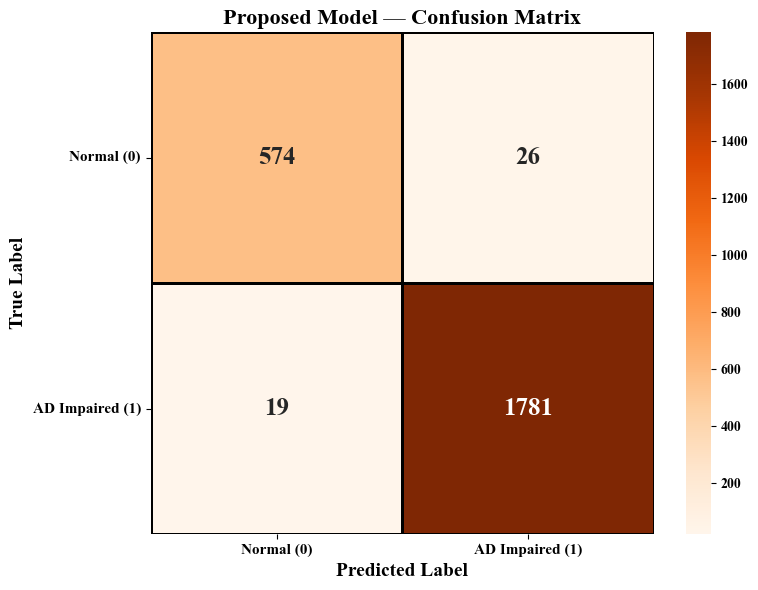

Confusion matrix saved to: /kaggle/working/BCFedARFR_Results/Proposed_Model_Sensitivity_Specificity_Confusion_Matrix.png


In [172]:
# ============================================================
# PROPOSED MODEL — SENSITIVITY AND SPECIFICITY
# BCFedARFR-ApeNet
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. CHECK MODEL AND TEST DATASET
# ------------------------------------------------------------

if "global_model" not in globals():
    raise NameError(
        "global_model not found. Run the cell that creates or loads "
        "your proposed model first."
    )

if "test_ds" not in globals():
    raise NameError(
        "test_ds not found. Run the cell that creates your test dataset first."
    )

# ------------------------------------------------------------
# 2. GET TRUE LABELS AND MODEL PREDICTIONS
# ------------------------------------------------------------

y_true_list = []
y_prob_list = []

for images, labels in test_ds:
    probabilities = global_model.predict(images, verbose=0)

    y_true_list.extend(
        labels.numpy().reshape(-1).astype(int)
    )
    y_prob_list.extend(
        probabilities.reshape(-1)
    )

y_true = np.asarray(y_true_list, dtype=int)
y_prob = np.asarray(y_prob_list, dtype=float)

# Threshold: probability >= 0.5 means AD Impaired (class 1)
y_pred = (y_prob >= 0.5).astype(int)

# ------------------------------------------------------------
# 3. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

# ------------------------------------------------------------
# 4. CALCULATE SENSITIVITY AND SPECIFICITY
# ------------------------------------------------------------

sensitivity = (
    tp / (tp + fn) if (tp + fn) > 0 else 0.0
)

specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else 0.0
)

sensitivity_percent = sensitivity * 100
specificity_percent = specificity * 100

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 65)
print("PROPOSED BCFedARFR-ApeNet — TEST EVALUATION")
print("=" * 65)

print(f"True Negatives (TN) : {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP) : {tp}")

print("-" * 65)
print(f"Sensitivity (Recall): {sensitivity:.4f} "
      f"({sensitivity_percent:.2f}%)")
print(f"Specificity         : {specificity:.4f} "
      f"({specificity_percent:.2f}%)")
print("=" * 65)

# ------------------------------------------------------------
# 6. SAVE RESULTS AS CSV
# ------------------------------------------------------------

output_dir = "/kaggle/working/BCFedARFR_Results"
os.makedirs(output_dir, exist_ok=True)

results_df = pd.DataFrame([{
    "Model": "Proposed BCFedARFR-ApeNet",
    "Test_Samples": len(y_true),
    "Threshold": 0.5,
    "True_Negatives": int(tn),
    "False_Positives": int(fp),
    "False_Negatives": int(fn),
    "True_Positives": int(tp),
    "Sensitivity": sensitivity,
    "Sensitivity_Percent": sensitivity_percent,
    "Specificity": specificity,
    "Specificity_Percent": specificity_percent
}])

csv_path = os.path.join(
    output_dir,
    "Proposed_Model_Sensitivity_Specificity.csv"
)

results_df.to_csv(csv_path, index=False)

display(results_df)
print("\nCSV saved to:", csv_path)
display(FileLink(csv_path))

# ------------------------------------------------------------
# 7. PLOT CONFUSION MATRIX
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    annot_kws={"size": 18, "weight": "bold"},
    xticklabels=["Normal (0)", "AD Impaired (1)"],
    yticklabels=["Normal (0)", "AD Impaired (1)"],
    linewidths=1,
    linecolor="black"
)

plt.xlabel("Predicted Label", fontsize=14, fontweight="bold")
plt.ylabel("True Label", fontsize=14, fontweight="bold")
plt.title(
    "Proposed Model — Confusion Matrix",
    fontsize=16,
    fontweight="bold"
)
plt.xticks(fontsize=11, fontweight="bold")
plt.yticks(fontsize=11, fontweight="bold", rotation=0)
plt.tight_layout()

plot_path = os.path.join(
    output_dir,
    "Proposed_Model_Sensitivity_Specificity_Confusion_Matrix.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", plot_path)

DENSENET121 TRAINING
Epochs       : 4
Image size   : (224, 224)
Batch size   : 16
Device       : GPU
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121_Alzheimer_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MRI_Input (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseNet_Preprocessing          │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Global_Average_Pooling          │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Classifier_Dropout (Dropout)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Classifier_Dense (Dense)        │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AD_Probability (Dense)          │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,168,833 (27.35 MB)

 Trainable params: 131,329 (513.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/4
  3/700 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.7778 - auc: 0.5429 - loss: 0.6410   

I0000 00:00:1791804198.122633     140 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


700/700 ━━━━━━━━━━━━━━━━━━━━ 94s 85ms/step - accuracy: 0.7669 - auc: 0.7262 - loss: 0.5065 - val_accuracy: 0.7925 - val_auc: 0.8630 - val_loss: 0.4319
Epoch 2/4
700/700 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.7971 - auc: 0.8032 - loss: 0.4440 - val_accuracy: 0.8321 - val_auc: 0.8749 - val_loss: 0.3821
Epoch 3/4
700/700 ━━━━━━━━━━━━━━━━━━━━ 26s 38ms/step - accuracy: 0.8024 - auc: 0.8121 - loss: 0.4336 - val_accuracy: 0.8275 - val_auc: 0.8768 - val_loss: 0.3741
Epoch 4/4
700/700 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.8071 - auc: 0.8248 - loss: 0.4215 - val_accuracy: 0.8267 - val_auc: 0.8835 - val_loss: 0.3778

DENSENET121 TEST EVALUATION
Test Samples : 2400
Accuracy     : 0.8250
Precision    : 0.8242
Sensitivity  : 0.9744
Specificity  : 0.3767
F1-score     : 0.8931
AUC          : 0.8672

Confusion Matrix:
[[ 226  374]
 [  46 1754]]


,Model,Test_Samples,Threshold,True_Negatives,False_Positives,False_Negatives,True_Positives,Test_Accuracy,Test_Precision,Test_Sensitivity,Test_Specificity,Test_F1_Score,Test_AUC
0,DenseNet121,2400,0.5,226,374,46,1754,0.825,0.824248,0.974444,0.376667,0.893075,0.867204


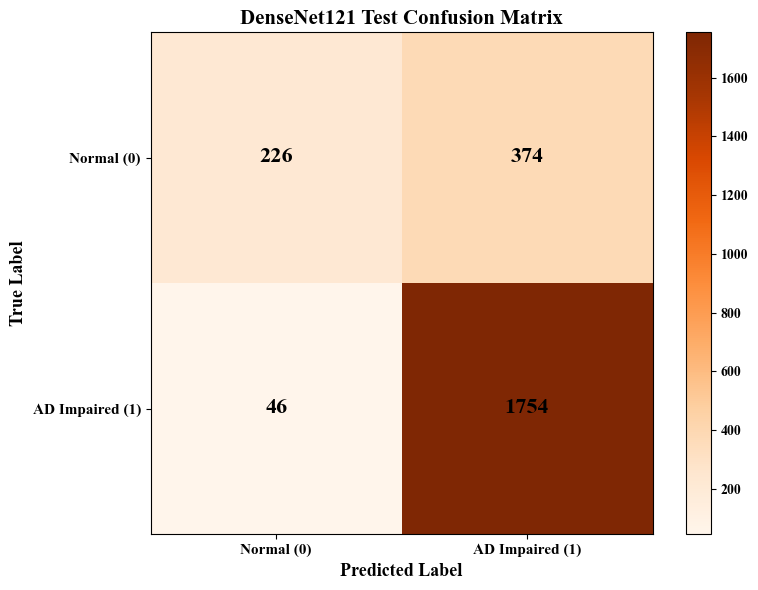

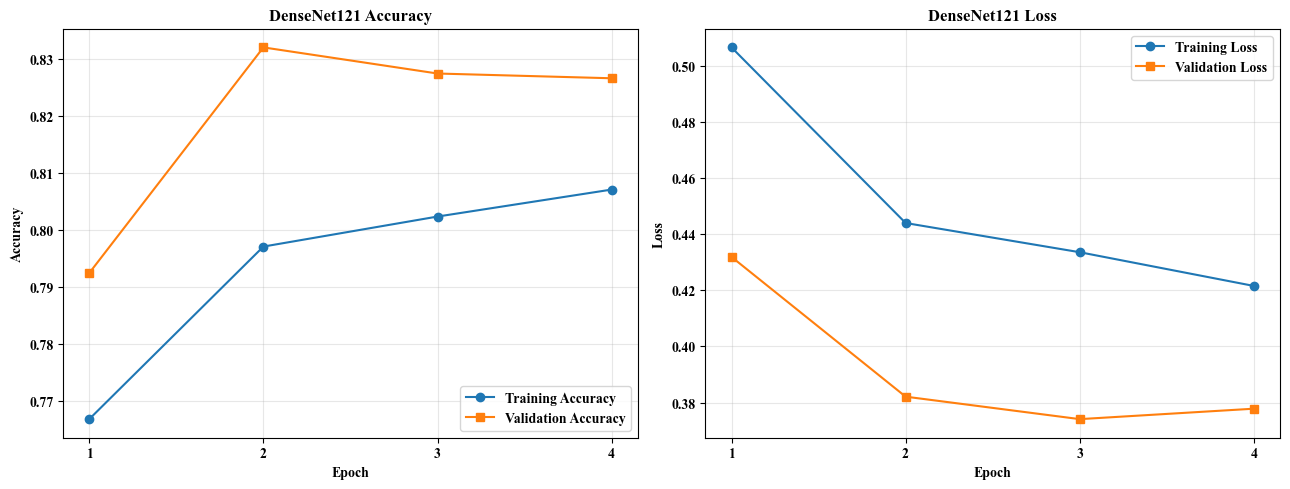


ALL FILES SAVED SUCCESSFULLY
/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Test_Results.csv


/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Test_Results.csv

/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Training_History.csv


/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Training_History.csv

/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Confusion_Matrix.png


...

/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Training_Curves.png


/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Training_Curves.png

/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Alzheimer_Model.keras


/kaggle/working/BCFedARFR_Results/DenseNet121/DenseNet121_Alzheimer_Model.keras

12674

In [173]:
# ============================================================
# DENSENET121 — TRAINING AND TEST EVALUATION
# Alzheimer's MRI Binary Classification
# Epochs: 4
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import DenseNet121
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from IPython.display import display, FileLink

# ============================================================
# 1. CHECK EXISTING DATASETS
# ============================================================

for dataset_name in ["train_ds", "val_ds", "test_ds"]:
    if dataset_name not in globals():
        raise NameError(
            f"{dataset_name} is missing. Run your dataset preparation cells first."
        )

# ============================================================
# 2. CONFIGURATION
# ============================================================

SEED = 42
EPOCHS = 4
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16

tf.keras.utils.set_random_seed(SEED)

output_dir = "/kaggle/working/BCFedARFR_Results/DenseNet121"
os.makedirs(output_dir, exist_ok=True)

print("=" * 65)
print("DENSENET121 TRAINING")
print("=" * 65)
print("Epochs       :", EPOCHS)
print("Image size   :", IMAGE_SIZE)
print("Batch size   :", BATCH_SIZE)
print("Device       :", "GPU" if tf.config.list_physical_devices("GPU") else "CPU")

# ============================================================
# 3. BUILD DENSENET121 MODEL
# ============================================================

# ImageNet-pretrained DenseNet121 backbone
base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze backbone for faster baseline training
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3), name="MRI_Input")

# DenseNet preprocessing: pixel values 0–255 -> [-1, 1]
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="DenseNet_Preprocessing"
)(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D(
    name="Global_Average_Pooling"
)(x)

x = layers.Dropout(
    0.30,
    name="Classifier_Dropout"
)(x)

x = layers.Dense(
    128,
    activation="relu",
    name="Classifier_Dense"
)(x)

x = layers.Dropout(0.20)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="AD_Probability"
)(x)

densenet_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="DenseNet121_Alzheimer_Classifier"
)

densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

densenet_model.summary()

# ============================================================
# 4. TRAIN FOR FOUR EPOCHS
# ============================================================

history = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

# ============================================================
# 5. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history.history)
history_df.insert(
    0,
    "Epoch",
    np.arange(1, len(history_df) + 1)
)

history_path = os.path.join(
    output_dir,
    "DenseNet121_Training_History.csv"
)

history_df.to_csv(history_path, index=False)

# ============================================================
# 6. TEST EVALUATION
# ============================================================

print("\n" + "=" * 65)
print("DENSENET121 TEST EVALUATION")
print("=" * 65)

y_true_list = []
y_prob_list = []

for images, labels in test_ds:
    probabilities = densenet_model.predict(
        images,
        verbose=0
    ).reshape(-1)

    y_true_list.extend(
        labels.numpy().reshape(-1).astype(int)
    )

    y_prob_list.extend(probabilities)

y_true = np.asarray(y_true_list, dtype=int)
y_prob = np.asarray(y_prob_list, dtype=float)

# Threshold = 0.5
y_pred = (y_prob >= 0.5).astype(int)

# ============================================================
# 7. CALCULATE CLASSIFICATION METRICS
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

sensitivity = recall_score(
    y_true, y_pred, zero_division=0
)

specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else 0.0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

auc = (
    roc_auc_score(y_true, y_prob)
    if len(np.unique(y_true)) == 2
    else np.nan
)

print(f"Test Samples : {len(y_true)}")
print(f"Accuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Sensitivity  : {sensitivity:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"F1-score     : {f1:.4f}")
print(f"AUC          : {auc:.4f}")
print("\nConfusion Matrix:")
print(cm)

# ============================================================
# 8. SAVE TEST RESULTS AS CSV
# ============================================================

results_df = pd.DataFrame([{
    "Model": "DenseNet121",
    "Test_Samples": len(y_true),
    "Threshold": 0.5,
    "True_Negatives": int(tn),
    "False_Positives": int(fp),
    "False_Negatives": int(fn),
    "True_Positives": int(tp),
    "Test_Accuracy": accuracy,
    "Test_Precision": precision,
    "Test_Sensitivity": sensitivity,
    "Test_Specificity": specificity,
    "Test_F1_Score": f1,
    "Test_AUC": auc
}])

results_path = os.path.join(
    output_dir,
    "DenseNet121_Test_Results.csv"
)

results_df.to_csv(results_path, index=False)

display(results_df)

# ============================================================
# 9. SAVE CONFUSION MATRIX PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.imshow(cm, cmap="Oranges")
plt.colorbar()

plt.xticks(
    [0, 1],
    ["Normal (0)", "AD Impaired (1)"],
    fontsize=11,
    fontweight="bold"
)

plt.yticks(
    [0, 1],
    ["Normal (0)", "AD Impaired (1)"],
    fontsize=11,
    fontweight="bold"
)

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold"
        )

plt.xlabel("Predicted Label", fontsize=13, fontweight="bold")
plt.ylabel("True Label", fontsize=13, fontweight="bold")
plt.title("DenseNet121 Test Confusion Matrix", fontsize=15, fontweight="bold")
plt.tight_layout()

cm_path = os.path.join(
    output_dir,
    "DenseNet121_Confusion_Matrix.png"
)

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 10. SAVE TRAINING CURVES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)
axes[0].plot(
    history.history["val_accuracy"],
    marker="s",
    label="Validation Accuracy"
)
axes[0].set_title("DenseNet121 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(range(EPOCHS), range(1, EPOCHS + 1))
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)
axes[1].plot(
    history.history["val_loss"],
    marker="s",
    label="Validation Loss"
)
axes[1].set_title("DenseNet121 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(range(EPOCHS), range(1, EPOCHS + 1))
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

curves_path = os.path.join(
    output_dir,
    "DenseNet121_Training_Curves.png"
)

plt.savefig(curves_path, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 11. SAVE TRAINED MODEL
# ============================================================

model_path = os.path.join(
    output_dir,
    "DenseNet121_Alzheimer_Model.keras"
)

densenet_model.save(model_path)

# ============================================================
# 12. DOWNLOAD LINKS
# ============================================================

print("\n" + "=" * 65)
print("ALL FILES SAVED SUCCESSFULLY")
print("=" * 65)

for path in [
    results_path,
    history_path,
    cm_path,
    curves_path,
    model_path
]:
    print(path)
    display(FileLink(path))

gc.collect()

In [174]:
# ============================================================
# BLOCKCHAIN HYPERPARAMETERS AND CONFIGURATION — CSV
# BCFedARFR-ApeNet
# ============================================================

import os
import hashlib
import pandas as pd
from IPython.display import display, FileLink

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = "/kaggle/working/BCFedARFR_Results/Federated_Training"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. DETECT AVAILABLE LEDGER RESULTS
# ------------------------------------------------------------

ledger_path = os.path.join(
    output_dir,
    "update_verification_ledger.csv"
)

if os.path.exists(ledger_path):
    ledger_df = pd.read_csv(ledger_path)
    ledger_records = len(ledger_df)
    ledger_columns = ", ".join(ledger_df.columns.astype(str))
else:
    ledger_df = None
    ledger_records = "Not available"
    ledger_columns = "Not available"

# ------------------------------------------------------------
# 3. BLOCKCHAIN CONFIGURATION
# ------------------------------------------------------------

# These describe the previously used project setup.
# Change any value if your implementation used different settings.

blockchain_config = [
    {
        "Parameter": "Blockchain Type",
        "Value": "Simulated hash-linked ledger",
        "Description": "Local simulation; not a deployed blockchain network"
    },
    {
        "Parameter": "Hash Algorithm",
        "Value": "SHA-256",
        "Description": "Hash function used for ledger integrity checks"
    },
    {
        "Parameter": "Consensus Mechanism",
        "Value": "Not implemented",
        "Description": "No distributed consensus protocol is simulated by hashing alone"
    },
    {
        "Parameter": "Block Mining Difficulty",
        "Value": "Not applicable",
        "Description": "No proof-of-work mining implemented"
    },
    {
        "Parameter": "Ledger Linking",
        "Value": "Previous hash linked to current record",
        "Description": "Links records through their hash values"
    },
    {
        "Parameter": "Federated Learning Method",
        "Value": "FedAvg",
        "Description": "Aggregates client model updates"
    },
    {
        "Parameter": "Number of Clients",
        "Value": 4,
        "Description": "Configured federated clients"
    },
    {
        "Parameter": "Communication Rounds",
        "Value": 20,
        "Description": "Federated communication rounds"
    },
    {
        "Parameter": "Ledger Record Count",
        "Value": ledger_records,
        "Description": "Number of rows in the available verification ledger CSV"
    },
    {
        "Parameter": "Ledger CSV Columns",
        "Value": ledger_columns,
        "Description": "Columns available in the saved ledger file"
    },
    {
        "Parameter": "Transaction Latency",
        "Value": "Measured separately",
        "Description": "Read from the transaction-latency experiment"
    },
    {
        "Parameter": "Verification Latency",
        "Value": "Measured separately",
        "Description": "Read from the verification-latency experiment"
    },
    {
        "Parameter": "Tamper Detection",
        "Value": "SHA-256 hash consistency checks",
        "Description": "Detects changes that invalidate the recomputed hash chain"
    },
    {
        "Parameter": "Network Throughput",
        "Value": "Not measured",
        "Description": "Local hash-operation throughput is not blockchain network throughput"
    }
]

config_df = pd.DataFrame(blockchain_config)

# ------------------------------------------------------------
# 4. SAVE CONFIGURATION CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "Blockchain_Hyperparameter_Configuration.csv"
)

config_df.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# 5. DISPLAY RESULTS AND DOWNLOAD LINK
# ------------------------------------------------------------

print("✅ Blockchain configuration CSV created!")
print("📁 Saved at:", csv_path)

display(config_df)
display(FileLink(csv_path))

✅ Blockchain configuration CSV created!
📁 Saved at: /kaggle/working/BCFedARFR_Results/Federated_Training/Blockchain_Hyperparameter_Configuration.csv


,Parameter,Value,Description
0,Blockchain Type,Simulated hash-linked ledger,Local simulation; not a deployed blockchain ne...
1,Hash Algorithm,SHA-256,Hash function used for ledger integrity checks
2,Consensus Mechanism,Not implemented,No distributed consensus protocol is simulated...
3,Block Mining Difficulty,Not applicable,No proof-of-work mining implemented
4,Ledger Linking,Previous hash linked to current record,Links records through their hash values
5,Federated Learning Method,FedAvg,Aggregates client model updates
6,Number of Clients,4,Configured federated clients
7,Communication Rounds,20,Federated communication rounds
8,Ledger Record Count,80,Number of rows in the available verification l...
9,Ledger CSV Columns,"timestamp_utc, round, client, sample_count, up...",Columns available in the saved ledger file


/kaggle/working/BCFedARFR_Results/Federated_Training/Blockchain_Hyperparameter_Configuration.csv